# 07. Final publication results

**Purpose.** To compare all finalised models on a single locked sample of new learners and to separate quality, calibration, robustness and cost. The notebook uses the completed predictions and computations of the preceding stages; no models are trained or reselected here.

The primary result concerns RoboMission: the first run at the first visit to a known task. The prediction of stochastic models averages three fixed seeds; the two simple baselines are deterministic. The school cCTt dataset is treated as a separate problem. In all tables the model order is the same and is determined by locked-test LogLoss solely for the presentation of results.

In [1]:
from pathlib import Path
import json
import hashlib


def verify_frozen_training_source(root: Path) -> None:
    """Allow exact-source reproduction without pretending a viewed test is new."""
    boundary = root / "Protocol/test_evaluation_boundary.json"
    if not boundary.exists():
        return
    frozen_sources = json.loads(
        (root / "Protocol/frozen_training_sources.json").read_text()
    )
    for filename, expected in frozen_sources["notebooks"].items():
        notebook = json.loads((root / "Notebooks" / filename).read_text())
        source = "\n\n".join(
            "".join(cell["source"])
            for cell in notebook["cells"]
            if cell["cell_type"] == "code"
        )
        observed = hashlib.sha256(source.encode()).hexdigest()
        assert (
            observed == expected
        ), "Training source changed after the test was opened."


import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown

def resolve_project_root(start: Path) -> Path:
    """Locate the project root without depending on the notebook launch directory."""
    candidates = [start, start.parent, start.parent.parent]
    for candidate in candidates:
        required = [
            candidate / "Data",
            candidate / "Protocol",
            candidate / "Results",
        ]
        if all(path.exists() for path in required):
            return candidate
    raise FileNotFoundError(
        "Project root was not found. Run the notebook from the ALPHA project "
        "directory or its Notebooks subdirectory."
    )


ROOT = resolve_project_root(Path.cwd())
for directory in [ROOT / "Figures", ROOT / "Tables", ROOT / "Results"]:
    directory.mkdir(parents=True, exist_ok=True)

SEED = 20260923
rng = np.random.default_rng(SEED)
font_names = {font.name for font in font_manager.fontManager.ttflist}
FONT_PREFERENCES = ["Times New Roman", "Liberation Serif", "DejaVu Serif"]
FONT = next(
    (font_name for font_name in FONT_PREFERENCES if font_name in font_names),
    "serif",
)
FONT_SIZE, TITLE_SIZE, FIGURE_DPI = 18, 20, 350
mpl.rcParams.update(
    {
        "font.family": FONT,
        "font.size": 18,
        "axes.titlesize": 20,
        "axes.labelsize": 18,
        "xtick.labelsize": 18,
        "ytick.labelsize": 18,
        "legend.fontsize": 18,
        "figure.dpi": 350,
        "savefig.dpi": 350,
        "axes.unicode_minus": True,
        "mathtext.fontset": "stix",
    }
)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)


def table(frame: pd.DataFrame, caption: str, name: str) -> None:
    """Display a complete DataFrame using Jupyter's default table styling."""
    frame.to_csv(ROOT / "Tables" / f"{name}.csv", index=False)
    with pd.option_context(
        "display.max_rows",
        None,
        "display.max_columns",
        None,
        "display.max_colwidth",
        None,
        "display.width",
        None,
    ):
        display(Markdown(caption))
        display(frame.reset_index(drop=True).round(5))


def save_figure(fig: mpl.figure.Figure, name: str) -> None:
    """Save at 350 dpi after checking the font contract on visible text."""
    from matplotlib.text import Text

    fig.canvas.draw()
    for text in fig.findobj(match=Text):
        if text.get_visible() and text.get_text():
            assert 18 <= text.get_fontsize() <= 20
            assert text.get_fontfamily() == [FONT]
    fig.savefig(
        ROOT / "Figures" / f"{name}.png",
        dpi=FIGURE_DPI,
        bbox_inches="tight",
    )
    fig.savefig(
        ROOT / "Figures" / f"{name}.pdf",
        dpi=FIGURE_DPI,
        bbox_inches="tight",
    )


import joblib

verify_frozen_training_source(ROOT)
analysis_path = ROOT / "Results/06_analysis_bundle.joblib"
assert analysis_path.exists(), (
    "Run 06_Model_Analysis.ipynb successfully before publication synthesis."
)
analysis = joblib.load(analysis_path)
frozen = json.loads((ROOT / "Protocol/frozen_proposed_model.json").read_text())
assert (
    analysis["feature_revision"]
    == frozen["feature_revision"]
    == "event_prefix_v2"
)
assert (
    hashlib.sha256(json.dumps(frozen, sort_keys=True).encode()).hexdigest()
    == analysis["frozen_signature"]
)
probabilities = pd.read_pickle(ROOT / "Results/06_test_probabilities.pkl")
publication_order = (
    analysis["primary"].sort_values("LogLoss", kind="stable").Model.tolist()
)
identifiers = ["Model", "Split", "n"]


def publication_table(frame: pd.DataFrame, caption: str, name: str) -> None:
    """Keep every model and every declared value in the common publication order."""
    assert frame.Model.is_unique
    assert set(frame.Model) == set(publication_order)
    selected = frame.set_index("Model").loc[publication_order].reset_index()
    assert selected[identifiers].notna().all().all()
    table(selected, caption, name)

## Primary quality

LogLoss evaluates the probabilistic prediction, and the 95% intervals are obtained by bootstrap over learners. AUROC and AP are reported in a separate table to preserve readability and to avoid mixing different properties of the prediction.

In [2]:
publication_table(
    analysis["primary"],
    "Primary metric: LogLoss ↓ and 95% CI",
    "07_primary_quality",
)

Primary metric: LogLoss ↓ and 95% CI

,Model,Split,n,LogLoss,CI_low,CI_high
0,AlphaProg-AGMT,Locked test,22899,0.52416,0.51720,0.53165
1,GraphTrajectory,Locked test,22899,0.52420,0.51693,0.53179
2,LightGBM,Locked test,22899,0.53564,0.52894,0.54278
3,XGBoost,Locked test,22899,0.53679,0.53023,0.54374
4,TabM,Locked test,22899,0.53717,0.53045,0.54422
5,DKT,Locked test,22899,0.54148,0.53420,0.54951
6,AKT,Locked test,22899,0.54248,0.53566,0.54967
7,UKT,Locked test,22899,0.54433,0.53700,0.55232
8,RandomForest,Locked test,22899,0.54564,0.53960,0.55225
9,LogisticRegression,Locked test,22899,0.55674,0.54989,0.56407


In [3]:
publication_table(
    analysis["ranking"], "Ranking: AUROC and AP ↑", "07_ranking_quality"
)

Ranking: AUROC and AP ↑

,Model,Split,n,AUROC,AP
0,AlphaProg-AGMT,Locked test,22899,0.80893,0.74572
1,GraphTrajectory,Locked test,22899,0.80904,0.74564
2,LightGBM,Locked test,22899,0.79955,0.73497
3,XGBoost,Locked test,22899,0.79897,0.73475
4,TabM,Locked test,22899,0.79859,0.73520
5,DKT,Locked test,22899,0.79460,0.73064
6,AKT,Locked test,22899,0.79379,0.72687
7,UKT,Locked test,22899,0.79223,0.72441
8,RandomForest,Locked test,22899,0.79370,0.72963
9,LogisticRegression,Locked test,22899,0.78040,0.70668


## Probabilistic quality and calibration

A low mean error does not guarantee good calibration in every region of the probability range. Brier and ECE are supplemented by the diagnostic intercept and slope; these diagnostic fits did not alter the test predictions. For the constant GlobalMean prediction, the joint intercept and slope are not identifiable and are marked “not identifiable”; Brier and ECE remain defined.

In [4]:
publication_table(
    analysis["calibration"]
    .astype({"Calibration_intercept": object, "Calibration_slope": object})
    .fillna("not identifiable"),
    "Brier and ECE ↓; ideal intercept = 0 and slope = 1",
    "07_calibration_quality",
)

Brier and ECE ↓; ideal intercept = 0 and slope = 1

,Model,Split,n,Brier,ECE,Calibration_intercept,Calibration_slope
0,AlphaProg-AGMT,Locked test,22899,0.17636,0.00924,-0.031313,1.025239
1,GraphTrajectory,Locked test,22899,0.17635,0.00969,-0.050538,0.979411
2,LightGBM,Locked test,22899,0.18051,0.01000,-0.005005,1.068199
3,XGBoost,Locked test,22899,0.18084,0.01456,-0.006381,1.111282
4,TabM,Locked test,22899,0.18115,0.01591,-0.064243,1.079934
5,DKT,Locked test,22899,0.18271,0.00893,-0.000565,0.967024
6,AKT,Locked test,22899,0.18306,0.00970,0.03053,1.038017
7,UKT,Locked test,22899,0.18397,0.02073,-0.014647,0.89286
8,RandomForest,Locked test,22899,0.18395,0.02803,0.019054,1.239334
9,LogisticRegression,Locked test,22899,0.18832,0.01174,-0.027474,0.980883


## Robustness and weighting of independent learners

The spread across individual seeds characterises optimisation. Macro-learner LogLoss assigns equal weight to every learner, in contrast to the primary mean error over queries.

In [5]:
publication_table(
    analysis["seeds"],
    "Seeds and equal learner weighting; errors ↓",
    "07_robustness_quality",
)

Seeds and equal learner weighting; errors ↓

,Model,Split,n,Runs,Seed_SD,Worst_seed_LogLoss,Macro_learner_LogLoss
0,AlphaProg-AGMT,Locked test,22899,3,0.00049,0.52599,0.55992
1,GraphTrajectory,Locked test,22899,3,0.00111,0.52802,0.55989
2,LightGBM,Locked test,22899,3,0.00016,0.53604,0.56868
3,XGBoost,Locked test,22899,3,0.00017,0.53718,0.56919
4,TabM,Locked test,22899,3,0.00052,0.53887,0.57044
5,DKT,Locked test,22899,3,0.00041,0.54558,0.57949
6,AKT,Locked test,22899,3,0.00137,0.54607,0.57417
7,UKT,Locked test,22899,3,0.00218,0.55098,0.57933
8,RandomForest,Locked test,22899,3,0.00024,0.54600,0.57423
9,LogisticRegression,Locked test,22899,3,0.00000,0.55674,0.60323


## Computational efficiency

The full fit of the components and their inference are summed for the ensemble used for prediction. OOF predictions and the hyperparameter search are excluded from fit time; for fusion, these are substantial additional costs. Stored_MB includes weights, vocabularies and fitted transformations; input arrays and the derived syntactic cache are excluded. Peak RAM was not measured separately. Timings were obtained on the stated CPU and CUDA devices and do not constitute a comparison of architectures under identical hardware execution. The mark “not measured” for the simple baselines denotes the absence of a separate measurement, not zero cost.

In [6]:
publication_table(
    analysis["efficiency"].astype({"Full_fit_s": object}).fillna("not measured"),
    "Component time, s, and size of the stored state, MB",
    "07_efficiency",
)

Component time, s, and size of the stored state, MB

,Model,Split,n,Device,Full_fit_s,Inference_s,Stored_MB
0,AlphaProg-AGMT,Locked test,22899,CPU + CUDA,156.349914,3.09136,5.30458
1,GraphTrajectory,Locked test,22899,CUDA,141.846396,2.22186,0.53586
2,LightGBM,Locked test,22899,CPU,6.490806,0.44220,2.38692
3,XGBoost,Locked test,22899,CPU,9.36127,0.30298,1.78461
4,TabM,Locked test,22899,CUDA,14.564571,0.42962,0.24860
5,DKT,Locked test,22899,CUDA,14.782417,0.36369,0.60754
6,AKT,Locked test,22899,CPU,1490.041044,7.87743,1.90342
7,UKT,Locked test,22899,CUDA,128.283788,1.06866,1.59997
8,RandomForest,Locked test,22899,CPU,17.76129,0.47231,46.41436
9,LogisticRegression,Locked test,22899,CPU,23.639888,0.14753,0.03543


## Statistical and practical significance

The Holm correction is applied to the entire declared family of comparisons. Practical support requires the lower bound of the 95% CI of the LogLoss reduction to exceed 0.005. No favourable p-value on its own demonstrates superiority on all metrics.

In [7]:
table(
    analysis["statistics"][
        [
            "Model",
            "Comparator",
            "Split",
            "n",
            "p_raw",
            "p_Holm",
            "Practical_support",
        ]
    ],
    "Paired clustered comparisons and practical support",
    "07_statistical_tests",
)

Paired clustered comparisons and practical support

,Model,Comparator,Split,n,p_raw,p_Holm,Practical_support
0,AlphaProg-AGMT,GlobalMean,Locked test,22899,0.00050,0.00550,True
1,AlphaProg-AGMT,ItemMean,Locked test,22899,0.00050,0.00550,True
2,AlphaProg-AGMT,LogisticRegression,Locked test,22899,0.00050,0.00550,True
3,AlphaProg-AGMT,RandomForest,Locked test,22899,0.00050,0.00550,True
4,AlphaProg-AGMT,XGBoost,Locked test,22899,0.00050,0.00550,True
5,AlphaProg-AGMT,LightGBM,Locked test,22899,0.00050,0.00550,True
6,AlphaProg-AGMT,DKT,Locked test,22899,0.00050,0.00550,True
7,AlphaProg-AGMT,AKT,Locked test,22899,0.00050,0.00550,True
8,AlphaProg-AGMT,UKT,Locked test,22899,0.00050,0.00550,True
9,AlphaProg-AGMT,TabM,Locked test,22899,0.00050,0.00550,True


## Effects relative to strong baselines

The forest plot shows the LogLoss reduction relative to the best ML and DL models selected before the test was opened and relative to the standalone structural-temporal expert. A positive effect corresponds to a lower error of AlphaProg-AGMT; vertical reference lines mark zero and the practical threshold. The 95% intervals are pointwise. The Holm correction in the table refers to the tests of zero effect and is not a simultaneous correction of these intervals.

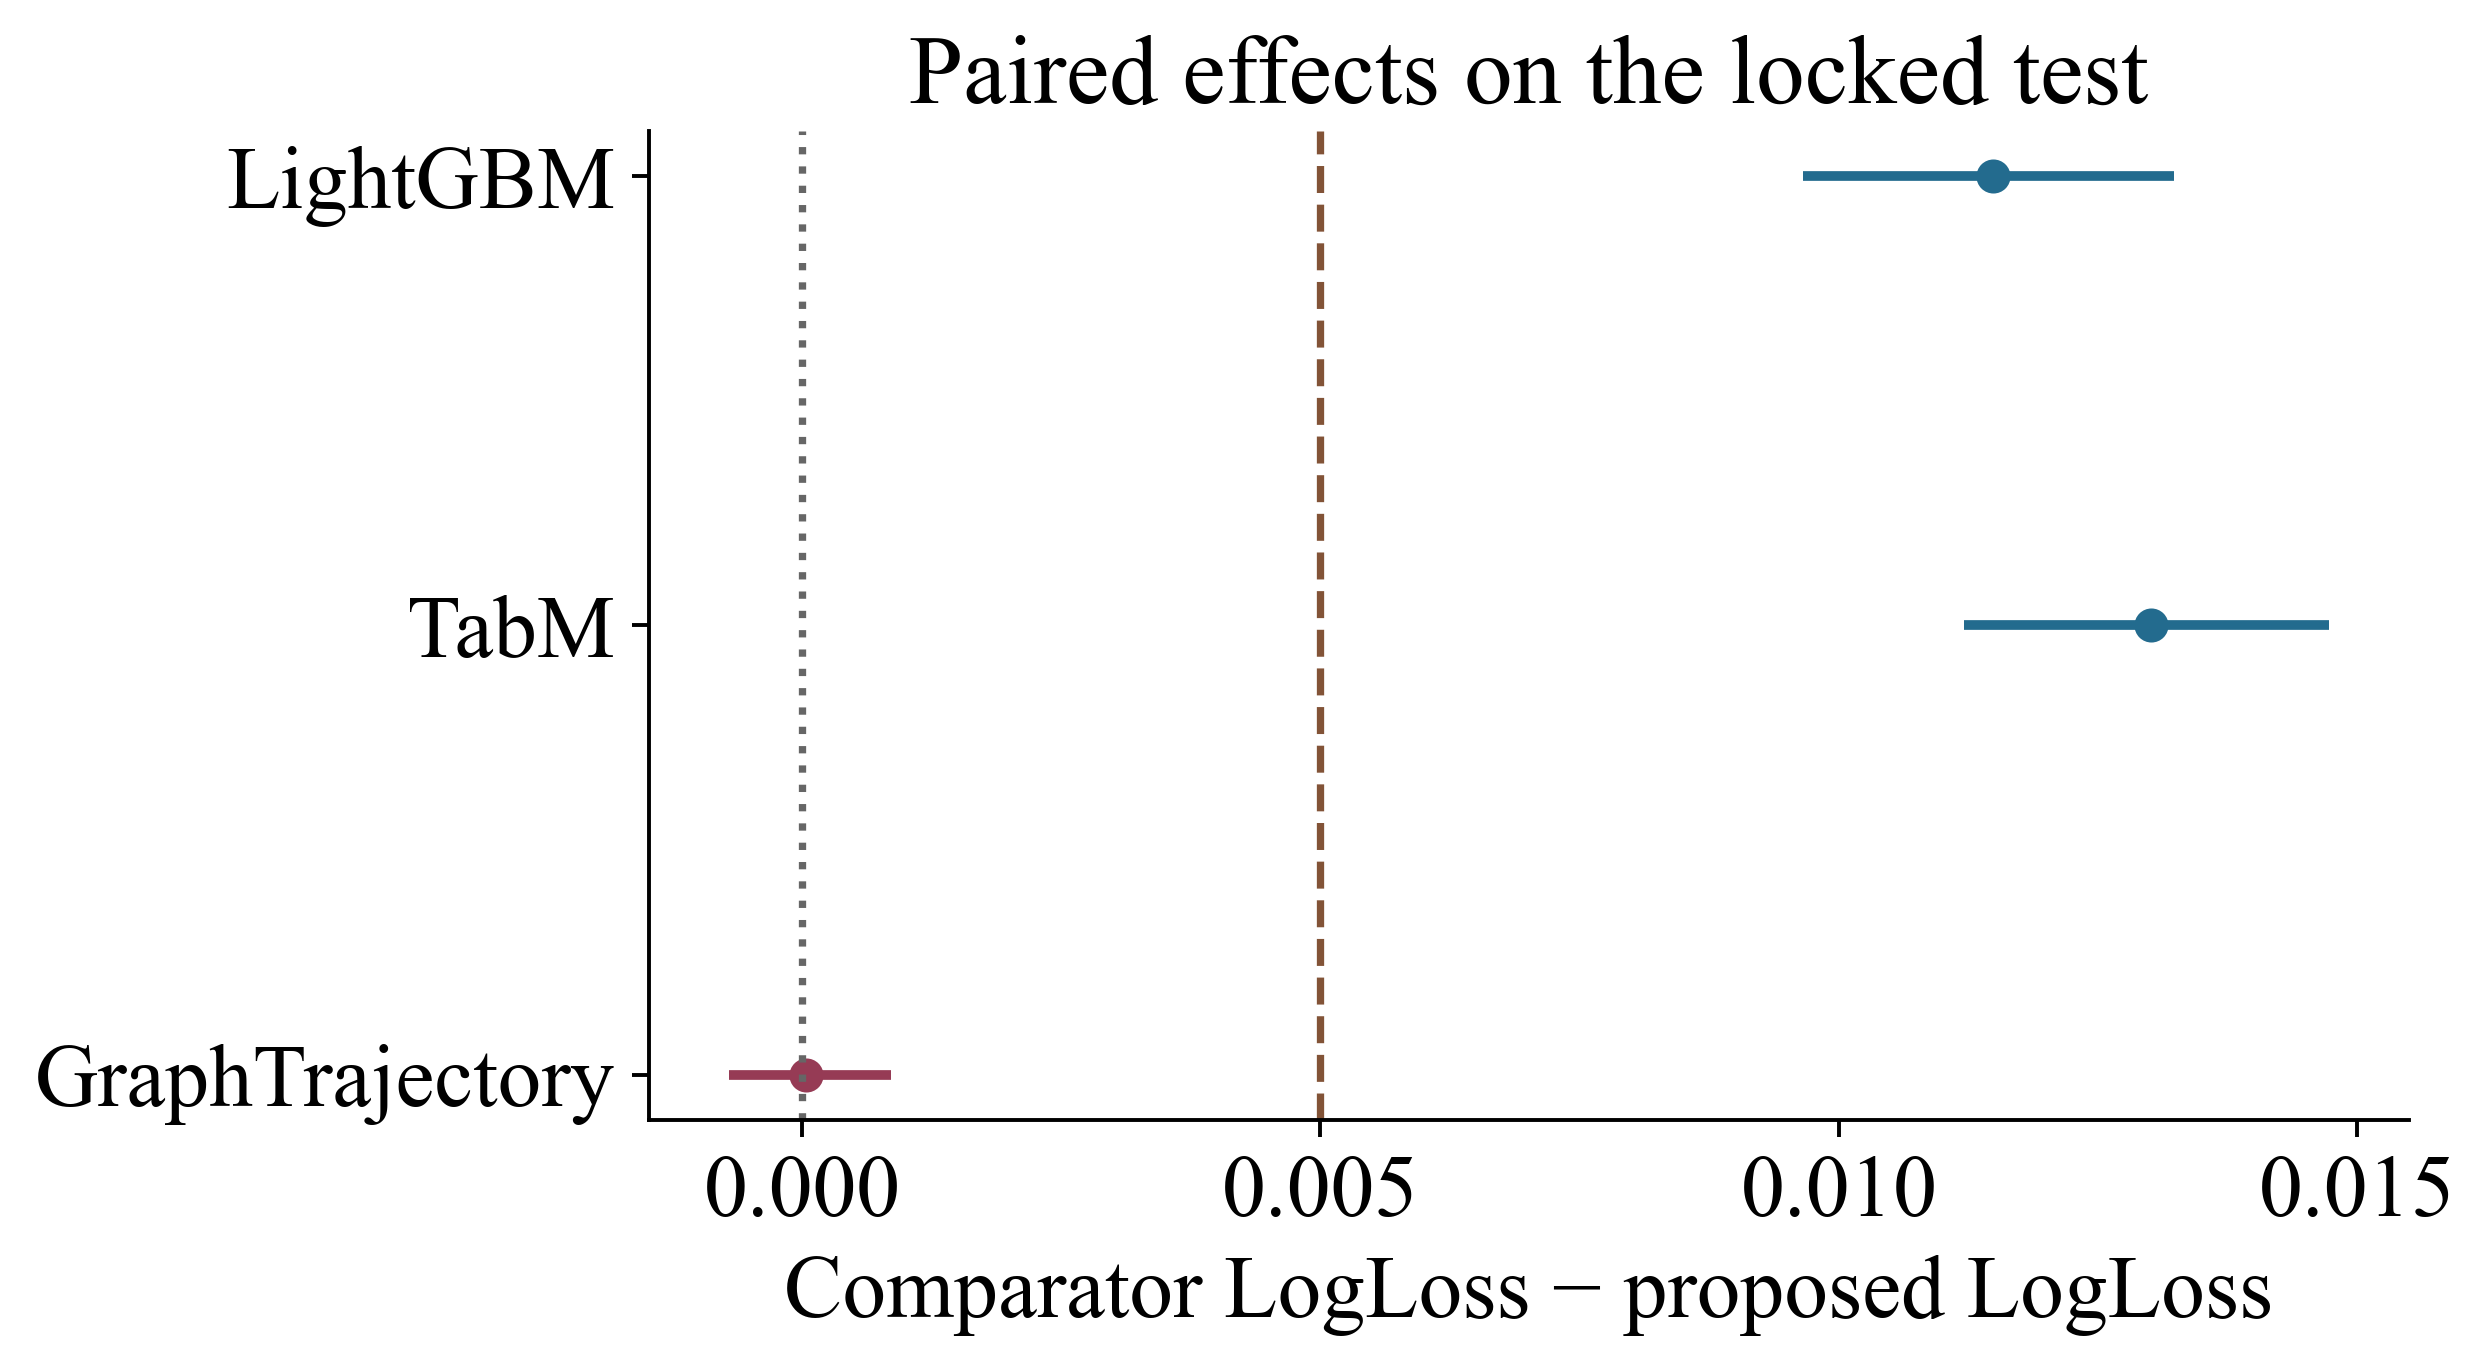

In [8]:
selected_comparators = list(
    dict.fromkeys(analysis["diagnostic_models"][:-1] + ["GraphTrajectory"])
)
effects = (
    analysis["statistics"]
    .set_index("Comparator")
    .loc[selected_comparators]
    .reset_index()
)
fig, ax = plt.subplots(
    figsize=(7.0, max(3.8, 0.65 * len(effects) + 1.8)), layout="constrained"
)
positions = np.arange(len(effects))
for index, row in effects.iterrows():
    color = "#236B8E" if row.CI_low > 0 else "#963B55"
    ax.hlines(index, row.CI_low, row.CI_high, color=color, linewidth=2)
    ax.plot(row.Effect, index, "o", color=color)
ax.axvline(0, color="#666666", linestyle=":")
ax.axvline(
    frozen["practical_logloss_difference"], color="#825337", linestyle="--"
)
ax.set_yticks(positions, effects.Comparator)
ax.invert_yaxis()
ax.set(
    xlabel="Comparator LogLoss − proposed LogLoss",
    title="Paired effects on the locked test",
)
ax.spines[["top", "right"]].set_visible(False)
save_figure(fig, "07_paired_effects")
plt.show()

## Final calibration

The curve and intervals reveal the structure of deviations that a single ECE does not capture. All intervals are recomputed over whole learners at the analysis stage; these computed values are displayed here.

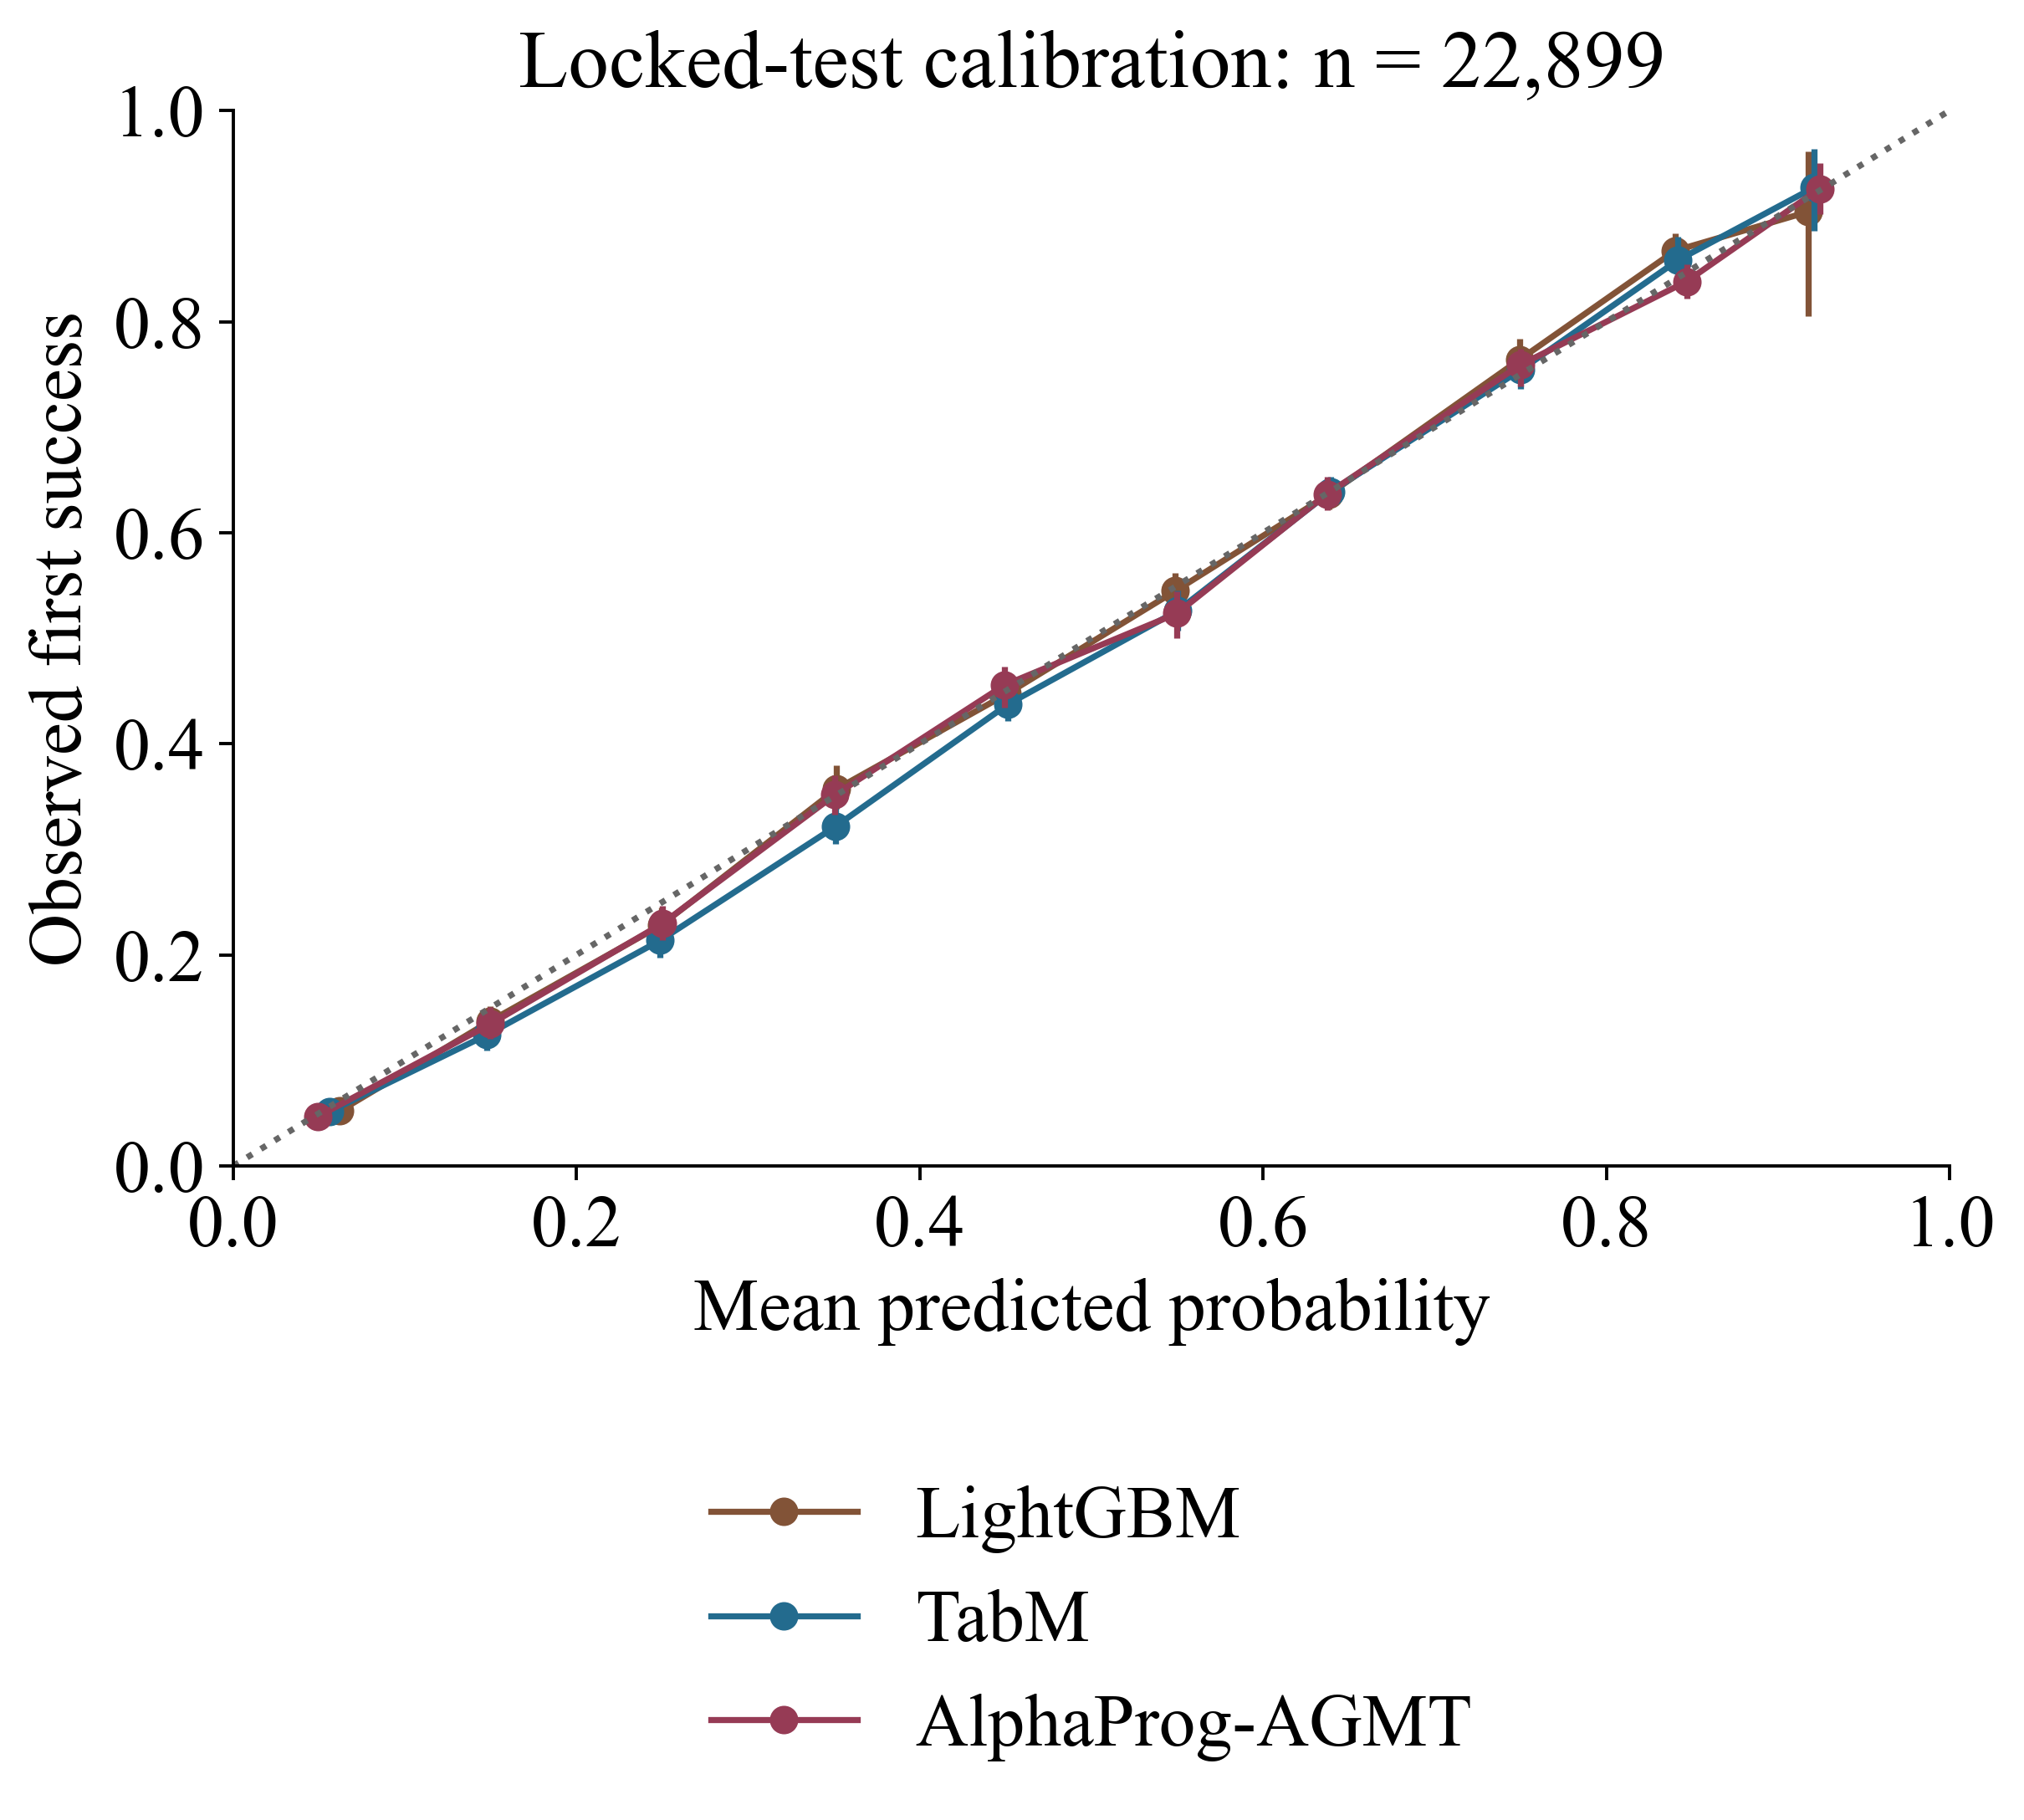

In [9]:
fig, ax = plt.subplots(figsize=(6.8, 6.1), layout="constrained")
for name, color in zip(
    analysis["diagnostic_models"], ["#825337", "#236B8E", "#963B55"]
):
    bins = analysis["calibration_bins"][
        analysis["calibration_bins"].Model.eq(name)
    ]
    if bins.empty:
        continue
    ax.plot(bins.Predicted, bins.Observed, "o-", label=name, color=color)
    ax.vlines(bins.Predicted, bins.CI_low, bins.CI_high, color=color)
ax.plot([0, 1], [0, 1], linestyle=":", color="#666666")
ax.set(
    xlabel="Mean predicted probability",
    ylabel="Observed first success",
    xlim=(0, 1),
    ylim=(0, 1),
    title=f"Locked-test calibration: n = {len(probabilities):,}",
)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.24), frameon=False)
save_figure(fig, "07_calibration")
plt.show()

## Final robustness analysis

History loss tests a specific failure mode: the task description is available, but the past log is not. This complements seed variation and is not evidence of robustness to arbitrary data shift.

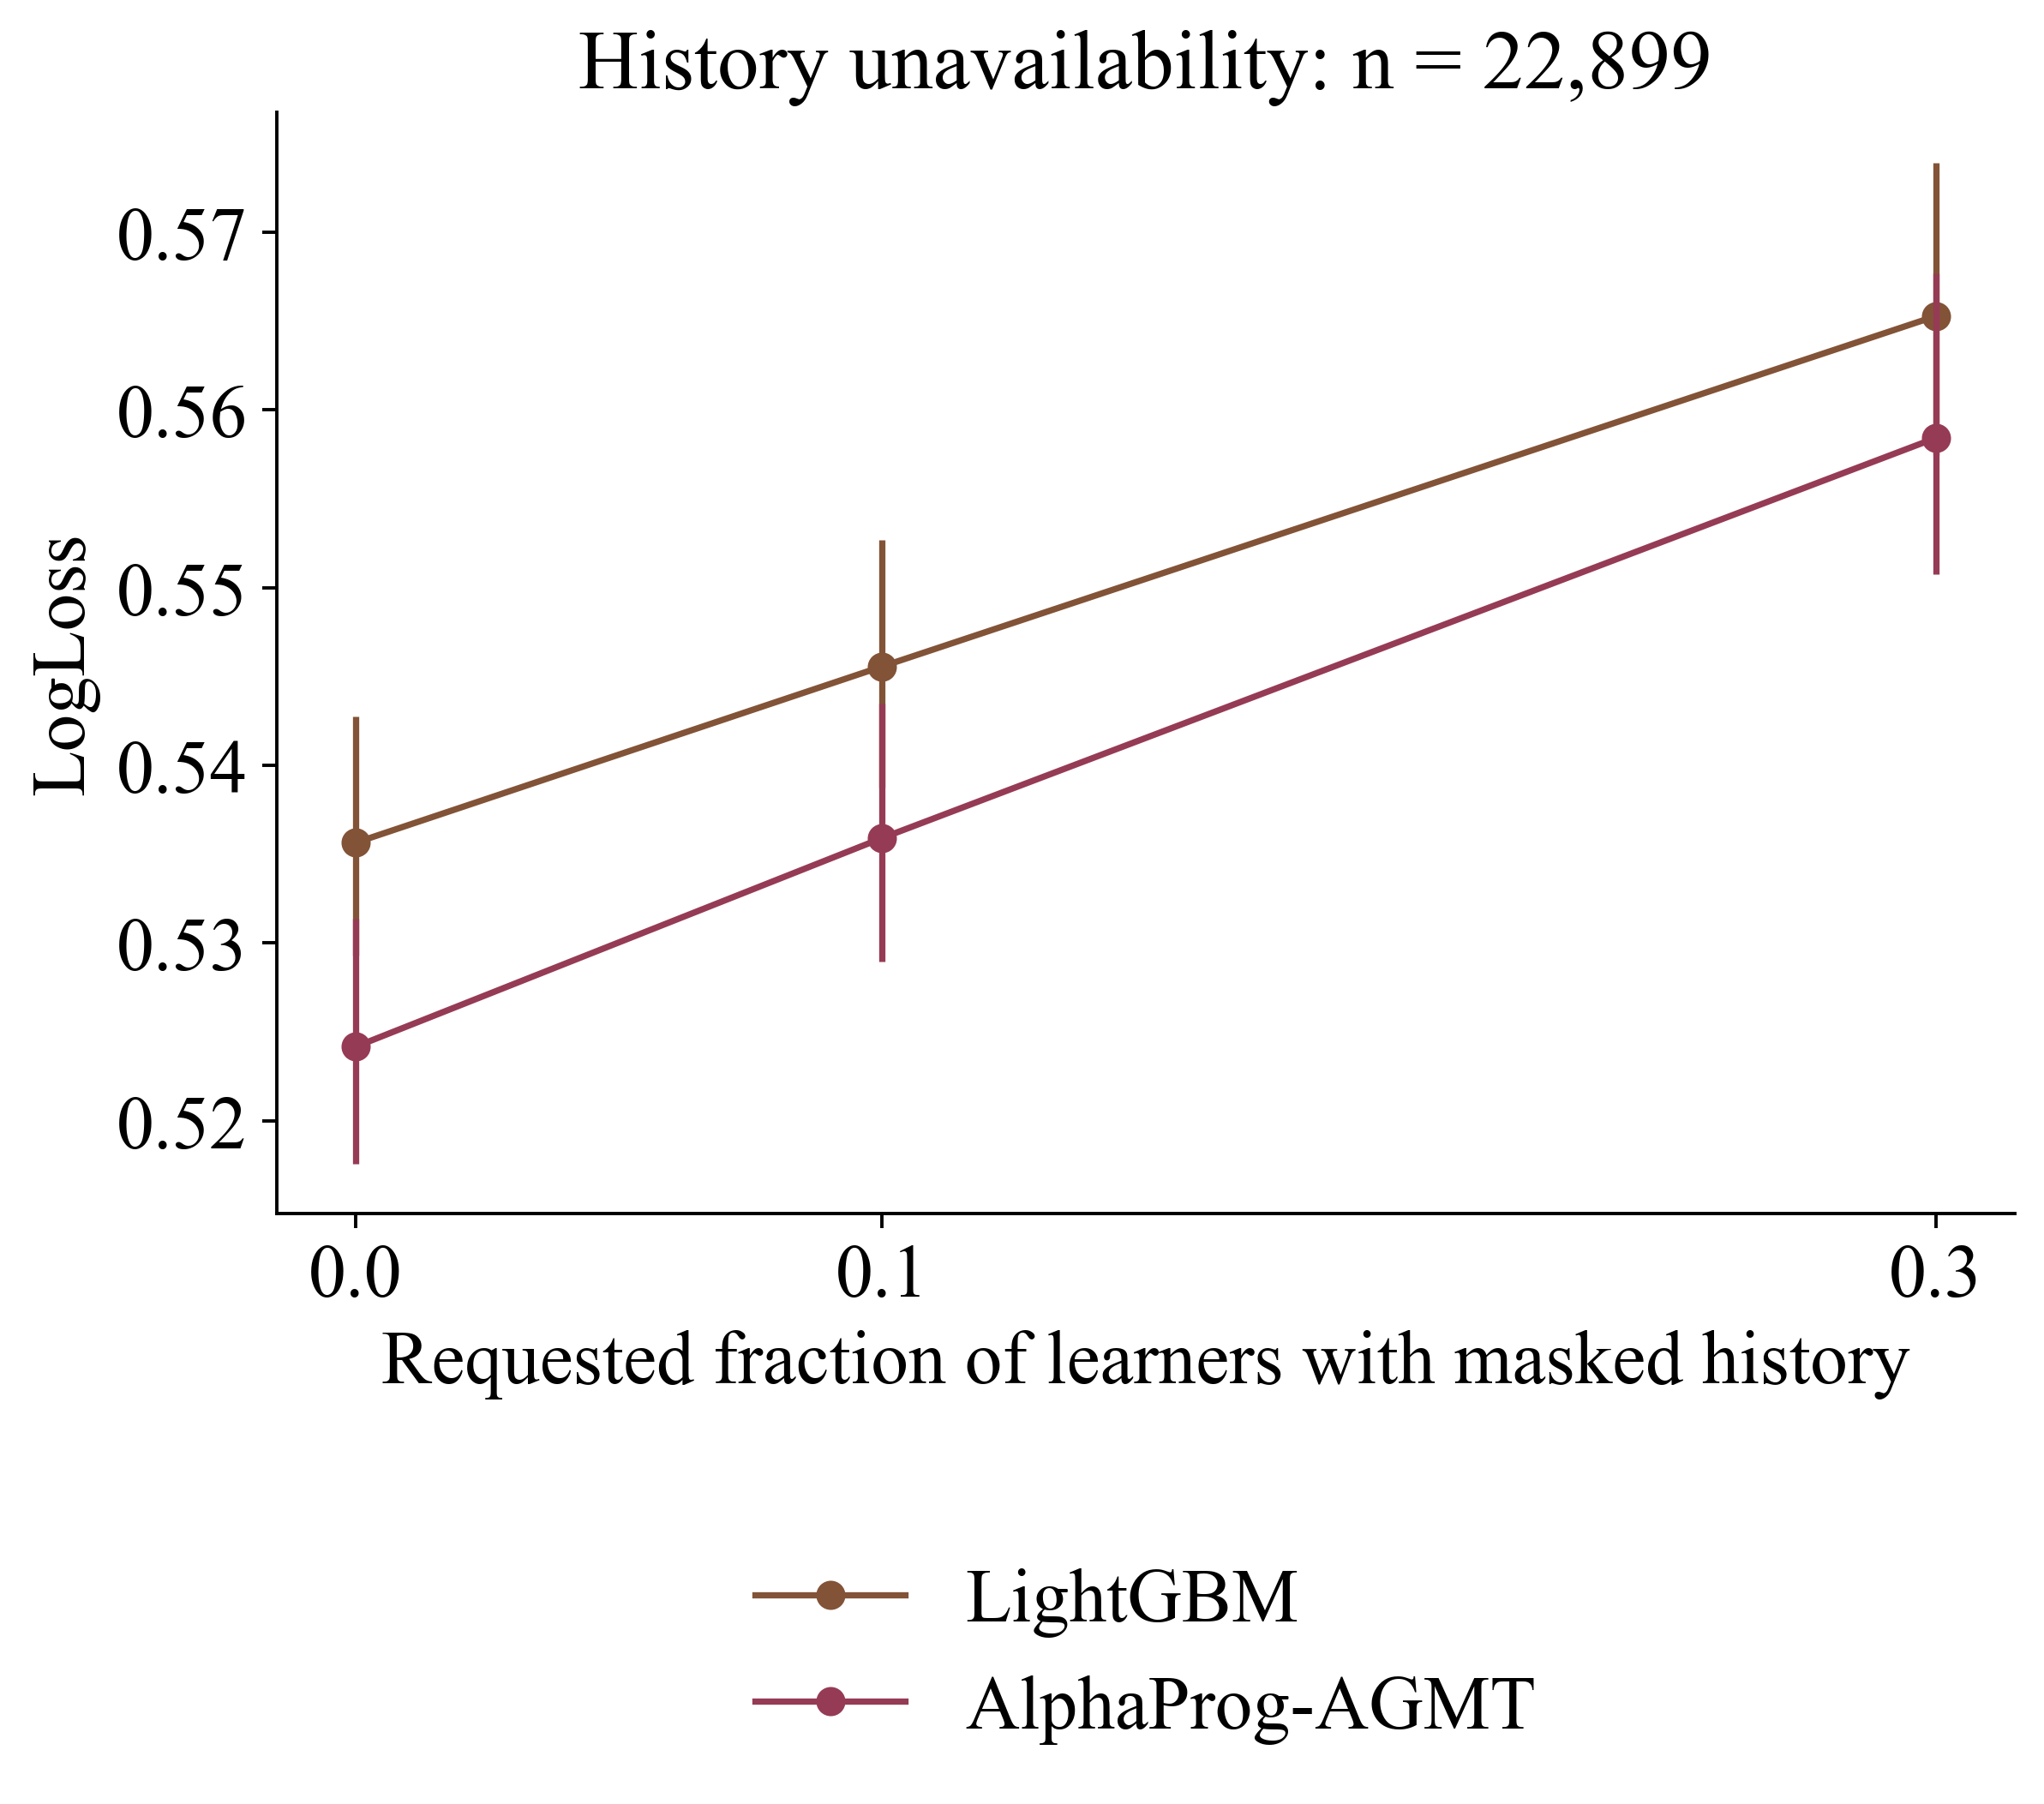

In [10]:
robustness = analysis["robustness"]
fig, ax = plt.subplots(figsize=(6.7, 5.9), layout="constrained")
for (name, group), color in zip(
    robustness.groupby("Model", sort=False), ["#825337", "#963B55"]
):
    ax.plot(group.Mask_fraction, group.LogLoss, "o-", label=name, color=color)
    ax.vlines(group.Mask_fraction, group.CI_low, group.CI_high, color=color)
ax.set_xticks(frozen["robust_history_mask_fractions"])
ax.set(
    xlabel="Requested fraction of learners with masked history",
    ylabel="LogLoss",
    title=f"History unavailability: n = {len(probabilities):,}",
)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.26), frameon=False)
save_figure(fig, "07_robustness")
plt.show()

## Error characteristics

The distribution of individual errors shows whether the difference between models is concentrated in typical queries or in the heavy tail. All observations are retained, and tied values are merged into a correct empirical distribution function.

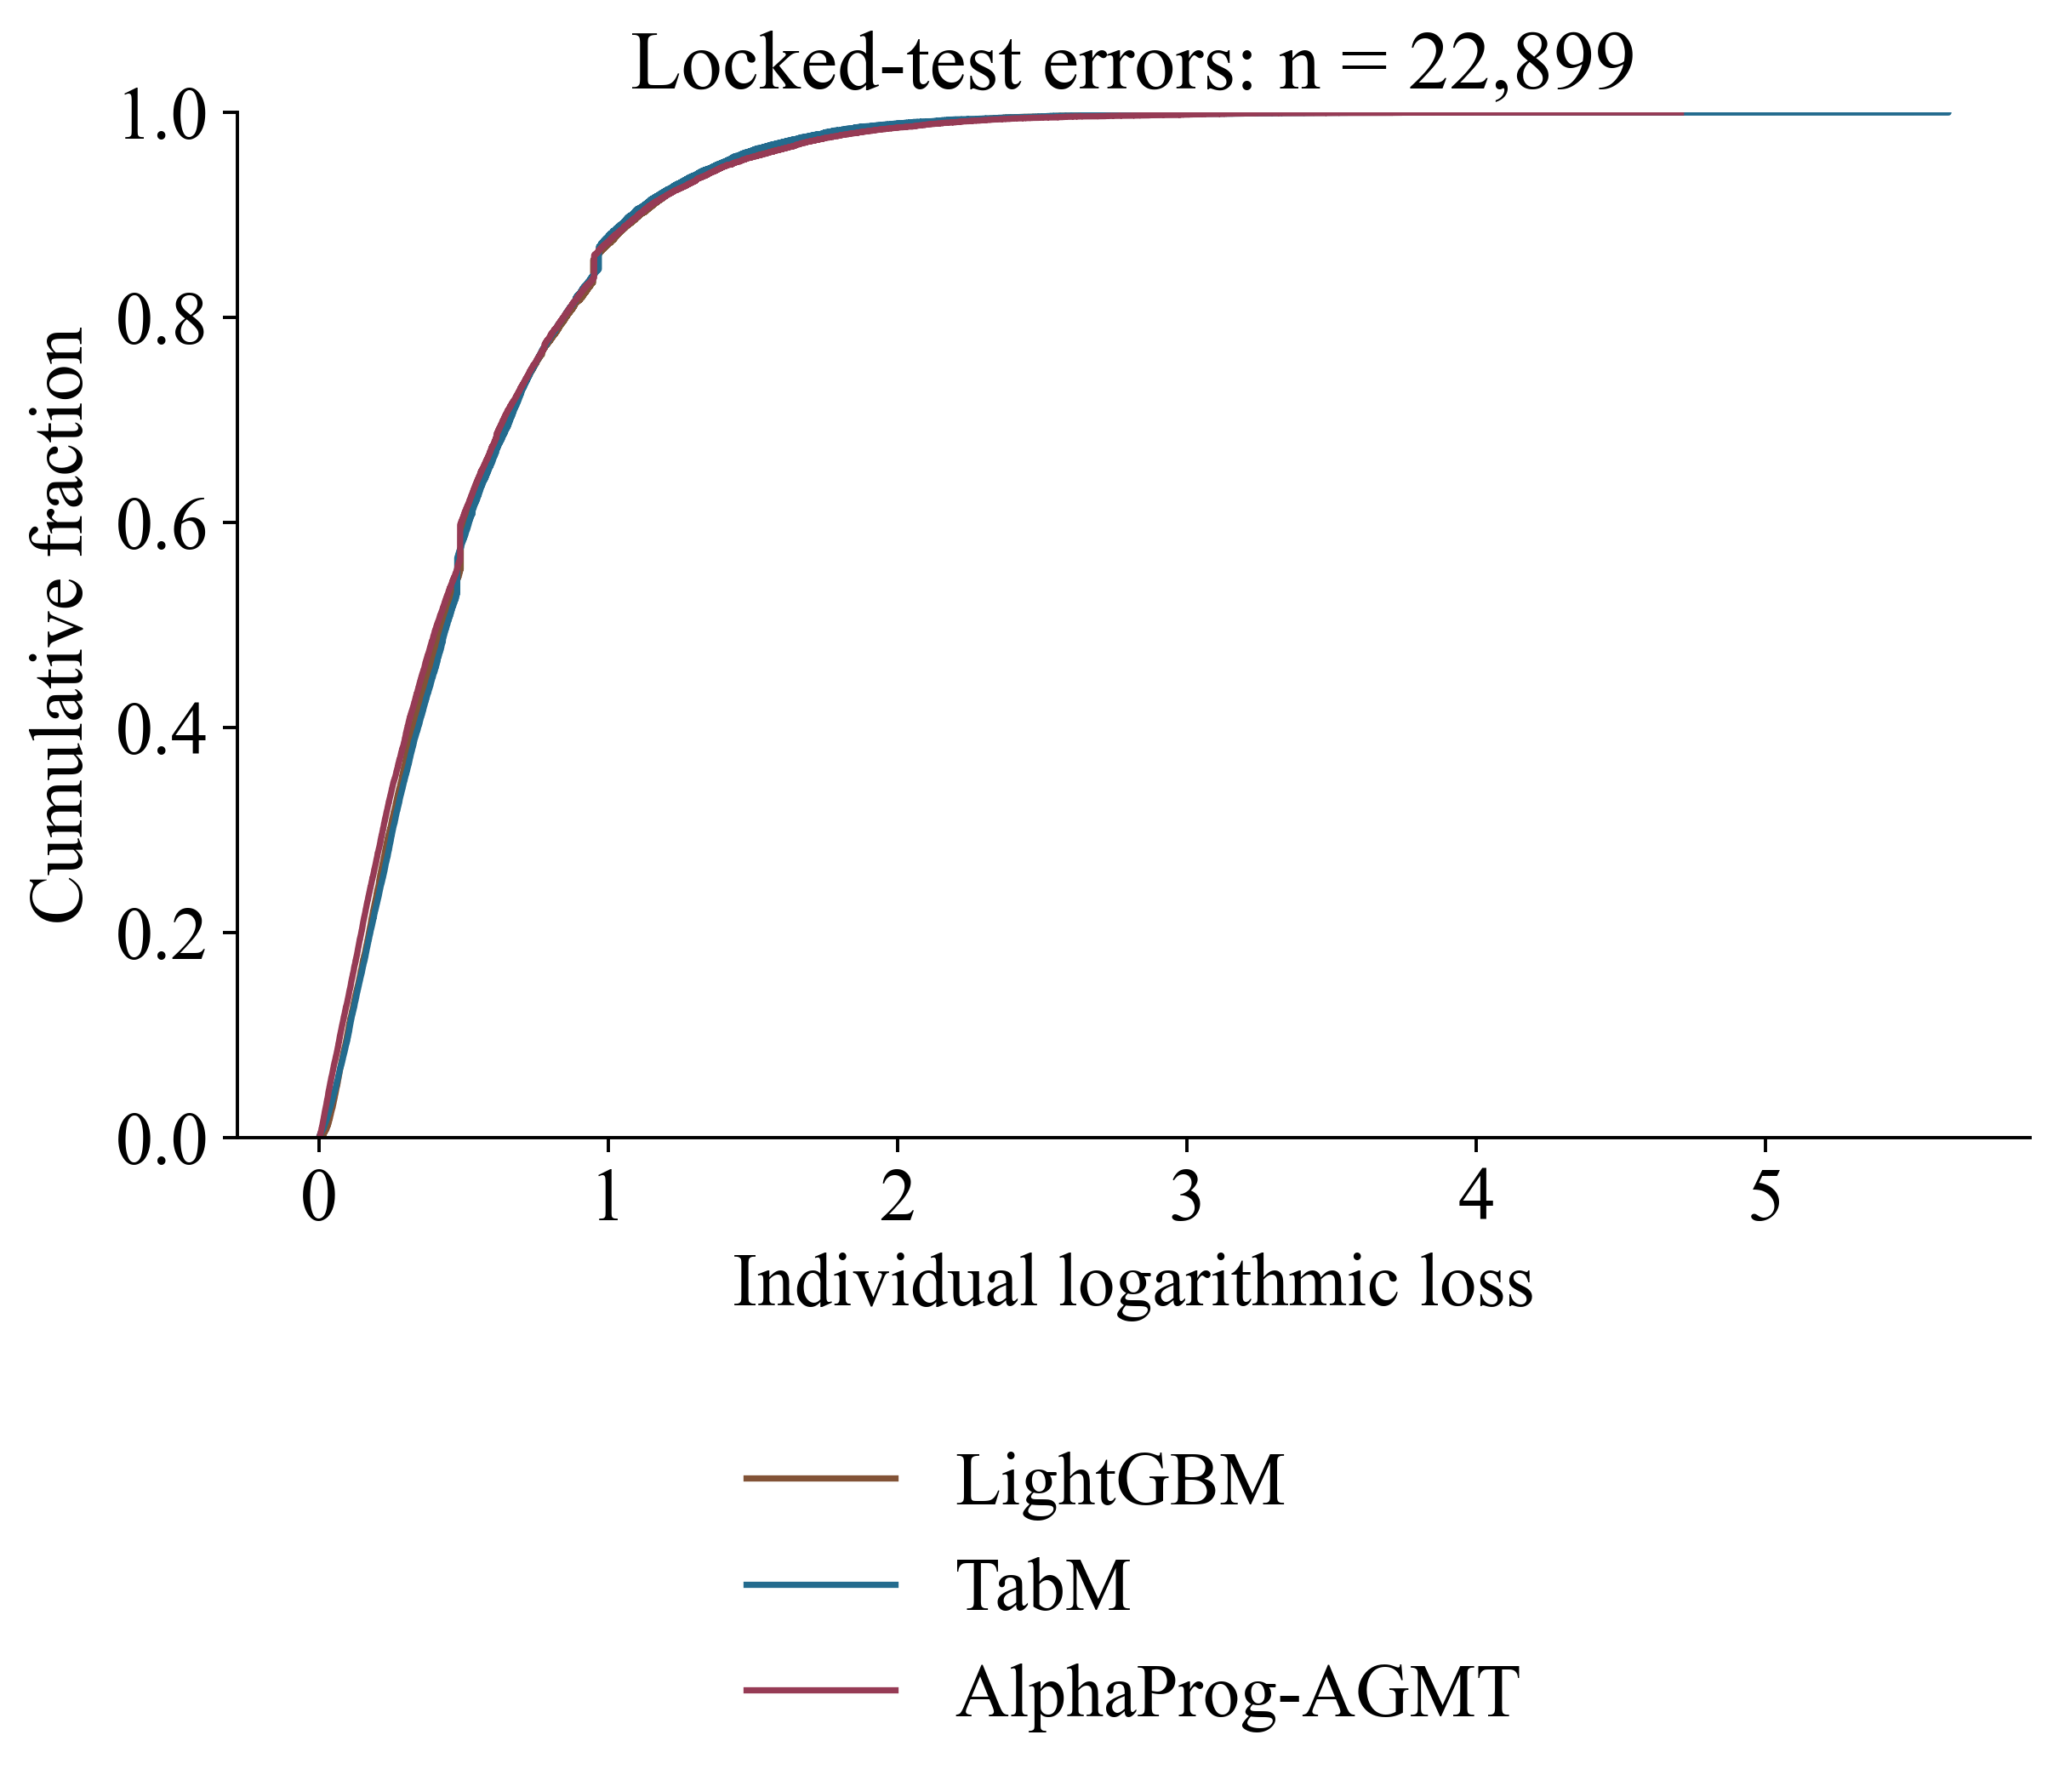

In [11]:
fig, ax = plt.subplots(figsize=(6.8, 5.9), layout="constrained")
truth = probabilities.y.to_numpy()
for name, color in zip(
    analysis["diagnostic_models"], ["#825337", "#236B8E", "#963B55"]
):
    probability = np.clip(probabilities[name].to_numpy(), 1e-6, 1 - 1e-6)
    losses = -(
        truth * np.log(probability) + (1 - truth) * np.log1p(-probability)
    )
    values, counts = np.unique(losses, return_counts=True)
    ax.step(
        values,
        counts.cumsum() / counts.sum(),
        where="post",
        label=name,
        color=color,
    )
ax.set(
    xlabel="Individual logarithmic loss",
    ylabel="Cumulative fraction",
    ylim=(0, 1),
    title=f"Locked-test errors: n = {len(probabilities):,}",
)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.24), frameon=False)
save_figure(fig, "07_errors")
plt.show()

## Component checks on the locked test

The common seed 17 is retained for the ablations. These values are not mixed with the primary comparison of three-seed ensembles. The table allows the necessity of the new components to be examined without altering the configuration on the basis of the test.

In [12]:
table(
    analysis["ablations"],
    "Ablations: LogLoss, Brier and joint NLL ↓",
    "07_ablations",
)

Ablations: LogLoss, Brier and joint NLL ↓

,Model,Split,n,Seed,LogLoss,Brier,Effort_NLL
0,AlphaProg-AGMT,Locked test,22899,17,0.52528,0.17674,1.55888
1,NoGraphEncoder,Locked test,22899,17,0.52735,0.17747,1.56228
2,NoOrder,Locked test,22899,17,0.52956,0.17841,1.56615
3,NoAuxLoss,Locked test,22899,17,0.52634,0.17711,1.56870
4,NoEdges,Locked test,22899,17,0.52650,0.17715,1.56111
5,NoInteraction,Locked test,22899,17,0.52714,0.17752,1.56112
6,NoTaskReadout,Locked test,22899,17,0.52644,0.17718,1.56283
7,ConstantFusion,Locked test,22899,17,0.52521,0.17668,1.55909
8,BestSingle: GraphTrajectory,Locked test,22899,17,0.52602,0.17702,1.56174


## Censored effort

Joint NLL and Brier over run horizons characterise the additional task. For IPCW, the censoring curve estimated on train is used; independence of censoring remains an untested limitation.

The first-run Brier is already shown in the probabilistic quality table. Its repetition is omitted; the joint NLL and the subsequent horizons remain here.

In [13]:
effort_publication = analysis["effort"].drop(columns="Brier_run_1").copy()
effort_publication["order"] = effort_publication.Model.map(
    {name: index for index, name in enumerate(publication_order)}
)
effort_publication = effort_publication.sort_values(
    "order", kind="stable"
).drop(columns="order")
table(
    effort_publication,
    "Joint NLL and IPCW Brier at runs 3, 5 and 10 ↓",
    "07_effort",
)

Joint NLL and IPCW Brier at runs 3, 5 and 10 ↓

,Model,Split,n,Effort_NLL,Brier_run_3,Brier_run_5,Brier_run_10
0,AlphaProg-AGMT,Locked test,22899,1.55618,0.13902,0.10560,0.05823
1,LightGBM,Locked test,22899,1.57781,0.14379,0.10917,0.05974
2,TabM,Locked test,22899,1.57934,0.14362,0.10904,0.05975


## Self-contained school experiment

The post-test prediction is compared on the same two locked-test schools for all four school methods. These results are not pooled with the RoboMission binary metrics and do not serve as evidence of cross-platform transfer.

In [14]:
table(
    analysis["school"][analysis["school"].Group.eq("All schools")].drop(
        columns="Group"
    ),
    "School cCTt: MAE and RMSE ↓; R² ↑",
    "07_school_quality",
)

School cCTt: MAE and RMSE ↓; R² ↑

,Model,Split,n,MAE,RMSE,R2
0,Pretest,Locked school test,397,3.45340,4.36294,0.16666
1,RidgePretest,Locked school test,397,2.64810,3.35857,0.50617
2,RidgeFull,Locked school test,397,3.02065,3.71307,0.39643
3,RandomForest,Locked school test,397,2.74525,3.45237,0.47820


## Architecture of the evaluated model

The figure shows the components actually implemented and the computation flow: block numbers define the order of the training and inference steps. Inputs observed up to the prediction time are separated from the target quantities, which are used only in the loss functions. The necessity of each component is established by ablations, not by its presence in the diagram.

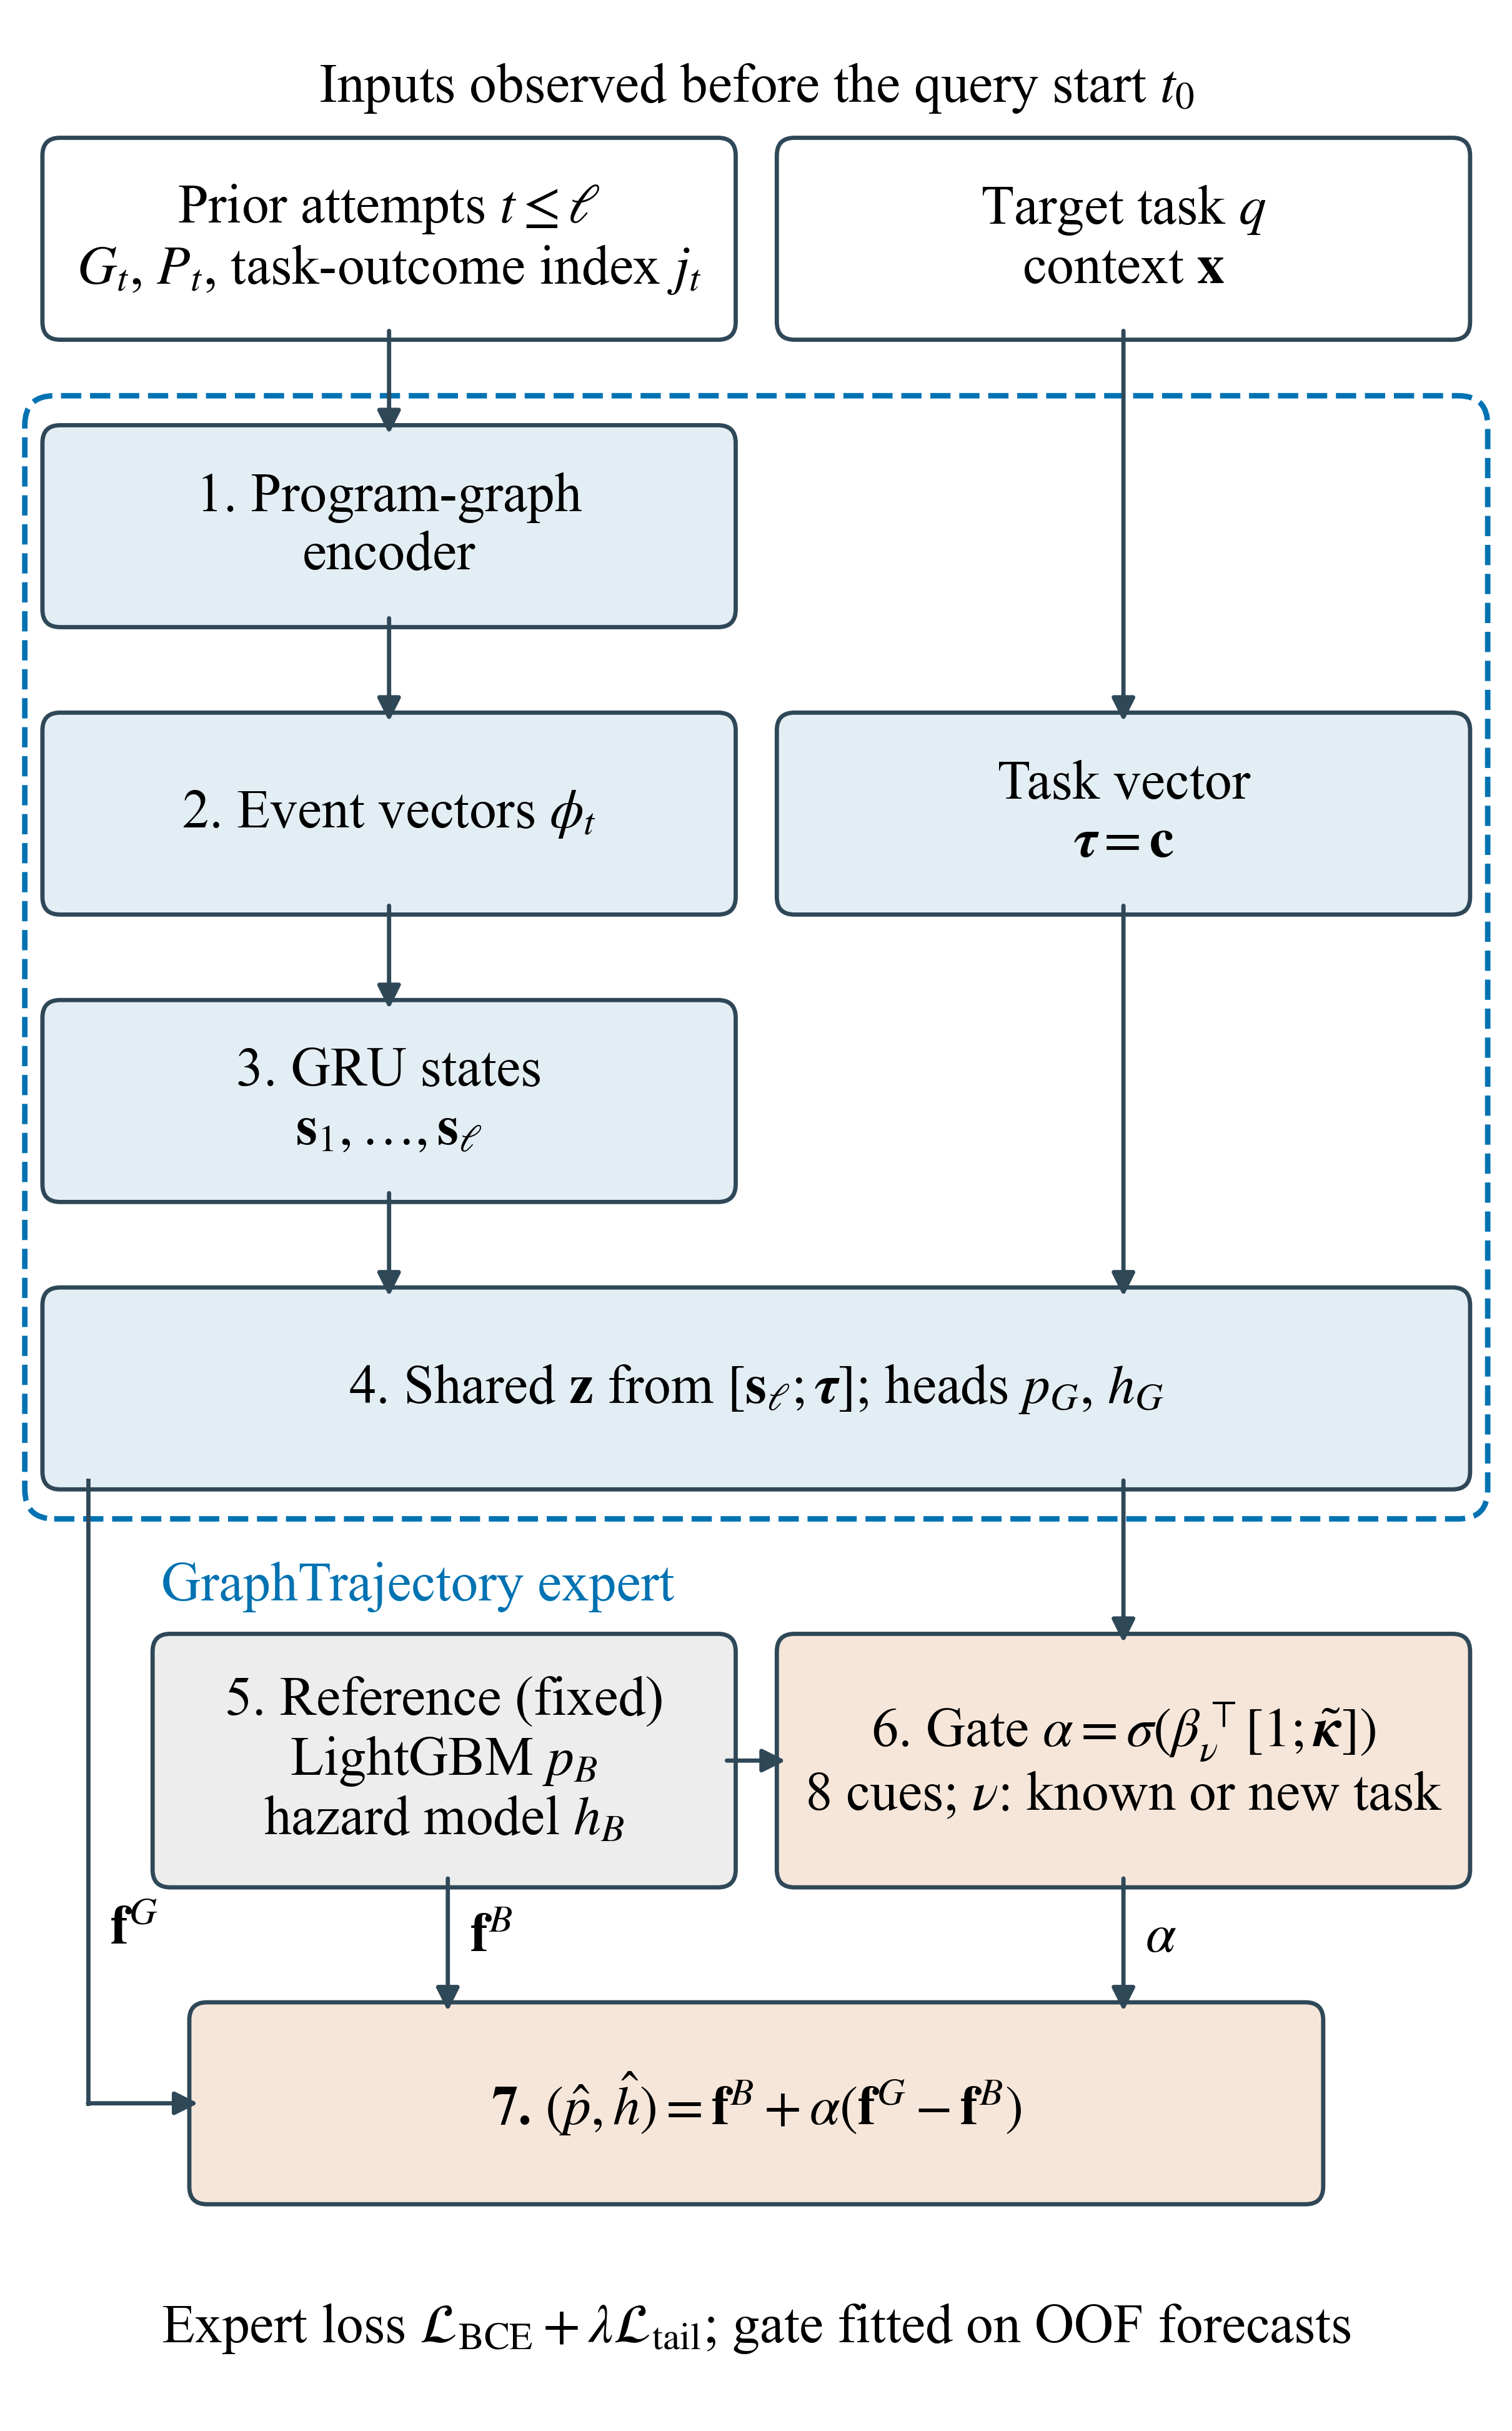

In [15]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

USE_SOLUTION = frozen["graph_config"]["use_solution"]
USE_ATTENTION = frozen["graph_config"]["use_task_attention"]
USE_INTERACTION = frozen["graph_config"].get("use_interaction", False)
USE_READOUT = frozen["graph_config"].get("use_task_readout", False)
NOVELTY_GATE = frozen.get("gate_novelty", "Single gate") != "Single gate"
fig, ax = plt.subplots(figsize=(6.8, 11.0), layout="constrained")
ax.set(xlim=(0, 10), ylim=(0, 16.2))
ax.axis("off")
EXPERT, REFERENCE, FUSION, INPUT = "#E3EEF4", "#EDEDED", "#F6E6DA", "#FFFFFF"


def box(x, y, width, height, text, face, weight="normal"):
    """Draw one rounded block with centred 18 pt text."""
    ax.add_patch(
        FancyBboxPatch(
            (x, y), width, height, boxstyle="round,pad=0.06,rounding_size=0.12",
            facecolor=face, edgecolor="#2F4858", linewidth=1.4,
        )
    )
    ax.text(x + width / 2, y + height / 2, text, ha="center", va="center", fontsize=18, fontweight=weight)


def arrow(start, end):
    ax.add_patch(
        FancyArrowPatch(
            start, end, arrowstyle="-|>", mutation_scale=16, color="#2F4858",
            linewidth=1.4, shrinkA=0, shrinkB=0,
        )
    )


LEFT, RIGHT, HALF, FULL, HEIGHT = 0.2, 5.2, 4.6, 9.6, 1.25
ROW = {"input": 14.1, "encoder": 12.15, "vectors": 10.2, "history": 8.25, "shared": 6.3, "fusion": 3.6, "output": 1.45}
centre_left, centre_right = LEFT + HALF / 2, RIGHT + HALF / 2
ax.text(5.0, 15.75, "Inputs observed before the query start $t_0$", ha="center", va="center", fontsize=18)
box(
    LEFT, ROW["input"], HALF, HEIGHT,
    "Prior attempts $t \\leq \\ell$\n$G_t$, $P_t$, task-outcome index $j_t$" if USE_INTERACTION
    else "Prior attempts\n$G_t$, $P_t$, $t \\leq \\ell$",
    INPUT,
)
box(
    RIGHT, ROW["input"], HALF, HEIGHT,
    "Target task $q$: context\n$\\mathbf{x}$, solution graph $S_q$" if USE_SOLUTION else "Target task $q$\ncontext $\\mathbf{x}$",
    INPUT,
)
if USE_SOLUTION:
    # The encoder is shared by learner programs and the reference solution.
    box(LEFT, ROW["encoder"], FULL, HEIGHT, "1. Program-graph encoder (shared weights)", EXPERT)
else:
    box(LEFT, ROW["encoder"], HALF, HEIGHT, "1. Program-graph\nencoder", EXPERT)
box(LEFT, ROW["vectors"], HALF, HEIGHT, "2. Event vectors $\\phi_t$", EXPERT)
box(
    RIGHT, ROW["vectors"], HALF, HEIGHT,
    "Task vector\n$\\boldsymbol{\\tau}=[\\mathbf{c};\\psi(\\mathbf{z}_q)]$" if USE_SOLUTION else "Task vector\n$\\boldsymbol{\\tau}=\\mathbf{c}$",
    EXPERT,
)
box(LEFT, ROW["history"], HALF, HEIGHT, "3. GRU states\n$\\mathbf{s}_1,\\ldots,\\mathbf{s}_\\ell$", EXPERT)
if USE_ATTENTION:
    box(RIGHT, ROW["history"], HALF, HEIGHT, "4. Attention readout\n$\\mathbf{a}$, query $\\boldsymbol{\\tau}$", EXPERT)
    shared_text = "5. Shared $\\mathbf{z}$ from $[\\mathbf{s}_\\ell;\\boldsymbol{\\tau};\\mathbf{a}]$; heads $p_G$, $h_G$"
    if USE_READOUT:
        shared_text = "5. Shared $\\mathbf{z}$ from $[\\mathbf{s}_\\ell;\\boldsymbol{\\tau};\\mathbf{a}]$\ntask-specific heads $p_G$, $h_G$"
else:
    shared_text = "4. Shared $\\mathbf{z}$ from $[\\mathbf{s}_\\ell;\\boldsymbol{\\tau}]$; heads $p_G$, $h_G$"
box(LEFT, ROW["shared"], FULL, HEIGHT, shared_text, EXPERT)
frame_bottom, frame_top = ROW["shared"] - 0.22, ROW["encoder"] + HEIGHT + 0.22
ax.add_patch(
    FancyBboxPatch(
        (0.06, frame_bottom), 9.88, frame_top - frame_bottom,
        boxstyle="round,pad=0.04,rounding_size=0.2", facecolor="none", edgecolor="#0072B2",
        linewidth=1.8, linestyle="--",
    )
)
ax.text(0.95, ROW["shared"] - 0.72, "GraphTrajectory expert", ha="left", va="center", fontsize=18, color="#0072B2")
step = 6 if USE_ATTENTION else 5
box(0.95, ROW["fusion"], 3.85, 1.6, f"{step}. Reference (fixed)\nLightGBM $p_B$\nhazard model $h_B$", REFERENCE)
box(
    RIGHT, ROW["fusion"], HALF, 1.6,
    f"{step + 1}. Gate $\\alpha=\\sigma(\\beta_{{\\nu}}^{{\\top}}[1;\\tilde{{\\boldsymbol{{\\kappa}}}}])$\n8 cues; $\\nu$: known or new task"
    if NOVELTY_GATE
    else f"{step + 1}. Gate $\\alpha=\\sigma(\\beta^{{\\top}}[1;\\tilde{{\\boldsymbol{{\\kappa}}}}])$\n8 reliability cues $\\boldsymbol{{\\kappa}}$",
    FUSION,
)
box(
    1.2, ROW["output"], 7.6, HEIGHT,
    f"{step + 2}. $(\\hat{{p}},\\hat{{h}})=\\mathbf{{f}}^B+\\alpha(\\mathbf{{f}}^G-\\mathbf{{f}}^B)$", FUSION, weight="bold",
)
arrow((centre_left, ROW["input"]), (centre_left, ROW["encoder"] + HEIGHT))
arrow((centre_right, ROW["input"]), (centre_right, (ROW["encoder"] if USE_SOLUTION else ROW["vectors"]) + HEIGHT))
arrow((centre_left, ROW["encoder"]), (centre_left, ROW["vectors"] + HEIGHT))
if USE_SOLUTION:
    arrow((centre_right, ROW["encoder"]), (centre_right, ROW["vectors"] + HEIGHT))
arrow((centre_left, ROW["vectors"]), (centre_left, ROW["history"] + HEIGHT))
arrow((centre_left, ROW["history"]), (centre_left, ROW["shared"] + HEIGHT))
if USE_ATTENTION:
    arrow((centre_right, ROW["vectors"]), (centre_right, ROW["history"] + HEIGHT))
    arrow((LEFT + HALF, ROW["history"] + HEIGHT / 2), (RIGHT, ROW["history"] + HEIGHT / 2))
    arrow((centre_right, ROW["history"]), (centre_right, ROW["shared"] + HEIGHT))
else:
    arrow((centre_right, ROW["vectors"]), (centre_right, ROW["shared"] + HEIGHT))
# Expert forecasts g reach the gate cues and the final mixture.
arrow((7.5, ROW["shared"]), (7.5, ROW["fusion"] + 1.6))
ax.plot([0.45, 0.45], [ROW["shared"], ROW["output"] + HEIGHT / 2], color="#2F4858", linewidth=1.4)
arrow((0.45, ROW["output"] + HEIGHT / 2), (1.2, ROW["output"] + HEIGHT / 2))
arrow((4.8, ROW["fusion"] + 0.8), (RIGHT, ROW["fusion"] + 0.8))
arrow((2.9, ROW["fusion"]), (2.9, ROW["output"] + HEIGHT))
arrow((7.5, ROW["fusion"]), (7.5, ROW["output"] + HEIGHT))
ax.text(0.6, ROW["output"] + HEIGHT + 0.55, "$\\mathbf{f}^G$", ha="left", va="center", fontsize=18)
ax.text(3.05, ROW["output"] + HEIGHT + 0.5, "$\\mathbf{f}^B$", ha="left", va="center", fontsize=18)
ax.text(7.65, ROW["output"] + HEIGHT + 0.5, "$\\alpha$", ha="left", va="center", fontsize=18)
ax.text(
    5.0, 0.55, "Expert loss $\\mathcal{L}_{\\mathrm{BCE}}+\\lambda\\mathcal{L}_{\\mathrm{tail}}$; gate fitted on OOF forecasts",
    ha="center", va="center", fontsize=18,
)
save_figure(fig, "07_architecture")
plt.show()

## Secondary target: effect intervals

The intervals refer to the mean difference in NLL over observed records and are obtained by bootstrap over whole learners. These are separate 95% intervals for the secondary analysis, not a confirmation of superiority on the primary metric or simultaneous coverage of all comparisons.

In [16]:
table(
    analysis["effort_effects"],
    "Secondary target: comparator NLL − AlphaProg-AGMT NLL; 95% CI",
    "07_effort_effects",
)

Secondary target: comparator NLL − AlphaProg-AGMT NLL; 95% CI

,Model,Comparator,Split,n,Effect_NLL,CI_low,CI_high
0,AlphaProg-AGMT,LightGBM,Locked test,22899,0.02163,0.01878,0.02456
1,AlphaProg-AGMT,TabM,Locked test,22899,0.02316,0.02034,0.02584


## Scientific limitations

The data are retrospective. The primary protocol tests transfer to new learners on known tasks within a shared calendar period; a later period and unseen tasks are examined only in the additional schemes below. The ages of individual users are unknown; the results cannot be automatically attributed to Generation Alpha. First visits without an observed run have no binary label and were not scored as known failures.

Toolbox combinations denote task properties and are not an independent diagnosis of competences. The school data provide no individual linkage with RoboMission. The pedagogical effectiveness of recommendations, gains in learning outcomes and the causal effect of adaptation were not tested by intervention.

The comparison covers specific reproducible methods under a limited budget. FA-KT was not included in the frozen comparator set; therefore, superiority over all current SOTA methods is not confirmed. All selection used OOF and validation data. The configuration evaluated here was selected by a pre-registered screen on validation data alone; the test split had been evaluated before this selection, so its single evaluation on that test does not provide independent confirmation.

The geometric effort model assumes a constant conditional hazard; IPCW depends on the censoring assumption. The cluster bootstrap does not remove dependence within unknown school classes. The school branch has only two independent test schools. Timing measurements refer to the current device; peak memory was not measured. The internal weights explain the mixing of experts but not the causal mechanisms of learning.

Absent or negative statistical confirmation is not replaced by a claim of superiority. The substantive conclusion is formulated from the completed tables and figures.

Probabilities refer to the observed task choice. An improvement in a predictive metric does not demonstrate the benefit of a recommendation policy or skill growth following a pedagogical intervention.

In [17]:
assert all(
    len(analysis[name]) > 0
    for name in [
        "primary",
        "ranking",
        "calibration",
        "statistics",
        "seeds",
        "efficiency",
    ]
)
assert json.loads((ROOT / "Protocol/robomission_protocol.json").read_text())[
    "locked_test_opened"
]

## Additional experiments after the test was opened

**Status.** All computations in this section are post hoc sensitivity analyses performed after the locked test had been opened. The configuration analysed here was selected on validation data alone (`Protocol/model_development_protocol.json`) and was evaluated once on the test before this section was executed. The frozen AlphaProg-AGMT configuration, the features and splits of notebooks 01–02, and the selected hyperparameters of the comparators are not changed. Reuse of the test provides no independent confirmation. The new evaluation schemes (next school year, unseen tasks) use learners whose data have already been examined.

**Implementation.** Training is performed with the original code of notebooks 03–05 and the inference functions of notebook 06. The code is loaded from the saved cells of these notebooks after SHA-256 verification; only the paths of the training logs were changed so that the frozen artefacts are not overwritten. The new elements (separate gates, the Code-DKT-type model, LightGBM with sequential inputs, the new split schemes) are implemented explicitly below. The settings were specified before execution in `Protocol/additional_analyses_protocol.json`.

**Questions of this section.**
1. In which regimes is the hybrid preferable to its own expert for the joint prediction of success and effort?
2. What is the practical meaning of the gain for support decisions?
3. To what extent do the conclusions on effort depend on the assumptions about censoring and a constant hazard?
4. Is a shared gate coefficient needed for the two outputs, and what does the adaptive gate contribute when history is absent?
5. Are the component contributions significant over three seeds; how do the auxiliary-loss weight and the history window affect both predictions?
6. Does the advantage persist in the next school year and on unseen tasks?
7. Did the neural comparators converge within 8 epochs?
8. Is the gain explained by the inputs rather than by the architecture?
9. What are the costs under identical CPU execution?

In [18]:
import io
import contextlib
import gc
import time
import random
from datetime import datetime, timezone
from scipy.special import expit, logit
from scipy.optimize import minimize
from sklearn.metrics import roc_auc_score, average_precision_score

ANALYSIS_DIR = ROOT / "Results/additional"
ANALYSIS_DIR.mkdir(parents=True, exist_ok=True)
PROGRESS_LOG = ROOT / "Logs/additional_progress.log"
# True discards stored post hoc fits and repeats every training run below.
ANALYSIS_RETRAIN = False
post_hoc = json.loads(
    (ROOT / "Protocol/additional_analyses_protocol.json").read_text()
)
assert post_hoc["frozen_configuration_changed"] is False
reuse = post_hoc["implementation_reuse"]
SEEDS = post_hoc["seeds"]
assert SEEDS == frozen["seeds"]
FROZEN_06_DEFINITIONS = (
    "e31c134084555b1eeb392be718bb5316e879537df4c3f4d02420eecc4362dc78"
)


def frozen_namespace(
    filename: str,
    cells: list[int],
    redirects: dict[str, str] | None = None,
    silent: tuple[str, ...] = (),
) -> dict:
    """Execute verbatim code cells of an earlier notebook in an isolated namespace."""
    notebook = json.loads((ROOT / "Notebooks" / filename).read_text())
    namespace = {"__name__": f"frozen_{filename[:2]}"}
    for index in cells:
        cell = notebook["cells"][index]
        assert cell["cell_type"] == "code"
        source = "".join(cell["source"])
        for old, new in (redirects or {}).items():
            source = source.replace(old, new)
        for name in silent:
            if name in namespace:
                namespace[name] = lambda *args, **kwargs: None
        with contextlib.redirect_stdout(io.StringIO()):
            exec(compile(source, f"<{filename} cell {index}>", "exec"), namespace)
    return namespace


notebook_06 = json.loads(
    (ROOT / "Notebooks/06_Model_Analysis.ipynb").read_text()
)
definitions_06 = "\n\n".join(
    "".join(notebook_06["cells"][index]["source"])
    for index in reuse["notebook_06_cells"]
)
assert (
    hashlib.sha256(definitions_06.encode()).hexdigest()
    == FROZEN_06_DEFINITIONS
)
ns05 = frozen_namespace(
    "05_Proposed_Model_and_Ablations.ipynb",
    reuse["notebook_05_cells"],
    {"Results/05_training_curves.csv": "Results/additional/graph_curves.csv"},
)
ns05["GRAPH_MODEL_DIR"] = ANALYSIS_DIR / "graph_models"
ns05["GRAPH_MODEL_DIR"].mkdir(exist_ok=True)
# The configuration and ablations frozen at the end of notebook 05.
ns05["FULL_CONFIG"] = ns05["GraphConfig"](**frozen["graph_config"])
ns05["VARIANT_CONFIGS"] = ns05["ablation_configs"](ns05["FULL_CONFIG"])
assert list(ns05["VARIANT_CONFIGS"]) == frozen["ablation_variants"]
ns03 = frozen_namespace("03_Baseline_Models.ipynb", reuse["notebook_03_cells"])
ns04 = frozen_namespace(
    "04_Contemporary_Models.ipynb",
    reuse["notebook_04_cells"],
    {
        "Results/04_training_curves.csv": "Results/additional/modern_curves.csv",
        "Results/04_tuning.csv": "Results/additional/modern_tuning.csv",
        "Results/04_selection.joblib": "Results/additional/modern_selection.joblib",
    },
    silent=("table",),
)
ns04["MODEL_DIR"] = ANALYSIS_DIR / "modern_models"
ns04["MODEL_DIR"].mkdir(exist_ok=True)
ns06 = frozen_namespace(
    "06_Model_Analysis.ipynb", reuse["notebook_06_cells"]
)

import torch

# Device for post hoc training runs; recorded in the post hoc protocol.
if torch.cuda.is_available():
    ANALYSIS_DEVICE = torch.device("cuda")
    for namespace in (ns04, ns05, ns06):
        namespace["DEVICE"] = ANALYSIS_DEVICE
    ns04["MODEL_DEVICES"] = {name: "cuda" for name in ns04["MODEL_DEVICES"]}
    for namespace in (ns04, ns05):
        if "synchronize" in namespace:
            namespace["synchronize"] = torch.cuda.synchronize
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
else:
    ANALYSIS_DEVICE = ns05["DEVICE"]

train_data = ns05["train_data"]
validation_data = ns05["validation_data"]
test_data = pd.read_pickle(
    ROOT / "Data/Processed/robo_features_locked_test.pkl"
).reset_index(drop=True)
assert test_data.attrs["feature_revision"] == "event_prefix_v2"
assert np.array_equal(test_data.id.to_numpy(), probabilities.id.to_numpy())
assert set(test_data.student).isdisjoint(train_data.student)
assert set(test_data.student).isdisjoint(validation_data.student)
sequence_sources = {
    split: pd.read_pickle(ROOT / f"Data/Processed/robo_sequences_{split}.pkl")
    for split in ["train", "validation", "locked_test"]
}
graph_history = {
    "train": ns05["history_train"],
    "validation": ns05["history_validation"],
    "test": ns05["graph_history_arrays"](
        test_data, sequence_sources["locked_test"], ns05["problem_metadata"]
    ),
}
kt_sequences = {
    "train": ns04["sequence_train"],
    "validation": ns04["sequence_validation"],
    "test": ns04["sequence_arrays"](test_data, sequence_sources["locked_test"]),
}
experiments = joblib.load(ROOT / "Results/05_experiments.joblib")
components = joblib.load(ROOT / "Results/06_test_components.joblib")
test_ablation_forecasts = joblib.load(
    ROOT / "Results/06_test_ablation_predictions.joblib"
)
ns05["component_results"].update(experiments["components"])
ns05["hazard_results"].update(experiments["hazards"])
binary_loss = ns06["binary_loss"]
censored_effort_loss = ns06["censored_effort_loss"]
holm_adjust = ns06["holm_adjust"]
FROZEN_NOVELTY = frozen.get("gate_novelty", "Single gate")
FROZEN_GATE = {
    "regularization": frozen["gate_regularization"],
    "prior_weight": frozen["gate_prior"],
}
AUXILIARY_WEIGHT = frozen["graph_config"]["auxiliary_weight"]
STUDENTS = test_data.student.to_numpy()
PALETTE = {
    "AlphaProg-AGMT": "#0072B2",
    "GraphTrajectory": "#D55E00",
    "LightGBM": "#009E73",
    "TabM": "#CC79A7",
    "Constant weight": "#E69F00",
    "Reference": "#555555",
}
MARKERS = {
    "AlphaProg-AGMT": "o",
    "GraphTrajectory": "s",
    "LightGBM": "^",
    "TabM": "D",
    "Constant weight": "v",
}
LINESTYLES = {
    "AlphaProg-AGMT": "-",
    "GraphTrajectory": "--",
    "LightGBM": "-.",
    "TabM": ":",
    "Constant weight": (0, (5, 1, 1, 1)),
}


def seed_average(forecasts: list[np.ndarray]) -> np.ndarray:
    """Average first-run probability and tail hazard across fixed seeds."""
    return np.mean(np.stack(forecasts), axis=0)


def joint_losses(frame: pd.DataFrame, joint: np.ndarray) -> dict[str, np.ndarray]:
    """Return per-query first-run, tail and joint censored losses."""
    truth = frame.y.to_numpy(dtype=float)
    event = frame.effort_observed.to_numpy(dtype=float)
    runs = frame.effort_runs.to_numpy(dtype=float)
    first = binary_loss(truth, joint[:, 0])
    total = censored_effort_loss(truth, event, runs, joint[:, 0], joint[:, 1])
    return {"LogLoss": first, "Tail NLL": total - first, "Effort NLL": total}


def cluster_effect(
    students: np.ndarray,
    baseline_loss: np.ndarray,
    candidate_loss: np.ndarray,
    bootstrap: int = 1000,
    randomization: int = 2000,
    seed: int = SEED,
) -> dict[str, float]:
    """Learner-cluster bootstrap interval and sign-flip test, as in notebook 06."""
    generator = np.random.default_rng(seed)
    difference = np.asarray(baseline_loss) - np.asarray(candidate_loss)
    clusters = (
        pd.DataFrame({"student": students, "difference": difference})
        .groupby("student")
        .difference.agg(["sum", "size"])
    )
    sums, sizes = clusters["sum"].to_numpy(), clusters["size"].to_numpy()
    estimate = sums.sum() / sizes.sum()
    draws = generator.multinomial(
        len(clusters), np.full(len(clusters), 1 / len(clusters)), size=bootstrap
    )
    replicate = (draws @ sums) / (draws @ sizes)
    low, high = np.quantile(replicate, [0.025, 0.975])
    signs = generator.choice(
        np.array([-1, 1], dtype=np.int8), size=(randomization, len(clusters))
    )
    null = signs @ sums / sizes.sum()
    p_value = (1 + np.count_nonzero(np.abs(null) >= abs(estimate))) / (
        randomization + 1
    )
    return {
        "Effect": float(estimate),
        "CI_low": float(low),
        "CI_high": float(high),
        "p_raw": float(p_value),
    }


class Progress:
    """Show one updating status line and keep a plain-text execution log."""

    def __init__(self, label: str):
        self.label = label
        self.handle = display(Markdown(f"*{label}: started*"), display_id=True)

    def update(self, message: str) -> None:
        stamp = datetime.now(timezone.utc).strftime("%Y-%m-%d %H:%M:%S")
        with PROGRESS_LOG.open("a") as log:
            log.write(f"{stamp} | {self.label} | {message}\n")
        self.handle.update(Markdown(f"*{self.label}: {message}*"))

    def close(self) -> None:
        with PROGRESS_LOG.open("a") as log:
            log.write(f"{datetime.now(timezone.utc):%Y-%m-%d %H:%M:%S} | {self.label} | done\n")
        self.handle.update(Markdown(""))


def cached(name: str, compute):
    """Reuse a stored post hoc fit unless retraining is requested."""
    path = ANALYSIS_DIR / f"{name}.joblib"
    if path.exists() and not ANALYSIS_RETRAIN:
        stored = joblib.load(path)
        assert stored["feature_revision"] == "event_prefix_v2"
        return stored["result"]
    started = time.perf_counter()
    result = compute()
    joblib.dump(
        {
            "feature_revision": "event_prefix_v2",
            "created_utc": datetime.now(timezone.utc).isoformat(),
            "seconds": time.perf_counter() - started,
            "result": result,
        },
        path,
    )
    return result


@contextlib.contextmanager
def rebound(namespace: dict, **values):
    """Temporarily replace module-level inputs of a frozen implementation."""
    previous = {name: namespace[name] for name in values}
    namespace.update(values)
    try:
        yield
    finally:
        namespace.update(previous)


def take_history(history: dict, rows: np.ndarray) -> dict:
    """Select aligned rows from every history array."""
    return {key: value[rows] for key, value in history.items()}


def join_history(*parts: dict) -> dict:
    """Concatenate aligned history arrays."""
    return {key: np.concatenate([part[key] for part in parts]) for key in parts[0]}


def panel_label(ax, label: str, xlabel: str) -> None:
    """Place the axis label and the panel letter below each panel."""
    ax.set_xlabel(f"{xlabel}\n({label})")


censor_times, censor_probability = ns06["censoring_survival"](train_data)


def ipcw_brier(frame: pd.DataFrame, joint: np.ndarray, horizon: int) -> float:
    """IPCW Brier score with the training reverse Kaplan–Meier curve."""
    return float(
        ns06["horizon_ipcw"](
            frame, joint, horizon, censor_times, censor_probability
        ).Brier_contribution.mean()
    )


reference_effect = ns06["clustered_paired_effect"](
    probabilities, "LightGBM", "AlphaProg-AGMT"
)
check_effect = cluster_effect(
    STUDENTS,
    binary_loss(probabilities.y.to_numpy(), probabilities.LightGBM.to_numpy()),
    binary_loss(
        probabilities.y.to_numpy(), probabilities["AlphaProg-AGMT"].to_numpy()
    ),
)
assert all(
    np.isclose(check_effect[key], reference_effect[key])
    for key in ["Effect", "CI_low", "CI_high", "p_raw"]
)

### Joint prediction: where the hybrid differs from its own expert

Effort NLL is the sum of the first-run LogLoss and the tail NLL after the first failure. The decomposition shows in which part of the prediction the difference between models arises. Predictions of the three seeds are averaged according to the frozen rule (mean of p and of the hazard h). LightGBM and TabM are supplemented with the common hazard companion, as in the primary comparison.

In [19]:
test_joint = {
    "AlphaProg-AGMT": seed_average(
        [components["joint_by_seed"][("AlphaProg-AGMT", seed)] for seed in SEEDS]
    ),
    "GraphTrajectory": seed_average(
        [components["joint_by_seed"][("GraphTrajectory", seed)] for seed in SEEDS]
    ),
    "LightGBM": seed_average(
        [
            np.c_[
                components["forecast_by_seed"][("LightGBM", seed)],
                components["hazard_by_seed"][seed],
            ]
            for seed in SEEDS
        ]
    ),
    "TabM": seed_average(
        [
            np.c_[
                components["forecast_by_seed"][("TabM", seed)],
                components["hazard_by_seed"][seed],
            ]
            for seed in SEEDS
        ]
    ),
}
for name, joint in test_joint.items():
    assert np.allclose(joint[:, 0], probabilities[name].to_numpy())
test_losses = {
    name: joint_losses(test_data, joint) for name, joint in test_joint.items()
}
decomposition_rows = []
for name, joint in test_joint.items():
    row = {"Model": name, "Split": "Locked test", "n": len(test_data)}
    row.update(
        {metric: float(values.mean()) for metric, values in test_losses[name].items()}
    )
    for horizon in [3, 5, 10]:
        row[f"Brier_run_{horizon}"] = ipcw_brier(test_data, joint, horizon)
    decomposition_rows.append(row)
decomposition = pd.DataFrame(decomposition_rows)
published_effort = pd.read_csv(ROOT / "Tables/07_effort.csv").set_index("Model")
for name in published_effort.index:
    row = decomposition.set_index("Model").loc[name]
    assert np.isclose(row["Effort NLL"], published_effort.loc[name, "Effort_NLL"])
    assert np.isclose(row["Brier_run_5"], published_effort.loc[name, "Brier_run_5"])
table(
    decomposition,
    "Decomposition of the joint prediction: first-run LogLoss + tail NLL = Effort NLL; IPCW Brier at runs 3, 5 and 10 ↓",
    "07_joint_decomposition",
)

Decomposition of the joint prediction: first-run LogLoss + tail NLL = Effort NLL; IPCW Brier at runs 3, 5 and 10 ↓

,Model,Split,n,LogLoss,Tail NLL,Effort NLL,Brier_run_3,Brier_run_5,Brier_run_10
0,AlphaProg-AGMT,Locked test,22899,0.52416,1.03202,1.55618,0.13902,0.10560,0.05823
1,GraphTrajectory,Locked test,22899,0.52420,1.03271,1.55691,0.13880,0.10568,0.05852
2,LightGBM,Locked test,22899,0.53564,1.04217,1.57781,0.14379,0.10917,0.05974
3,TabM,Locked test,22899,0.53717,1.04217,1.57934,0.14362,0.10904,0.05975


In [20]:
joint_effect_rows = []
for comparator in ["GraphTrajectory", "LightGBM", "TabM"]:
    for metric in ["LogLoss", "Tail NLL", "Effort NLL"]:
        joint_effect_rows.append(
            {
                "Model": "AlphaProg-AGMT",
                "Comparator": comparator,
                "Metric": metric,
                "n": len(test_data),
                **cluster_effect(
                    STUDENTS,
                    test_losses[comparator][metric],
                    test_losses["AlphaProg-AGMT"][metric],
                ),
            }
        )
joint_effects = pd.DataFrame(joint_effect_rows)
joint_effects["p_Holm"] = holm_adjust(joint_effects.p_raw.to_numpy())
published_paired = pd.read_csv(ROOT / "Tables/06_paired_effects.csv").set_index(
    "Comparator"
)
published_joint = pd.read_csv(ROOT / "Tables/07_effort_effects.csv").set_index(
    "Comparator"
)
for comparator in ["GraphTrajectory", "LightGBM", "TabM"]:
    observed = joint_effects.set_index(["Comparator", "Metric"])
    assert np.isclose(
        observed.loc[(comparator, "LogLoss"), "Effect"],
        published_paired.loc[comparator, "Effect"],
    )
for comparator in ["LightGBM", "TabM"]:
    assert np.isclose(
        joint_effects.set_index(["Comparator", "Metric"]).loc[
            (comparator, "Effort NLL"), "Effect"
        ],
        published_joint.loc[comparator, "Effect_NLL"],
    )
table(
    joint_effects,
    "Paired effects: comparator loss − AlphaProg-AGMT loss (> 0 favours AlphaProg-AGMT); 95% CI over learners; Holm for 9 tests",
    "07_joint_effects",
)

Paired effects: comparator loss − AlphaProg-AGMT loss (> 0 favours AlphaProg-AGMT); 95% CI over learners; Holm for 9 tests

,Model,Comparator,Metric,n,Effect,CI_low,CI_high,p_raw,p_Holm
0,AlphaProg-AGMT,GraphTrajectory,LogLoss,22899,0.00004,-0.00070,0.00086,0.93853,0.93853
1,AlphaProg-AGMT,GraphTrajectory,Tail NLL,22899,0.00070,-0.00012,0.00155,0.11694,0.35082
2,AlphaProg-AGMT,GraphTrajectory,Effort NLL,22899,0.00073,-0.00039,0.00184,0.21889,0.43778
3,AlphaProg-AGMT,LightGBM,LogLoss,22899,0.01148,0.00966,0.01323,0.00050,0.00450
4,AlphaProg-AGMT,LightGBM,Tail NLL,22899,0.01015,0.00809,0.01214,0.00050,0.00450
5,AlphaProg-AGMT,LightGBM,Effort NLL,22899,0.02163,0.01878,0.02456,0.00050,0.00450
6,AlphaProg-AGMT,TabM,LogLoss,22899,0.01301,0.01120,0.01472,0.00050,0.00450
7,AlphaProg-AGMT,TabM,Tail NLL,22899,0.01015,0.00809,0.01214,0.00050,0.00450
8,AlphaProg-AGMT,TabM,Effort NLL,22899,0.02316,0.02034,0.02584,0.00050,0.00450


**Interpretation.** On the complete test the hybrid and its expert do not differ on any part of the joint forecast: first-run LogLoss 0.00004 [−0.00070, 0.00086], tail NLL 0.00070 [−0.00012, 0.00155] (p_Holm = 0.35) and Effort NLL 0.00073 [−0.00039, 0.00184] (p_Holm = 0.44). The standalone expert already predicts the tail better than LightGBM with the hazard companion (1.03271 versus 1.04217). Against LightGBM and TabM the gain comes from both parts: 0.01148 and 0.01301 on the first run and 0.01015 on the tail. On known tasks with available history the accuracy of AlphaProg-AGMT is therefore the accuracy of its expert. What the gate adds is examined below for missing history and for new tasks.

### Regimes of available history and curriculum sections

Loss differences are computed within groups defined by the amount of prior history and by task section. The mean expert weight shows how the frozen gate allocated trust in each group. The subgroup analysis is exploratory: no multiplicity correction is applied to it.

In [21]:
history_group = pd.cut(
    test_data.history_n, [-1, 0, 8, 32, np.inf], labels=["0", "1–8", "9–32", "33+"]
)
section_group = pd.cut(test_data.q_level, [0, 3, 6, 9], labels=["1–3", "4–6", "7–9"])
expert_weight = seed_average(
    [components["gate_contexts"][seed]["weight"] for seed in SEEDS]
)
stratum_rows = []
for dimension, groups in [("History", history_group), ("Section", section_group)]:
    for group in groups.cat.categories:
        retained = (groups == group).to_numpy()
        for comparator in ["GraphTrajectory", "LightGBM"]:
            row = {
                "Stratum": dimension,
                "Group": group,
                "n": int(retained.sum()),
                "Expert_weight": float(expert_weight[retained].mean()),
                "Comparator": comparator,
            }
            for metric, short in [("LogLoss", "LogLoss"), ("Effort NLL", "Effort")]:
                effect = cluster_effect(
                    STUDENTS[retained],
                    test_losses[comparator][metric][retained],
                    test_losses["AlphaProg-AGMT"][metric][retained],
                )
                row[f"Δ{short}"] = effect["Effect"]
                row[f"Δ{short}_low"] = effect["CI_low"]
                row[f"Δ{short}_high"] = effect["CI_high"]
            stratum_rows.append(row)
strata = pd.DataFrame(stratum_rows)
table(
    strata,
    "Loss difference comparator − AlphaProg-AGMT by group (> 0 favours AlphaProg-AGMT); mean expert weight; 95% CI over learners",
    "07_regime_effects",
)

Loss difference comparator − AlphaProg-AGMT by group (> 0 favours AlphaProg-AGMT); mean expert weight; 95% CI over learners

,Stratum,Group,n,Expert_weight,Comparator,ΔLogLoss,ΔLogLoss_low,ΔLogLoss_high,ΔEffort,ΔEffort_low,ΔEffort_high
0,History,0,1754,0.12420,GraphTrajectory,-0.00066,-0.00415,0.00274,0.00050,-0.00405,0.00465
1,History,0,1754,0.12420,LightGBM,0.00056,0.00007,0.00109,0.00053,-0.00007,0.00117
2,History,1–8,10488,0.69762,GraphTrajectory,0.00030,-0.00072,0.00135,0.00194,0.00034,0.00351
3,History,1–8,10488,0.69762,LightGBM,0.01033,0.00792,0.01280,0.01599,0.01221,0.01939
4,History,9–32,9608,0.72938,GraphTrajectory,-0.00036,-0.00145,0.00078,-0.00078,-0.00236,0.00103
5,History,9–32,9608,0.72938,LightGBM,0.01418,0.01120,0.01711,0.02932,0.02430,0.03390
6,History,33+,1049,0.74596,GraphTrajectory,0.00220,-0.00225,0.00785,0.00283,-0.00424,0.01083
7,History,33+,1049,0.74596,LightGBM,0.01664,0.00380,0.02855,0.04293,0.02273,0.06298
8,Section,1–3,18422,0.66563,GraphTrajectory,0.00037,-0.00040,0.00108,0.00147,0.00033,0.00256
9,Section,1–3,18422,0.66563,LightGBM,0.00993,0.00811,0.01197,0.01669,0.01403,0.01954


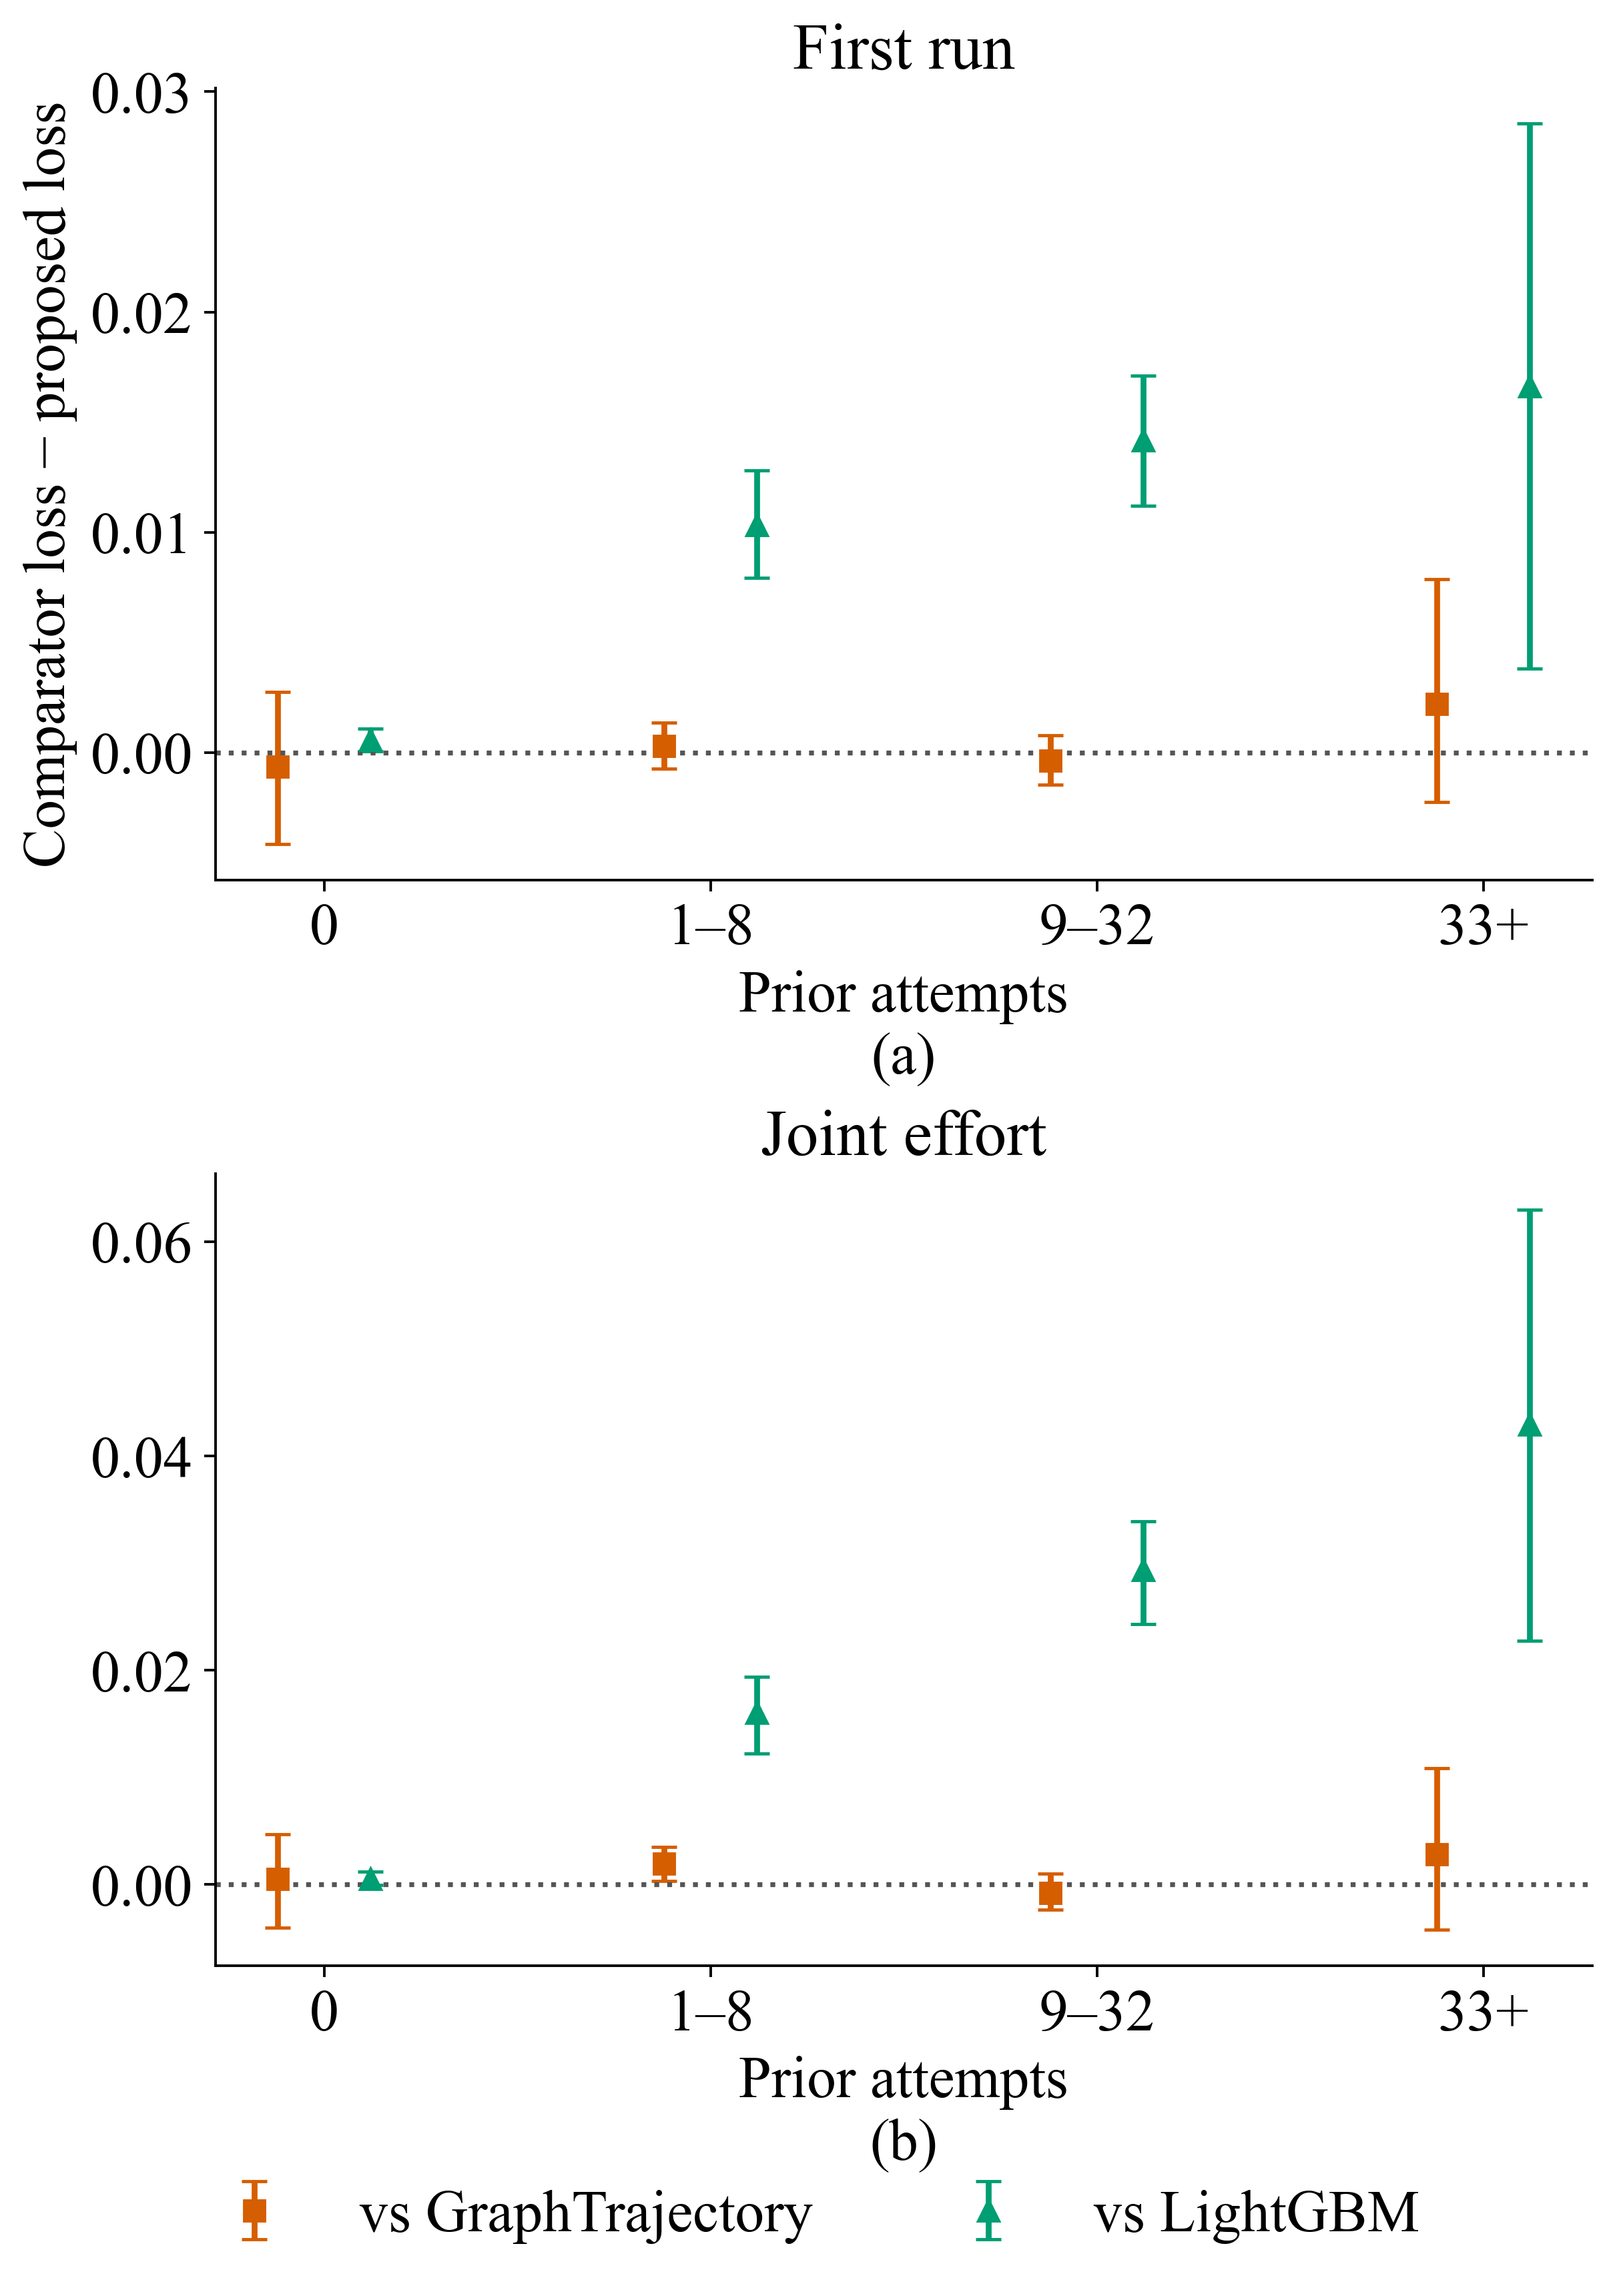

In [22]:
history_effects = strata[strata.Stratum.eq("History")]
groups = list(history_group.cat.categories)
fig, axes = plt.subplots(2, 1, figsize=(6.8, 9.8), layout="constrained")
for ax, (short, title), letter in zip(
    axes, [("LogLoss", "First run"), ("Effort", "Joint effort")], ["a", "b"]
):
    for offset, comparator in zip([-0.12, 0.12], ["GraphTrajectory", "LightGBM"]):
        rows = history_effects[history_effects.Comparator.eq(comparator)]
        positions = np.arange(len(groups)) + offset
        ax.errorbar(
            positions,
            rows[f"Δ{short}"],
            yerr=[
                rows[f"Δ{short}"] - rows[f"Δ{short}_low"],
                rows[f"Δ{short}_high"] - rows[f"Δ{short}"],
            ],
            fmt=MARKERS[comparator],
            color=PALETTE[comparator],
            capsize=4,
            linewidth=1.8,
            label=f"vs {comparator}",
        )
    ax.axhline(0, color=PALETTE["Reference"], linestyle=":")
    ax.set_xticks(np.arange(len(groups)), groups)
    ax.set_title(title)
    panel_label(ax, letter, "Prior attempts")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Comparator loss − proposed loss")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
save_figure(fig, "07_regime_effects")
plt.show()

**Interpretation.** Without history (n = 1,754) the mean expert weight is 0.12, and the hybrid practically coincides with LightGBM (ΔLogLoss 0.00056 [0.00007, 0.00109]). With history the weight rises to 0.70, 0.73 and 0.75, and the advantage over LightGBM grows: 0.01033, 0.01418 and 0.01664 in LogLoss and 0.01599, 0.02932 and 0.04293 in Effort NLL. Against the standalone expert no first-run difference is established in any history group; the difference in Effort NLL is positive only at 1–8 attempts (0.00194 [0.00034, 0.00351]) and in sections 1–3 (0.00147 [0.00033, 0.00256]). In sections 4–6 the expert is more accurate on the first run than the hybrid (0.00225 [0.00005, 0.00426]): there the gate keeps a share of LightGBM although the expert alone would be preferable. The 33+ group and sections 7–9 are small, and their intervals are wide.

### Practical meaning: support decisions

The first scenario models support before a new task: a learner is flagged if the predicted risk of first-run failure $1-p$ is not below the threshold $t$. The net benefit $\mathrm{NB}(t)=\mathrm{TP}/n-\mathrm{FP}/n\cdot t/(1-t)$ is compared with the “support all” strategy. The second scenario identifies visits that will require more than five runs, using $P(r>5)=(1-p)(1-h)^4$; censored records with fewer than five runs are excluded because their status is unknown. This is a retrospective evaluation of rules, not a test of pedagogical effect.

In [23]:
failure = 1 - test_data.y.to_numpy()
failure_rate = failure.mean()
decision_models = ["AlphaProg-AGMT", "GraphTrajectory", "LightGBM", "TabM"]
thresholds = np.round(np.arange(0.30, 0.8001, 0.01), 2)


def benefit_terms(risk: np.ndarray, threshold: float) -> np.ndarray:
    """Per-query contribution to net benefit for a support trigger."""
    flagged = risk >= threshold
    return (flagged & (failure == 1)).astype(float) - (
        flagged & (failure == 0)
    ).astype(float) * threshold / (1 - threshold)


risk = {name: 1 - test_joint[name][:, 0] for name in decision_models}
operating_rows, delta_rows = [], []
for threshold in [0.4, 0.5, 0.6, 0.7]:
    for name in decision_models:
        flagged = risk[name] >= threshold
        tp = np.sum(flagged & (failure == 1))
        fp = np.sum(flagged & (failure == 0))
        fn = np.sum(~flagged & (failure == 1))
        tn = np.sum(~flagged & (failure == 0))
        denominator = np.sqrt(float((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
        operating_rows.append(
            {
                "Model": name,
                "Threshold": threshold,
                "Flagged": flagged.mean(),
                "Sensitivity": tp / (tp + fn),
                "Specificity": tn / (tn + fp),
                "PPV": tp / max(tp + fp, 1),
                "MCC": (tp * tn - fp * fn) / denominator,
                "Net_benefit": benefit_terms(risk[name], threshold).mean(),
                "Treat_all": failure_rate
                - (1 - failure_rate) * threshold / (1 - threshold),
            }
        )
    for comparator in ["GraphTrajectory", "LightGBM", "TabM"]:
        effect = cluster_effect(
            STUDENTS,
            -benefit_terms(risk[comparator], threshold),
            -benefit_terms(risk["AlphaProg-AGMT"], threshold),
        )
        delta_rows.append(
            {
                "Comparator": comparator,
                "Threshold": threshold,
                "ΔNet_benefit": effect["Effect"],
                "CI_low": effect["CI_low"],
                "CI_high": effect["CI_high"],
            }
        )
table(
    pd.DataFrame(operating_rows),
    "Support before a task based on the risk of first-run failure: share flagged, sensitivity, specificity, PPV, MCC, net benefit ↑",
    "07_support_operating_points",
)
table(
    pd.DataFrame(delta_rows),
    "Net-benefit difference AlphaProg-AGMT − comparator (> 0 favours AlphaProg-AGMT); 95% CI over learners",
    "07_support_net_benefit",
)

Support before a task based on the risk of first-run failure: share flagged, sensitivity, specificity, PPV, MCC, net benefit ↑

,Model,Threshold,Flagged,Sensitivity,Specificity,PPV,MCC,Net_benefit,Treat_all
0,AlphaProg-AGMT,0.4,0.65850,0.83730,0.57577,0.72114,0.43158,0.35245,0.27857
1,GraphTrajectory,0.4,0.65260,0.83214,0.58263,0.72317,0.43160,0.35150,0.27857
2,LightGBM,0.4,0.66658,0.83645,0.55599,0.71167,0.41245,0.34626,0.27857
3,TabM,0.4,0.66217,0.83329,0.56205,0.71371,0.41415,0.34622,0.27857
4,AlphaProg-AGMT,0.5,0.55697,0.75198,0.69855,0.76572,0.44938,0.29600,0.13429
5,GraphTrajectory,0.5,0.55181,0.74813,0.70541,0.76891,0.45187,0.29678,0.13429
6,LightGBM,0.5,0.56478,0.75475,0.68412,0.75791,0.43860,0.29132,0.13429
7,TabM,0.5,0.54601,0.73620,0.70319,0.76470,0.43726,0.28905,0.13429
8,AlphaProg-AGMT,0.6,0.44500,0.64449,0.81638,0.82139,0.45949,0.24630,-0.08214
9,GraphTrajectory,0.6,0.44504,0.64434,0.81608,0.82112,0.45903,0.24602,-0.08214


Net-benefit difference AlphaProg-AGMT − comparator (> 0 favours AlphaProg-AGMT); 95% CI over learners

,Comparator,Threshold,ΔNet_benefit,CI_low,CI_high
0,GraphTrajectory,0.4,0.00095,-0.00062,0.00246
1,LightGBM,0.4,0.00619,0.00389,0.00845
2,TabM,0.4,0.00623,0.00380,0.00840
3,GraphTrajectory,0.5,-0.00079,-0.00292,0.00113
4,LightGBM,0.5,0.00467,0.00168,0.00776
5,TabM,0.5,0.00694,0.00378,0.01026
6,GraphTrajectory,0.6,0.00028,-0.00232,0.00275
7,LightGBM,0.6,0.00956,0.00608,0.01298
8,TabM,0.6,0.01015,0.00648,0.01397
9,GraphTrajectory,0.7,0.00054,-0.00195,0.00301


In [24]:
runs = test_data.effort_runs.to_numpy()
observed = test_data.effort_observed.to_numpy().astype(bool)
long_effort = (observed & (runs > 5)) | (~observed & (runs >= 5))
known_status = long_effort | (observed & (runs <= 5))
label = long_effort[known_status].astype(int)
known_students = STUDENTS[known_status]


def long_effort_score(joint: np.ndarray) -> np.ndarray:
    """Probability that the first success needs more than five runs."""
    return (1 - joint[:, 0]) * np.power(1 - joint[:, 1], 4)


scores = {
    name: long_effort_score(test_joint[name])[known_status] for name in decision_models
}


def top_capture(score: np.ndarray, truth: np.ndarray, share: float = 0.1) -> float:
    """Recall of long-effort visits among the highest-scored share."""
    selected = score >= np.quantile(score, 1 - share)
    return truth[selected].sum() / truth.sum()


known_codes = pd.factorize(known_students)[0]
n_known_learners = known_codes.max() + 1
generator = np.random.default_rng(SEED)
draws = generator.multinomial(
    n_known_learners, np.full(n_known_learners, 1 / n_known_learners), size=1000
)
bootstrap_auc = {name: [] for name in decision_models}
for weights in draws:
    # Drawing a learner k times equals weighting each of its rows by k.
    row_weight = weights[known_codes]
    for name in decision_models:
        bootstrap_auc[name].append(
            roc_auc_score(label, scores[name], sample_weight=row_weight)
        )
long_rows = []
for name in decision_models:
    difference = np.asarray(bootstrap_auc["AlphaProg-AGMT"]) - np.asarray(
        bootstrap_auc[name]
    )
    long_rows.append(
        {
            "Model": name,
            "n_known": int(known_status.sum()),
            "Long_effort_share": label.mean(),
            "AUROC": roc_auc_score(label, scores[name]),
            "AP": average_precision_score(label, scores[name]),
            "Top10_capture": top_capture(scores[name], label),
            "ΔAUROC_proposed_minus_model": roc_auc_score(label, scores["AlphaProg-AGMT"])
            - roc_auc_score(label, scores[name]),
            "CI_low": float(np.quantile(difference, 0.025)),
            "CI_high": float(np.quantile(difference, 0.975)),
        }
    )
table(
    pd.DataFrame(long_rows),
    f"Identification of visits requiring more than five runs; excluding {int((~known_status).sum())} censored records with unknown status; ΔAUROC with 95% CI over learners",
    "07_long_effort_identification",
)

Identification of visits requiring more than five runs; excluding 1254 censored records with unknown status; ΔAUROC with 95% CI over learners

,Model,n_known,Long_effort_share,AUROC,AP,Top10_capture,ΔAUROC_proposed_minus_model,CI_low,CI_high
0,AlphaProg-AGMT,21645,0.17103,0.86304,0.60199,0.39222,0.00000,0.00000,0.00000
1,GraphTrajectory,21645,0.17103,0.86304,0.60013,0.39141,-0.00000,-0.00081,0.00075
2,LightGBM,21645,0.17103,0.85389,0.57532,0.37412,0.00916,0.00727,0.01112
3,TabM,21645,0.17103,0.85393,0.57645,0.37871,0.00911,0.00724,0.01110


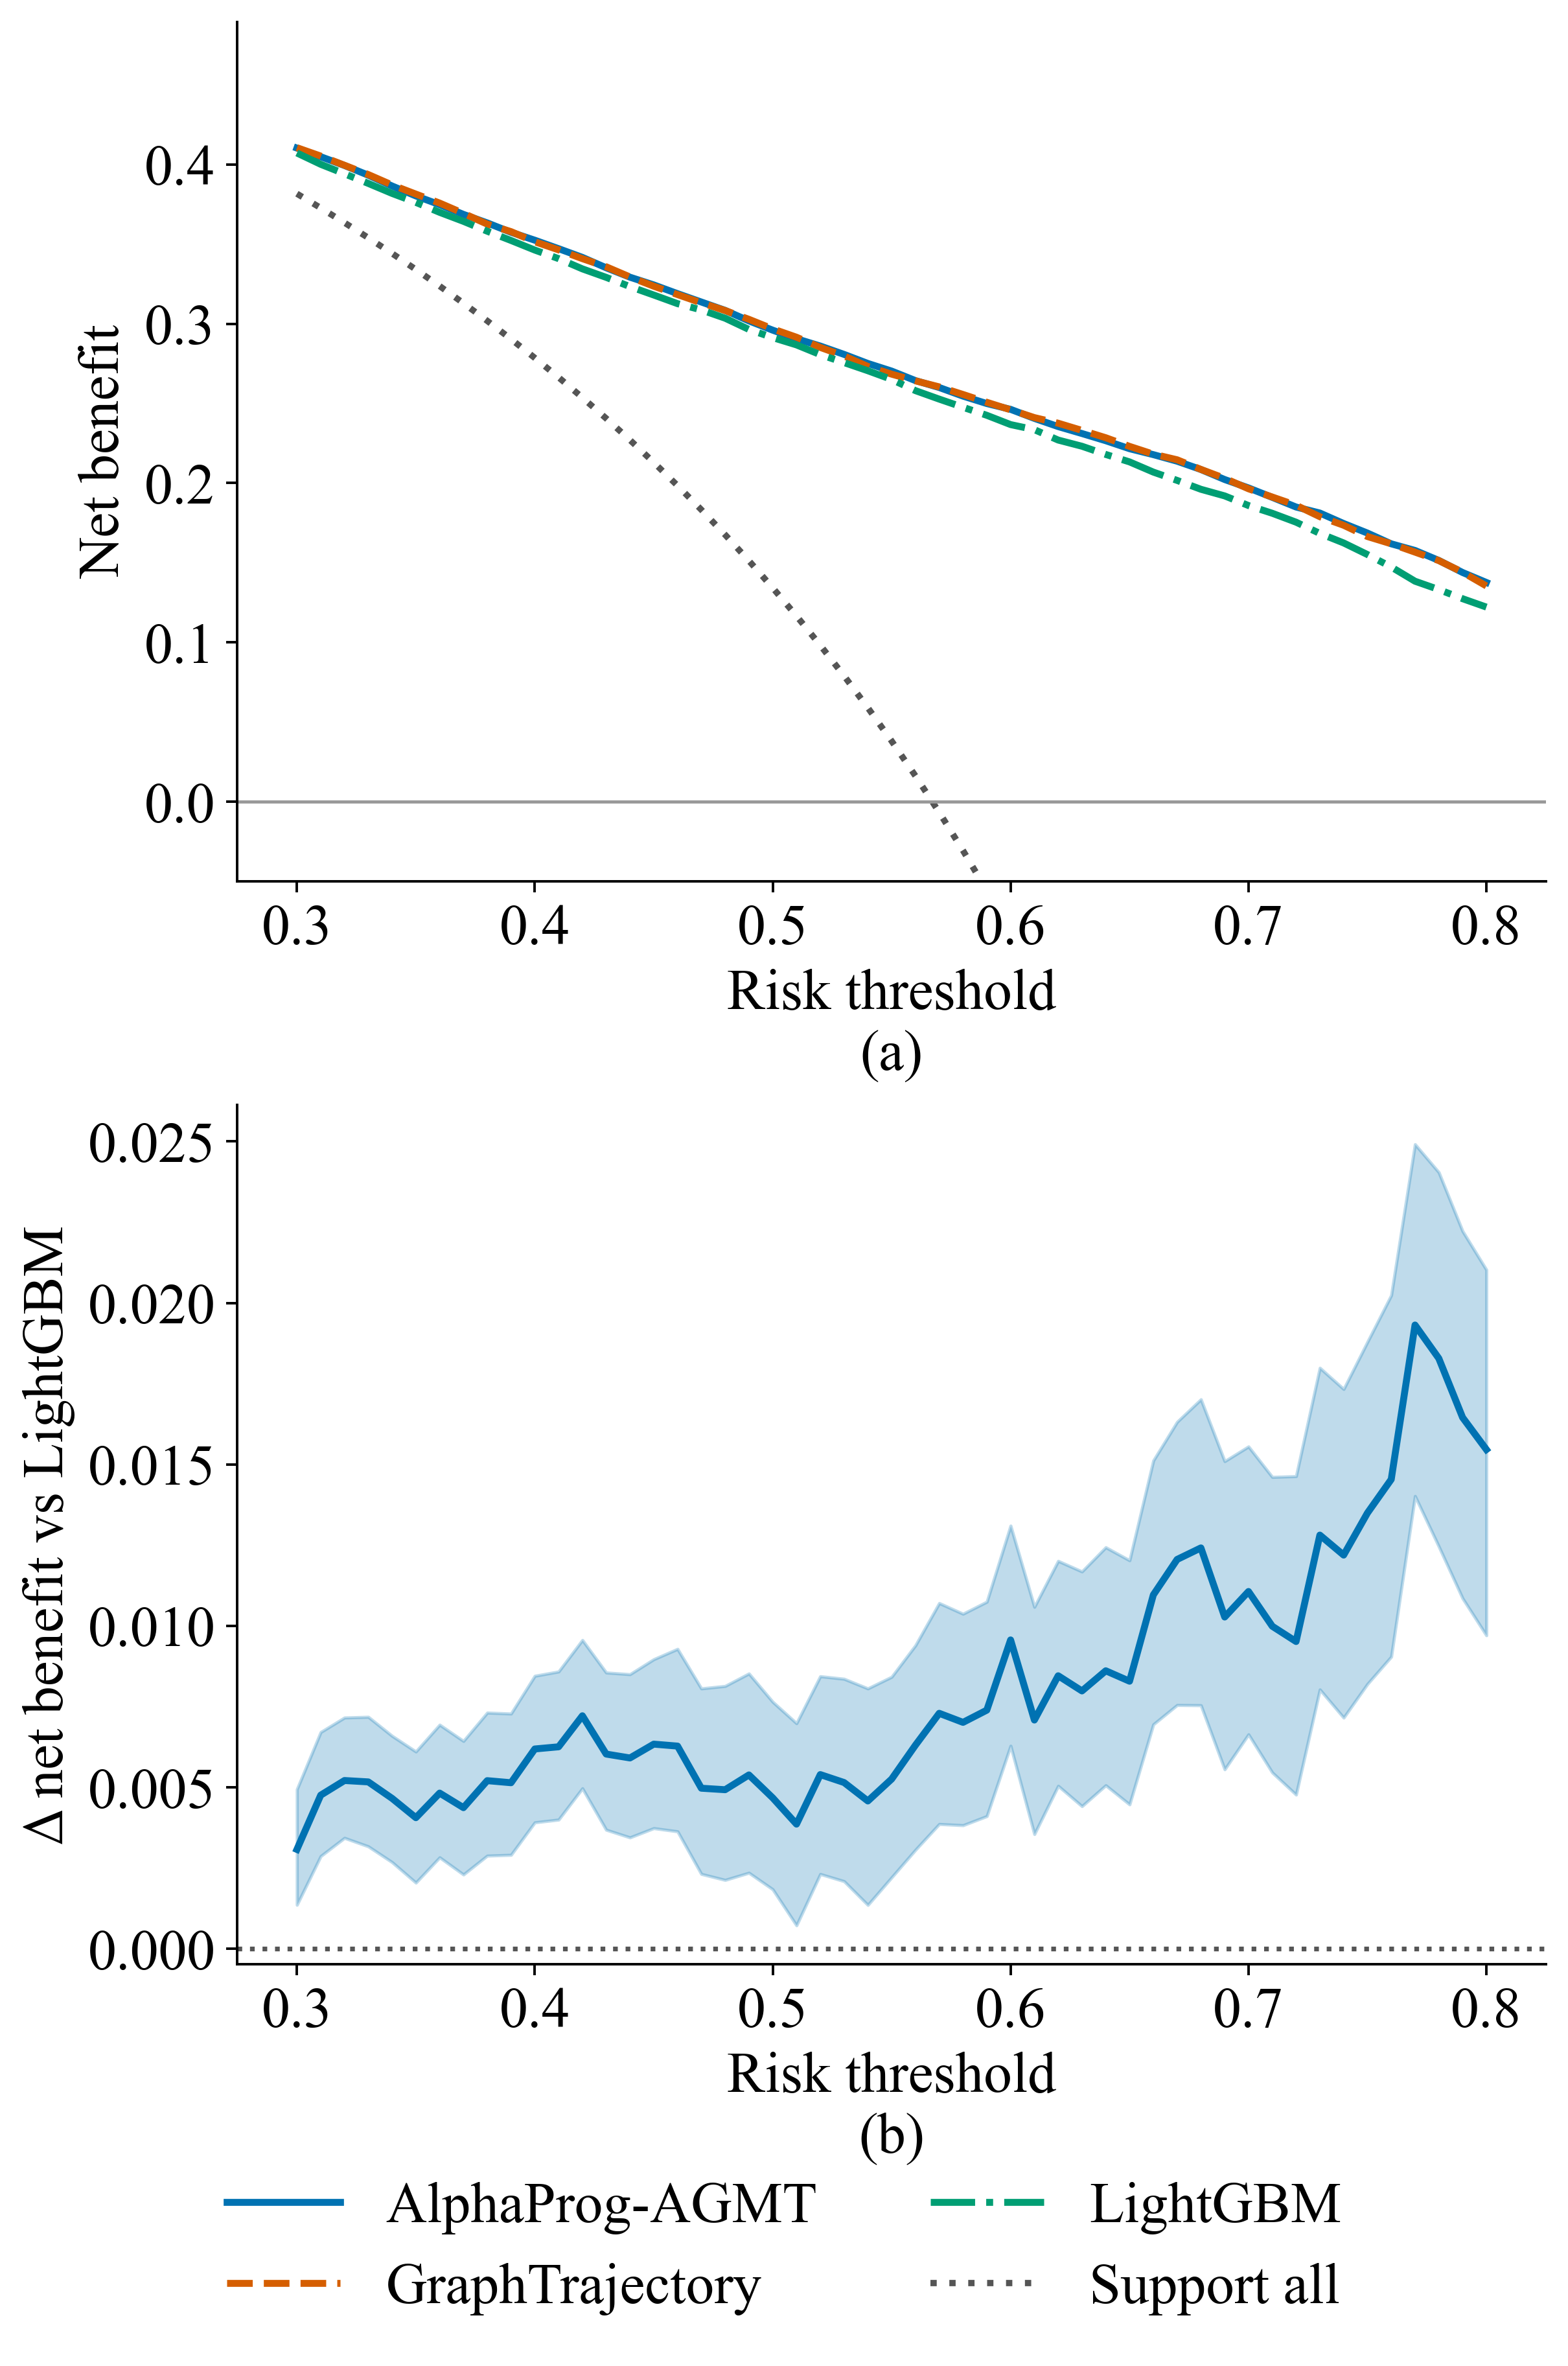

In [25]:
curve_rows = []
benefit_matrix = {
    name: np.column_stack([benefit_terms(risk[name], t) for t in thresholds])
    for name in decision_models
}
learner_codes, learner_ids = pd.factorize(STUDENTS)
sizes = np.bincount(learner_codes)
generator = np.random.default_rng(SEED)
draws = generator.multinomial(
    len(sizes), np.full(len(sizes), 1 / len(sizes)), size=1000
)
difference = benefit_matrix["AlphaProg-AGMT"] - benefit_matrix["LightGBM"]
sums = np.vstack(
    [np.bincount(learner_codes, weights=difference[:, j]) for j in range(len(thresholds))]
).T
replicates = (draws @ sums) / (draws @ sizes)[:, None]
band_low, band_high = np.quantile(replicates, [0.025, 0.975], axis=0)
fig, axes = plt.subplots(2, 1, figsize=(6.8, 10.4), layout="constrained")
for name in ["AlphaProg-AGMT", "GraphTrajectory", "LightGBM"]:
    axes[0].plot(
        thresholds,
        benefit_matrix[name].mean(axis=0),
        color=PALETTE[name],
        linestyle=LINESTYLES[name],
        linewidth=2.2,
        label=name,
    )
axes[0].plot(
    thresholds,
    failure_rate - (1 - failure_rate) * thresholds / (1 - thresholds),
    color=PALETTE["Reference"],
    linestyle=(0, (1, 2)),
    linewidth=2,
    label="Support all",
)
axes[0].axhline(0, color="#999999", linewidth=1)
axes[0].set_ylim(bottom=-0.05)
axes[0].set_ylabel("Net benefit")
panel_label(axes[0], "a", "Risk threshold")
axes[1].fill_between(
    thresholds, band_low, band_high, color=PALETTE["AlphaProg-AGMT"], alpha=0.25
)
axes[1].plot(
    thresholds,
    difference.mean(axis=0),
    color=PALETTE["AlphaProg-AGMT"],
    linewidth=2.2,
)
axes[1].axhline(0, color=PALETTE["Reference"], linestyle=":")
axes[1].set_ylabel("Δ net benefit vs LightGBM")
panel_label(axes[1], "b", "Risk threshold")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
save_figure(fig, "07_support_decision_curves")
plt.show()

**Interpretation.** At risk thresholds of 0.4–0.7 all models clearly outperform the “support all” strategy. The net benefit of AlphaProg-AGMT exceeds that of LightGBM by 0.0047–0.0111 per query and that of TabM by 0.0062–0.0160 (all 95% CIs above zero); against the standalone expert no difference is established at any threshold. At the 0.5 threshold the difference from LightGBM corresponds to about 4.7 additional net correctly flagged failures per 1,000 first visits. For identifying visits that require more than five runs (17.1% of records with known status), the AUROC of the hybrid is 0.863 versus 0.854 for LightGBM (Δ 0.0092 [0.0073, 0.0111]) and 0.863 for the expert (Δ 0.0000 [−0.0008, 0.0008]). The effects are small and refer to retrospective rules, not to a tested pedagogical intervention.

### Censoring and the constant-hazard assumption

A record is censored if the first visit ended without a successful run. First, it is checked whether censoring depends on observed features: an out-of-fold (OOF) LightGBM model with frozen settings predicts censoring among failed first runs. Next, the observed hazard by run number is compared with the mean predicted hazard h in the same risk set (columns Mean_q). Then two alternative specifications are evaluated: a hazard that depends on the run number (corrections estimated on validation), and IPCW with censoring curves estimated within “section × presence of history” strata.

In [26]:
censoring_rows = []
for split, frame in [("Train", train_data), ("Locked test", test_data)]:
    failed = frame[frame.y.eq(0)]
    censored = failed.effort_observed.eq(0)
    censoring_rows.append(
        {
            "Split": split,
            "Failed_first_runs": len(failed),
            "Later_success": int((~censored).sum()),
            "Censored": int(censored.sum()),
            "Censored_share": censored.mean(),
            "Median_runs_censored": float(failed.loc[censored, "effort_runs"].median()),
            "Median_runs_success": float(failed.loc[~censored, "effort_runs"].median()),
        }
    )
failed_train = train_data[train_data.y.eq(0)].reset_index(drop=True)
failed_test = test_data[test_data.y.eq(0)].reset_index(drop=True)
censor_target = 1 - failed_train.effort_observed.to_numpy()
censor_oof = np.full(len(failed_train), np.nan)
lightgbm_settings = json.loads(
    (ROOT / "Protocol/baseline_configurations.json").read_text()
)["LightGBM"]
for fold in sorted(failed_train.fold.unique()):
    held = failed_train.fold.eq(fold).to_numpy()
    preprocessing = ns03["make_preprocessor"]()
    fit_matrix = ns03["transformed_frame"](
        preprocessing.fit_transform(failed_train.loc[~held, ns03["feature_names"]])
    )
    held_matrix = ns03["transformed_frame"](
        preprocessing.transform(failed_train.loc[held, ns03["feature_names"]])
    )
    estimator = ns03["make_estimator"]("LightGBM", lightgbm_settings, SEEDS[0])
    estimator.fit(fit_matrix, censor_target[~held])
    censor_oof[held] = estimator.predict_proba(held_matrix)[:, 1]
preprocessing = ns03["make_preprocessor"]()
fit_matrix = ns03["transformed_frame"](
    preprocessing.fit_transform(failed_train[ns03["feature_names"]])
)
estimator = ns03["make_estimator"]("LightGBM", lightgbm_settings, SEEDS[0])
estimator.fit(fit_matrix, censor_target)
censor_test = estimator.predict_proba(
    ns03["transformed_frame"](preprocessing.transform(failed_test[ns03["feature_names"]]))
)[:, 1]


def clustered_auc_interval(truth, score, students, repetitions=1000):
    """Learner-cluster bootstrap interval for AUROC via multiplicity weights."""
    codes = pd.factorize(students)[0]
    count = codes.max() + 1
    generator = np.random.default_rng(SEED)
    draws = generator.multinomial(count, np.full(count, 1 / count), size=repetitions)
    values = [roc_auc_score(truth, score, sample_weight=w[codes]) for w in draws]
    return np.quantile(values, [0.025, 0.975])


for row, truth, score, students in [
    (censoring_rows[0], censor_target, censor_oof, failed_train.student.to_numpy()),
    (
        censoring_rows[1],
        1 - failed_test.effort_observed.to_numpy(),
        censor_test,
        failed_test.student.to_numpy(),
    ),
]:
    low, high = clustered_auc_interval(truth, score, students)
    row.update({"Censoring_AUROC": roc_auc_score(truth, score), "CI_low": low, "CI_high": high})
table(
    pd.DataFrame(censoring_rows),
    "Censoring among failed first runs and its predictability from observed features (AUROC; train — out-of-fold, test — train model)",
    "07_censoring_summary",
)

Censoring among failed first runs and its predictability from observed features (AUROC; train — out-of-fold, test — train model)

,Split,Failed_first_runs,Later_success,Censored,Censored_share,Median_runs_censored,Median_runs_success,Censoring_AUROC,CI_low,CI_high
0,Train,61752,51436,10316,0.16706,4.0,3.0,0.79433,0.78920,0.79932
1,Locked test,12987,10801,2186,0.16832,4.0,3.0,0.79729,0.78526,0.80821


In [27]:
def person_period(frame: pd.DataFrame) -> pd.DataFrame:
    """Expand failed first runs into run-level risk records from run 2 onward."""
    failed = np.flatnonzero(frame.y.to_numpy() == 0)
    runs = frame.effort_runs.to_numpy()[failed]
    event = frame.effort_observed.to_numpy()[failed]
    rows, run_index, outcome = [], [], []
    for position, total, observed_success in zip(failed, runs, event):
        for run in range(2, int(total) + 1):
            rows.append(position)
            run_index.append(run)
            outcome.append(int(observed_success and run == total))
    return pd.DataFrame({"row": rows, "run": run_index, "event": outcome})


RUN_GROUPS = [(2, 2), (3, 3), (4, 4), (5, 5), (6, 10), (11, 10**6)]
RUN_GROUP_NAMES = ["2", "3", "4", "5", "6–10", "11+"]


def run_group(run: np.ndarray) -> np.ndarray:
    return np.select([(run >= a) & (run <= b) for a, b in RUN_GROUPS], range(len(RUN_GROUPS)))


test_periods = person_period(test_data)
life_rows = []
for run in range(2, 11):
    at_risk = test_periods[test_periods.run.eq(run)]
    observed_hazard, low, high = ns06["learner_mean_interval"](
        at_risk.event.to_numpy(), STUDENTS[at_risk.row.to_numpy()], 1000
    )
    row = {
        "Run": run,
        "At_risk": len(at_risk),
        "Observed_hazard": observed_hazard,
        "CI_low": low,
        "CI_high": high,
    }
    for name in ["AlphaProg-AGMT", "GraphTrajectory", "LightGBM"]:
        row[f"Mean_q_{name}"] = float(test_joint[name][at_risk.row.to_numpy(), 1].mean())
    life_rows.append(row)
life_table = pd.DataFrame(life_rows)
table(
    life_table,
    "Observed hazard of success by run number among learners in the risk set and mean predicted q in the same set (locked test)",
    "07_tail_hazard_life_table",
)

Observed hazard of success by run number among learners in the risk set and mean predicted q in the same set (locked test)

,Run,At_risk,Observed_hazard,CI_low,CI_high,Mean_q_AlphaProg-AGMT,Mean_q_GraphTrajectory,Mean_q_LightGBM
0,2,12539,0.31302,0.30370,0.32289,0.28175,0.28433,0.27622
1,3,8267,0.23818,0.22861,0.24732,0.23424,0.23536,0.23240
2,4,6045,0.20463,0.19410,0.21491,0.20876,0.20926,0.20881
3,5,4602,0.19557,0.18311,0.20828,0.19195,0.19219,0.19296
4,6,3544,0.16817,0.15767,0.17986,0.17876,0.17874,0.18043
5,7,2830,0.15159,0.13882,0.16475,0.17043,0.17035,0.17273
6,8,2307,0.13264,0.11791,0.14660,0.16123,0.16085,0.16445
7,9,1913,0.13278,0.11590,0.14973,0.15433,0.15374,0.15805
8,10,1585,0.14826,0.13115,0.16586,0.14924,0.14851,0.15349


In [28]:
validation_joint = {
    "AlphaProg-AGMT": seed_average(
        [experiments["gates"][("AlphaProg-AGMT", seed)]["validation_probability"] for seed in SEEDS]
    ),
    "GraphTrajectory": seed_average(
        [experiments["components"][("FullGraph", seed)]["validation"] for seed in SEEDS]
    ),
    "LightGBM": seed_average(
        [
            np.c_[
                ns05["aligned_base_probability"](validation_data, "Validation", seed),
                experiments["hazards"][seed]["validation"],
            ]
            for seed in SEEDS
        ]
    ),
}
validation_periods = person_period(validation_data)


def fit_run_offsets(joint: np.ndarray, periods: pd.DataFrame) -> np.ndarray:
    """Estimate run-group offsets on the logit hazard scale."""
    base_logit = logit(np.clip(joint[periods.row.to_numpy(), 1], 1e-6, 1 - 1e-6))
    groups = run_group(periods.run.to_numpy())
    event = periods.event.to_numpy()

    def objective(gamma):
        hazard = expit(base_logit + gamma[groups])
        hazard = np.clip(hazard, 1e-9, 1 - 1e-9)
        value = -(event * np.log(hazard) + (1 - event) * np.log1p(-hazard)).sum()
        gradient = np.bincount(groups, weights=hazard - event, minlength=len(RUN_GROUPS))
        return value, gradient

    result = minimize(objective, np.zeros(len(RUN_GROUPS)), jac=True, method="L-BFGS-B")
    assert result.success
    return result.x


def run_varying_losses(frame, joint, periods, gamma):
    """Per-query joint NLL when the tail hazard varies by run group."""
    hazard = expit(
        logit(np.clip(joint[periods.row.to_numpy(), 1], 1e-6, 1 - 1e-6))
        + gamma[run_group(periods.run.to_numpy())]
    )
    hazard = np.clip(hazard, 1e-6, 1 - 1e-6)
    event = periods.event.to_numpy()
    tail = -(event * np.log(hazard) + (1 - event) * np.log1p(-hazard))
    tail_by_query = np.bincount(periods.row.to_numpy(), weights=tail, minlength=len(frame))
    first = binary_loss(frame.y.to_numpy(), joint[:, 0])
    return first + tail_by_query


def run_varying_cdf(joint, gamma, horizon):
    """P(T <= horizon) under run-group-specific tail hazards."""
    survival = 1 - joint[:, 0]
    for run in range(2, horizon + 1):
        hazard = expit(
            logit(np.clip(joint[:, 1], 1e-6, 1 - 1e-6)) + gamma[run_group(np.array([run]))[0]]
        )
        survival = survival * (1 - hazard)
    return 1 - survival


def ipcw_brier_probability(frame, probability, horizon, times, survival):
    """IPCW Brier score for an arbitrary forecast of P(T <= horizon)."""
    helper = np.c_[probability, np.zeros(len(frame))]
    contributions = ns06["horizon_ipcw"](frame, helper, horizon, times, survival)
    return float(contributions.Brier_contribution.mean())


offset_rows, specification_rows = [], []
run_varying_test_losses = {}
for name in ["AlphaProg-AGMT", "GraphTrajectory", "LightGBM"]:
    gamma = fit_run_offsets(validation_joint[name], validation_periods)
    offset_rows.append({"Model": name, **dict(zip([f"γ_run_{g}" for g in RUN_GROUP_NAMES], gamma))})
    losses = run_varying_losses(test_data, test_joint[name], test_periods, gamma)
    run_varying_test_losses[name] = losses
    for specification, effort, briers in [
        (
            "Constant hazard",
            test_losses[name]["Effort NLL"].mean(),
            [ipcw_brier(test_data, test_joint[name], h) for h in [3, 5, 10]],
        ),
        (
            "Run-varying hazard",
            losses.mean(),
            [
                ipcw_brier_probability(
                    test_data, run_varying_cdf(test_joint[name], gamma, h), h,
                    censor_times, censor_probability,
                )
                for h in [3, 5, 10]
            ],
        ),
    ]:
        specification_rows.append(
            {
                "Model": name,
                "Specification": specification,
                "Effort_NLL": effort,
                "Brier_run_3": briers[0],
                "Brier_run_5": briers[1],
                "Brier_run_10": briers[2],
            }
        )
specification_effect_rows = []
for comparator in ["GraphTrajectory", "LightGBM"]:
    specification_effect_rows.append(
        {
            "Comparator": comparator,
            "Specification": "Run-varying hazard",
            **cluster_effect(
                STUDENTS,
                run_varying_test_losses[comparator],
                run_varying_test_losses["AlphaProg-AGMT"],
            ),
        }
    )
table(
    pd.DataFrame(offset_rows),
    "Corrections γ to the logit hazard by run-number group, estimated on validation (0 corresponds to a constant hazard)",
    "07_run_offsets",
)
table(
    pd.DataFrame(specification_rows),
    "Joint NLL and IPCW Brier under a constant and a run-number-dependent hazard (locked test) ↓",
    "07_hazard_specification",
)
table(
    pd.DataFrame(specification_effect_rows),
    "Effort NLL comparator − AlphaProg-AGMT under a run-number-dependent hazard; 95% CI over learners",
    "07_hazard_specification_effects",
)

Corrections γ to the logit hazard by run-number group, estimated on validation (0 corresponds to a constant hazard)

,Model,γ_run_2,γ_run_3,γ_run_4,γ_run_5,γ_run_6–10,γ_run_11+
0,AlphaProg-AGMT,0.15474,0.02284,0.01391,-0.07587,-0.18084,-0.37339
1,GraphTrajectory,0.14001,0.01446,0.01007,-0.07753,-0.17784,-0.35691
2,LightGBM,0.18654,0.03567,0.01367,-0.08358,-0.20719,-0.44835


Joint NLL and IPCW Brier under a constant and a run-number-dependent hazard (locked test) ↓

,Model,Specification,Effort_NLL,Brier_run_3,Brier_run_5,Brier_run_10
0,AlphaProg-AGMT,Constant hazard,1.55618,0.13902,0.10560,0.05823
1,AlphaProg-AGMT,Run-varying hazard,1.55224,0.13903,0.10562,0.05830
2,GraphTrajectory,Constant hazard,1.55691,0.13880,0.10568,0.05852
3,GraphTrajectory,Run-varying hazard,1.55343,0.13881,0.10568,0.05870
4,LightGBM,Constant hazard,1.57781,0.14379,0.10917,0.05974
5,LightGBM,Run-varying hazard,1.57189,0.14377,0.10919,0.05973


Effort NLL comparator − AlphaProg-AGMT under a run-number-dependent hazard; 95% CI over learners

,Comparator,Specification,Effect,CI_low,CI_high,p_raw
0,GraphTrajectory,Run-varying hazard,0.00119,0.00009,0.00225,0.04198
1,LightGBM,Run-varying hazard,0.01965,0.01706,0.02226,0.00050


In [29]:
def stratum_codes(frame: pd.DataFrame) -> np.ndarray:
    section = pd.cut(frame.q_level, [0, 3, 6, 9], labels=False).to_numpy()
    return section * 2 + frame.history_available.to_numpy().astype(int)


train_strata, test_strata = stratum_codes(train_data), stratum_codes(test_data)
stratified_rows = []
for name in ["AlphaProg-AGMT", "GraphTrajectory", "LightGBM"]:
    row = {"Model": name}
    for horizon in [3, 5, 10]:
        contributions = []
        for code in np.unique(test_strata):
            times, survival = ns06["censoring_survival"](train_data[train_strata == code])
            retained = test_strata == code
            contributions.append(
                ns06["horizon_ipcw"](
                    test_data[retained].reset_index(drop=True),
                    test_joint[name][retained],
                    horizon,
                    times,
                    survival,
                ).Brier_contribution.to_numpy()
            )
        row[f"Pooled_Brier_{horizon}"] = ipcw_brier(test_data, test_joint[name], horizon)
        row[f"Stratified_Brier_{horizon}"] = float(np.concatenate(contributions).mean())
    stratified_rows.append(row)
table(
    pd.DataFrame(stratified_rows),
    "IPCW Brier at runs 3, 5 and 10: overall censoring curve and curves within 6 “section × presence of history” strata ↓",
    "07_stratified_ipcw",
)

IPCW Brier at runs 3, 5 and 10: overall censoring curve and curves within 6 “section × presence of history” strata ↓

,Model,Pooled_Brier_3,Stratified_Brier_3,Pooled_Brier_5,Stratified_Brier_5,Pooled_Brier_10,Stratified_Brier_10
0,AlphaProg-AGMT,0.13902,0.13861,0.10560,0.10507,0.05823,0.05804
1,GraphTrajectory,0.13880,0.13839,0.10568,0.10512,0.05852,0.05834
2,LightGBM,0.14379,0.14341,0.10917,0.10873,0.05974,0.05967


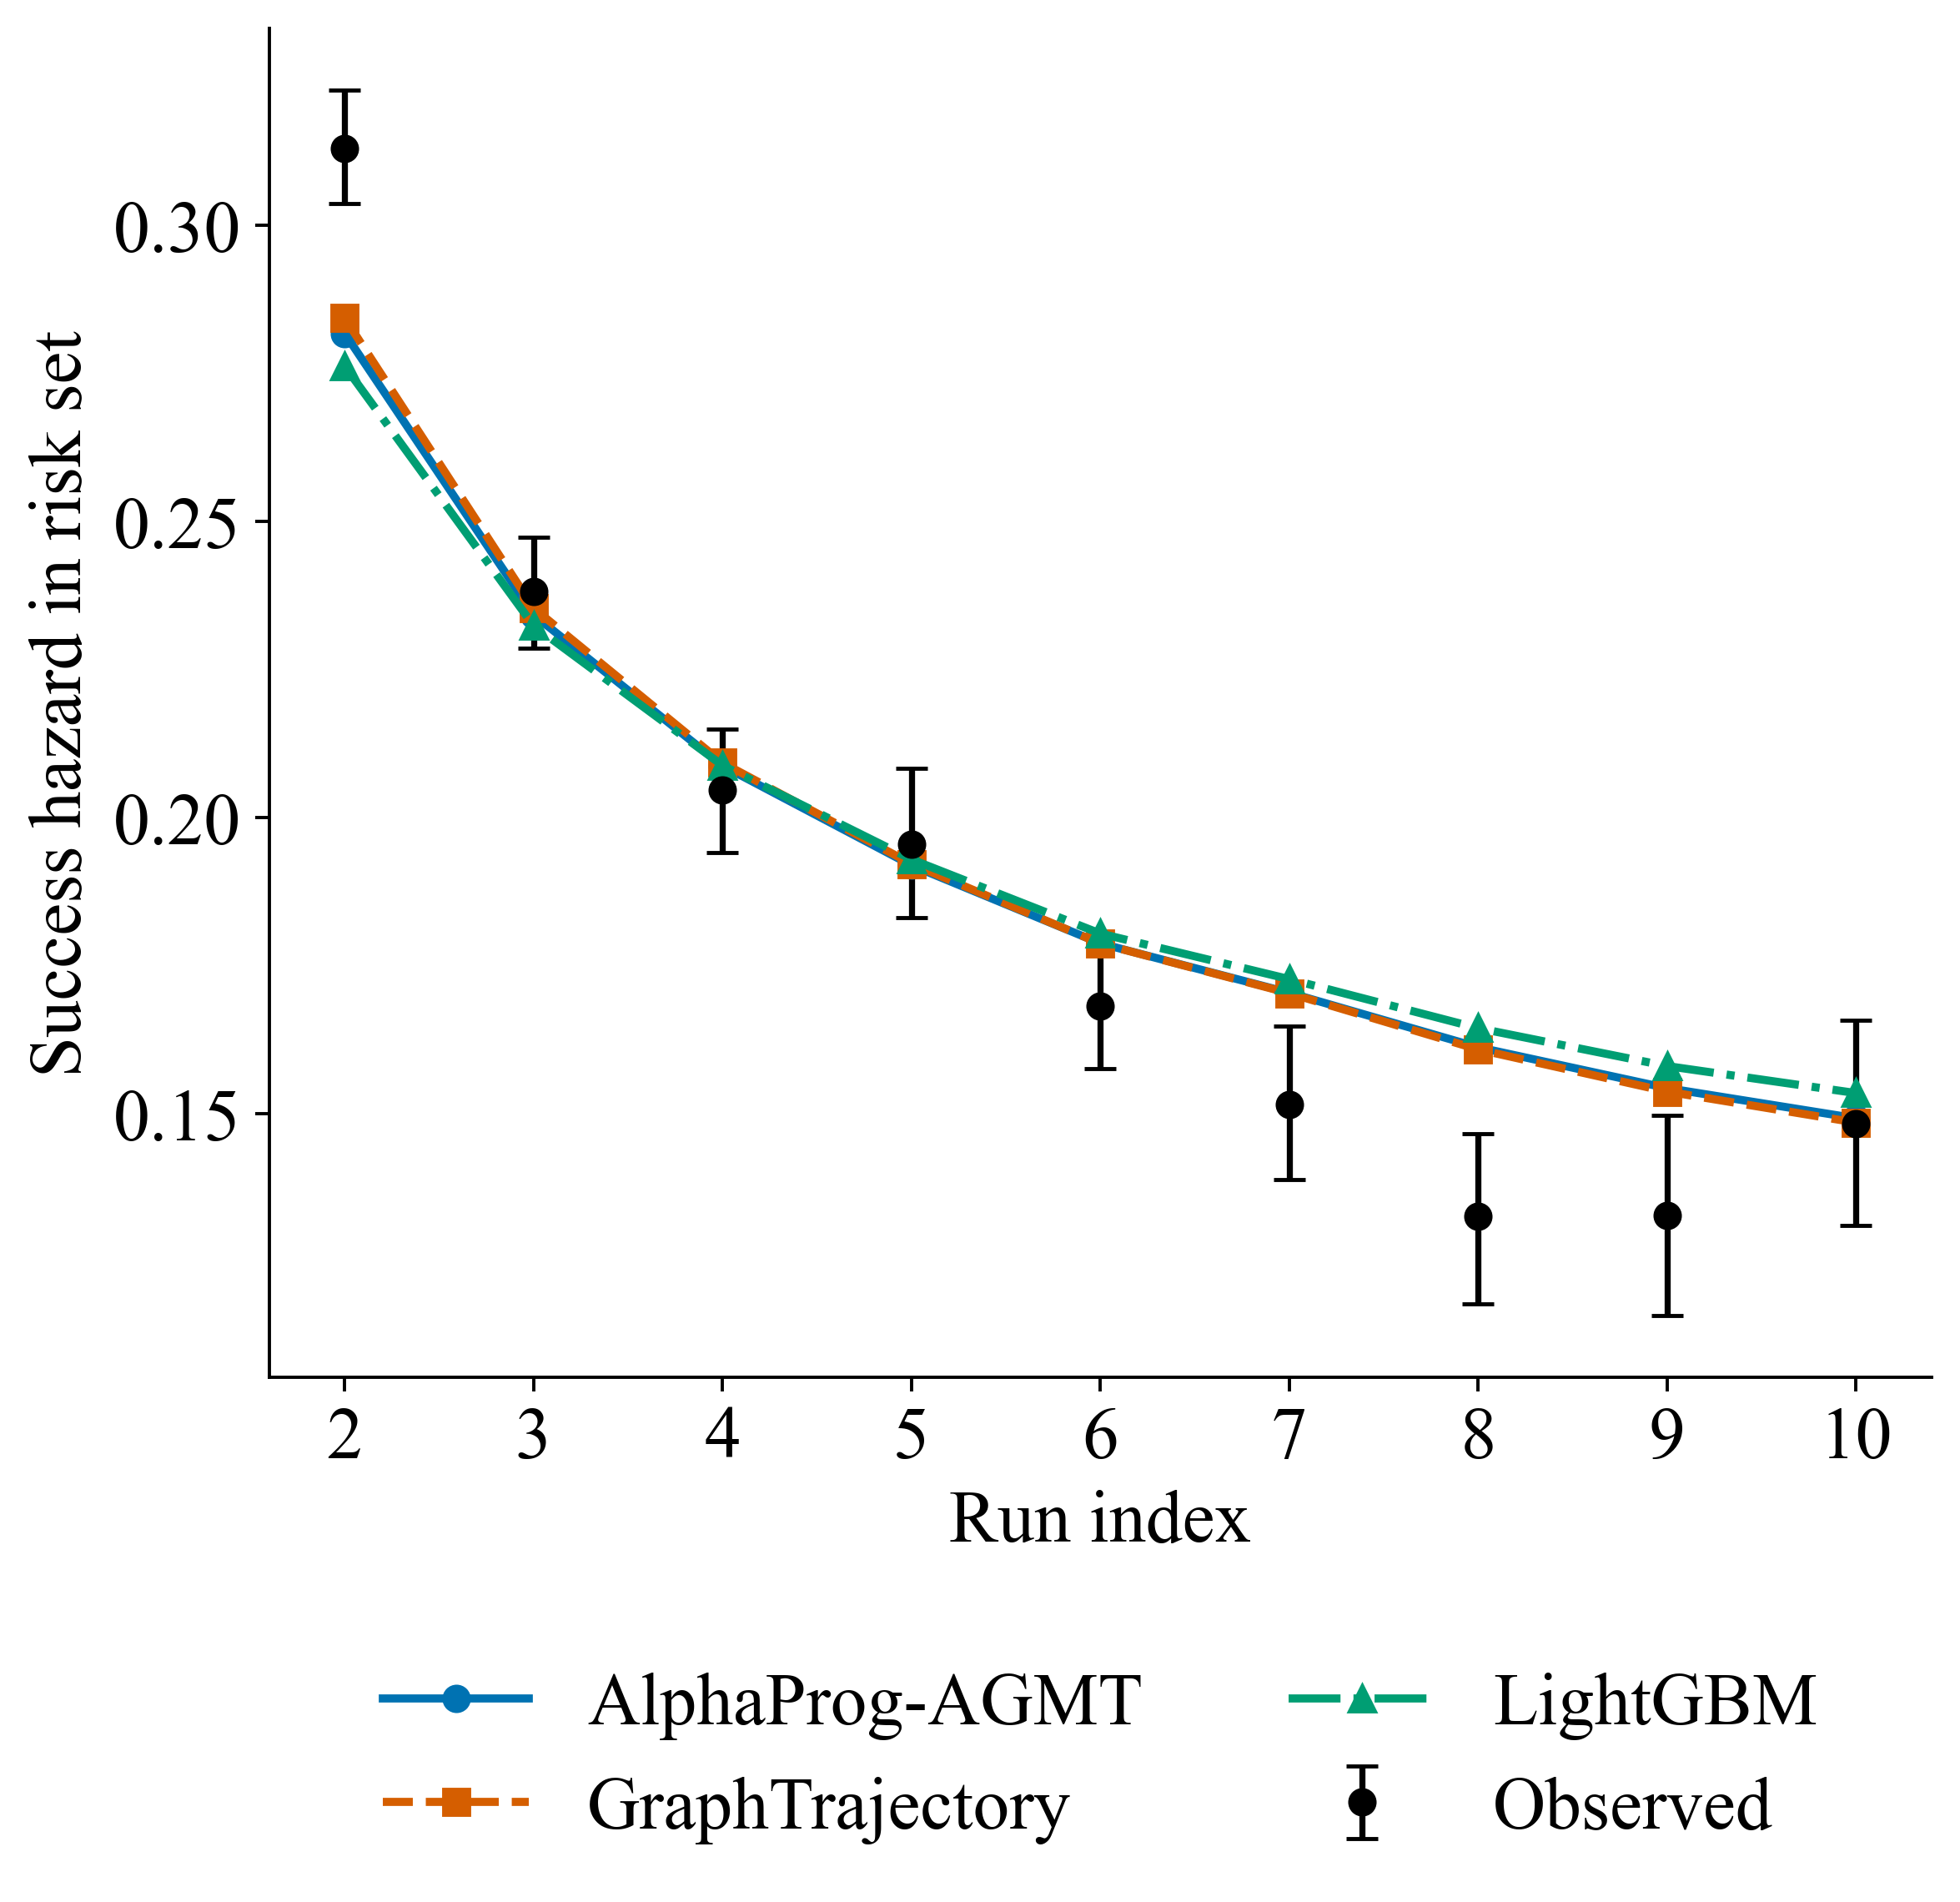

In [30]:
fig, ax = plt.subplots(figsize=(6.6, 6.4), layout="constrained")
ax.errorbar(
    life_table.Run,
    life_table.Observed_hazard,
    yerr=[
        life_table.Observed_hazard - life_table.CI_low,
        life_table.CI_high - life_table.Observed_hazard,
    ],
    fmt="o",
    color="#000000",
    capsize=4,
    label="Observed",
)
for name in ["AlphaProg-AGMT", "GraphTrajectory", "LightGBM"]:
    ax.plot(
        life_table.Run,
        life_table[f"Mean_q_{name}"],
        color=PALETTE[name],
        linestyle=LINESTYLES[name],
        marker=MARKERS[name],
        linewidth=2,
        label=name,
    )
ax.set(xlabel="Run index", ylabel="Success hazard in risk set")
ax.set_xticks(life_table.Run)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2, frameon=False)
save_figure(fig, "07_tail_hazard_life_table")
plt.show()

**Interpretation.** Of the failed first runs, 16.7% are censored in train and 16.8% in the test. Censoring is well predicted by observed features (AUROC 0.794 out of fold; 0.797 on the test), so independent censoring does not hold, and censoring that depends on observed features is the more realistic assumption. The observed hazard falls from 0.313 at the second run to 0.13–0.15 by runs 8–10. A constant hazard gives a flatter profile (mean h of the hybrid 0.282 at the second run and 0.15–0.17 at runs 7–9): it underestimates success at the second run and overestimates it at runs 7–9. Run-number corrections estimated on validation reduce the Effort NLL of all models by 0.0035–0.0059, and the model order is preserved: the advantage of the hybrid over LightGBM is 0.01965 [0.01706, 0.02226] and over the expert 0.00119 [0.00009, 0.00225] (unadjusted p = 0.042). Stratified censoring curves change the IPCW Brier by about 0.0005 at most and do not change the order either. The comparative conclusion on effort holds under both alternatives; absolute probabilities at the horizons depend on the hazard specification.

### Limits of the structural representation

Program graphs are limited to 64 nodes, and history to 32 prior attempts. The table shows the share of observations affected by these limits on the locked test and the quality of the models in groups defined by the size of the largest program in the available history.

In [31]:
node_counts = np.asarray([len(graph["labels"]) for graph in ns05["graph_archive"]["graphs"]])
test_history = graph_history["test"]
valid_steps = np.arange(32)[None, :] < test_history["length"][:, None]
step_nodes = node_counts[test_history["graph_id"][valid_steps]]
limit_rows = []
for unit, quantity, values, limit in [
    ("Programs in catalogue", "Nodes", node_counts, 64),
    ("History steps, locked test", "Nodes", step_nodes, 64),
    ("Queries, locked test", "Prior attempts", test_data.history_n.to_numpy(), 32),
]:
    limit_rows.append(
        {
            "Unit": unit,
            "Quantity": quantity,
            "Limit": limit,
            "n": len(values),
            "Median": float(np.median(values)),
            "P99": float(np.percentile(values, 99)),
            "Above_limit": int((values > limit).sum()),
            "Share_above_limit": float((values > limit).mean()),
        }
    )
table(
    pd.DataFrame(limit_rows),
    "Share of observations beyond the limits of 64 graph nodes and 32 prior attempts",
    "07_structural_limits",
)
largest = np.where(
    test_history["length"] > 0,
    np.where(valid_steps, node_counts[test_history["graph_id"]], 0).max(axis=1),
    0,
)
size_group = pd.cut(largest, [-1, 0, 8, 16, np.inf], labels=["No history", "1–8", "9–16", "17+"])
size_rows = []
for group in size_group.categories:
    retained = (size_group == group)
    effect = cluster_effect(
        STUDENTS[retained],
        test_losses["LightGBM"]["LogLoss"][retained],
        test_losses["AlphaProg-AGMT"]["LogLoss"][retained],
    )
    size_rows.append(
        {
            "Largest_prior_program_nodes": group,
            "n": int(retained.sum()),
            **{
                f"LogLoss_{name}": float(test_losses[name]["LogLoss"][retained].mean())
                for name in ["AlphaProg-AGMT", "GraphTrajectory", "LightGBM"]
            },
            "ΔLogLoss_vs_LightGBM": effect["Effect"],
            "CI_low": effect["CI_low"],
            "CI_high": effect["CI_high"],
        }
    )
table(
    pd.DataFrame(size_rows),
    "LogLoss by size of the largest program in history; Δ = LightGBM − AlphaProg-AGMT with 95% CI over learners",
    "07_program_size_groups",
)

Share of observations beyond the limits of 64 graph nodes and 32 prior attempts

,Unit,Quantity,Limit,n,Median,P99,Above_limit,Share_above_limit
0,Programs in catalogue,Nodes,64,8549,7.0,18.0,3,0.00035
1,"History steps, locked test",Nodes,64,228595,5.0,12.0,0,0.00000
2,"Queries, locked test",Prior attempts,32,22899,8.0,52.0,1049,0.04581


LogLoss by size of the largest program in history; Δ = LightGBM − AlphaProg-AGMT with 95% CI over learners

,Largest_prior_program_nodes,n,LogLoss_AlphaProg-AGMT,LogLoss_GraphTrajectory,LogLoss_LightGBM,ΔLogLoss_vs_LightGBM,CI_low,CI_high
0,No history,1754,0.65511,0.65445,0.65566,0.00056,0.00007,0.00109
1,1–8,12067,0.53610,0.53620,0.54683,0.01073,0.00842,0.01297
2,9–16,8956,0.48375,0.48361,0.49835,0.01460,0.01134,0.01756
3,17+,122,0.42751,0.44334,0.44185,0.01434,-0.02746,0.07434


**Interpretation.** The 64-node limit affects 3 of the 8,549 programs in the catalogue and no history step on the test (median 5 nodes, 99th percentile 12), so retraining with a different limit is not required. The 32-attempt window truncates the history of 4.6% of test queries (1,049); the effect of the window length is examined below by training with windows of 8 and 16. A gain over LightGBM is observed for programs of 1–8 and 9–16 nodes (0.01073 and 0.01460 in LogLoss); the 17+ group (n = 122) is too small for a conclusion.

### Fusion variants: shared, separate and constant weight

The frozen gate uses a single weight $\alpha$ for both outputs; it has one coefficient vector for known tasks and one for new tasks, and every task of the locked test is known. Here it is compared with two separate gates (the weight for $p$ is trained on the first-run LogLoss, the weight for $h$ on the tail NLL, with the frozen penalty L2 = 0), with a constant weight, and with an extended regularisation grid. All variants are trained on the same out-of-fold predictions of the components; the components are not retrained. It is first verified that refitting the frozen gate reproduces the stored coefficients.

In [32]:
def seed_inputs(seed: int) -> dict[str, np.ndarray]:
    """Return aligned OOF, validation and test component forecasts."""
    base_train, graph_train, base_valid, graph_valid = ns05["paired_components"](
        "FullGraph", seed
    )
    context = components["gate_contexts"][seed]
    return {
        "base_train": base_train,
        "graph_train": graph_train,
        "base_valid": base_valid,
        "graph_valid": graph_valid,
        "base_test": context["base"],
        "graph_test": context["graph"],
    }


def fitting_design(inputs: dict) -> tuple:
    fit_context = ns05["reliability_context"](
        train_data, inputs["base_train"], inputs["graph_train"]
    )
    valid_context = ns05["reliability_context"](
        validation_data, inputs["base_valid"], inputs["graph_valid"]
    )
    fitting, _, preprocessing = ns05["gate_design"](fit_context, valid_context, True)
    return fitting, preprocessing


def fit_gate(inputs, regularization, prior, auxiliary_weight, tail_only=False):
    """Fit the frozen joint-gate objective; tail_only removes the success term."""
    fitting, preprocessing = fitting_design(inputs)
    base = inputs["base_train"].copy()
    if tail_only:
        base[:, 0] = inputs["graph_train"][:, 0]
    coefficients = ns05["fit_joint_gate"](
        fitting,
        train_data.y.to_numpy(),
        train_data.effort_observed.to_numpy(),
        train_data.effort_runs.to_numpy(),
        base,
        inputs["graph_train"],
        regularization,
        auxiliary_weight,
        prior,
    )
    return {"coefficients": coefficients, "preprocessing": preprocessing}


def gate_weights(fitted, frame, base, graph) -> np.ndarray:
    context = ns05["reliability_context"](frame, base, graph)
    design = np.c_[np.ones(len(frame)), fitted["preprocessing"].transform(context)]
    return expit(design @ fitted["coefficients"])


def mix(base, graph, success_weight, tail_weight=None):
    tail_weight = success_weight if tail_weight is None else tail_weight
    weights = np.c_[success_weight, tail_weight]
    return base + weights * (graph - base)


gate_inputs = {seed: seed_inputs(seed) for seed in SEEDS}
for seed in SEEDS:
    stored = experiments["gates"][("AlphaProg-AGMT", seed)]
    refit = ns05["fit_fixed_gate"]("FullGraph", seed, stored)
    assert np.allclose(refit["coefficients"], stored["coefficients"], atol=1e-6)
    assert np.allclose(
        refit["validation_probability"], stored["validation_probability"], atol=1e-8
    )

variant_forecasts = {}
constant_gates, separate_gates = {}, {}
for seed in SEEDS:
    inputs = gate_inputs[seed]
    shared = experiments["gates"][("AlphaProg-AGMT", seed)]
    shared_valid = shared["validation_probability"]
    shared_test = ns06["apply_fitted_gate"](
        test_data, inputs["base_test"], inputs["graph_test"], shared
    )[0]
    assert np.allclose(
        shared_test, components["joint_by_seed"][("AlphaProg-AGMT", seed)], atol=1e-8
    )
    _, constant = ns05["evaluate_gate_grid"](
        inputs["base_train"],
        inputs["graph_train"],
        inputs["base_valid"],
        inputs["graph_valid"],
        AUXILIARY_WEIGHT,
        adaptive=False,
    )
    constant_gates[seed] = constant
    constant_test = ns06["apply_fitted_gate"](
        test_data, inputs["base_test"], inputs["graph_test"], constant
    )[0]
    success_gate = fit_gate(inputs, FROZEN_GATE["regularization"], FROZEN_GATE["prior_weight"], 0.0)
    tail_gate = fit_gate(
        inputs, FROZEN_GATE["regularization"], FROZEN_GATE["prior_weight"], AUXILIARY_WEIGHT, tail_only=True
    )
    separate_gates[seed] = {"success": success_gate, "tail": tail_gate}

    def separate(frame, base, graph):
        return mix(
            base,
            graph,
            gate_weights(success_gate, frame, base, graph),
            gate_weights(tail_gate, frame, base, graph),
        )

    for name, valid, test in [
        ("Shared gate (frozen)", shared_valid, shared_test),
        ("Separate gates", separate(validation_data, inputs["base_valid"], inputs["graph_valid"]),
         separate(test_data, inputs["base_test"], inputs["graph_test"])),
        ("Constant weight", constant["validation_probability"], constant_test),
        ("GraphTrajectory only", inputs["graph_valid"], inputs["graph_test"]),
        ("LightGBM + hazard only", inputs["base_valid"], inputs["base_test"]),
    ]:
        variant_forecasts.setdefault(name, {"validation": [], "test": []})
        variant_forecasts[name]["validation"].append(valid)
        variant_forecasts[name]["test"].append(test)
assert np.allclose(
    constant_gates[17]["coefficients"],
    experiments["gates"][("ConstantFusion", 17)]["coefficients"],
    atol=1e-6,
)

In [33]:
grid_rows, grid_forecasts = [], {}
for regularization in post_hoc["experiments"]["gate_variants"]["extended_grid"]["l2"]:
    for prior in post_hoc["experiments"]["gate_variants"]["extended_grid"]["prior"]:
        valid_list, test_list = [], []
        for seed in SEEDS:
            inputs = gate_inputs[seed]
            fitted = fit_gate(inputs, regularization, prior, AUXILIARY_WEIGHT)
            valid_list.append(
                mix(
                    inputs["base_valid"],
                    inputs["graph_valid"],
                    gate_weights(fitted, validation_data, inputs["base_valid"], inputs["graph_valid"]),
                )
            )
            test_list.append(
                mix(
                    inputs["base_test"],
                    inputs["graph_test"],
                    gate_weights(fitted, test_data, inputs["base_test"], inputs["graph_test"]),
                )
            )
        valid_joint = seed_average(valid_list)
        grid_forecasts[(regularization, prior)] = (valid_list, test_list)
        losses = joint_losses(validation_data, valid_joint)
        grid_rows.append(
            {
                "Gate_L2": regularization,
                "Prior_expert_weight": prior,
                "Frozen_choice": (regularization, prior)
                == (FROZEN_GATE["regularization"], FROZEN_GATE["prior_weight"]),
                "Validation_LogLoss": losses["LogLoss"].mean(),
                "Validation_Effort_NLL": losses["Effort NLL"].mean(),
            }
        )
gate_grid = pd.DataFrame(grid_rows)
best = gate_grid.loc[gate_grid.Validation_LogLoss.idxmin()]
best_key = (best.Gate_L2, best.Prior_expert_weight)
variant_forecasts["Shared gate (post hoc grid optimum)"] = {
    "validation": grid_forecasts[best_key][0],
    "test": grid_forecasts[best_key][1],
}
table(
    gate_grid,
    "Extended grid of the shared gate: validation, three-seed ensemble ↓; Frozen_choice marks the setting selected before the test was opened",
    "07_gate_grid",
)

Extended grid of the shared gate: validation, three-seed ensemble ↓; Frozen_choice marks the setting selected before the test was opened

,Gate_L2,Prior_expert_weight,Frozen_choice,Validation_LogLoss,Validation_Effort_NLL
0,0.0000,0.05,False,0.51838,1.56746
1,0.0000,0.20,False,0.51837,1.56743
2,0.0000,0.50,True,0.51837,1.56743
3,0.0001,0.05,False,0.51860,1.56800
4,0.0001,0.20,False,0.51851,1.56777
5,0.0001,0.50,False,0.51843,1.56756
6,0.0010,0.05,False,0.52094,1.57315
7,0.0010,0.20,False,0.51947,1.56992
8,0.0010,0.50,False,0.51873,1.56823
9,0.0100,0.05,False,0.52765,1.58694


In [34]:
variant_order = [
    "Shared gate (frozen)",
    "Shared gate (post hoc grid optimum)",
    "Separate gates",
    "Constant weight",
    "GraphTrajectory only",
    "LightGBM + hazard only",
]
variant_rows, variant_effect_rows = [], []
variant_test_losses = {}
for name in variant_order:
    valid_joint = seed_average(variant_forecasts[name]["validation"])
    test_joint_variant = seed_average(variant_forecasts[name]["test"])
    valid_losses = joint_losses(validation_data, valid_joint)
    variant_test_losses[name] = joint_losses(test_data, test_joint_variant)
    variant_rows.append(
        {
            "Variant": name,
            "Validation_LogLoss": valid_losses["LogLoss"].mean(),
            "Validation_Effort_NLL": valid_losses["Effort NLL"].mean(),
            "Test_LogLoss": variant_test_losses[name]["LogLoss"].mean(),
            "Test_Tail_NLL": variant_test_losses[name]["Tail NLL"].mean(),
            "Test_Effort_NLL": variant_test_losses[name]["Effort NLL"].mean(),
        }
    )
assert np.isclose(
    variant_rows[0]["Test_Effort_NLL"], test_losses["AlphaProg-AGMT"]["Effort NLL"].mean()
)
for name in variant_order[1:]:
    for metric in ["LogLoss", "Effort NLL"]:
        variant_effect_rows.append(
            {
                "Variant": name,
                "Metric": metric,
                **cluster_effect(
                    STUDENTS,
                    variant_test_losses[name][metric],
                    variant_test_losses["Shared gate (frozen)"][metric],
                ),
            }
        )
variant_effects = pd.DataFrame(variant_effect_rows)
variant_effects["p_Holm"] = holm_adjust(variant_effects.p_raw.to_numpy())
table(
    pd.DataFrame(variant_rows),
    "Fusion variants: validation and locked test, three-seed ensemble ↓",
    "07_fusion_variants",
)
table(
    variant_effects,
    "Variant loss − frozen shared-gate loss (> 0 favours the frozen gate); 95% CI over learners; Holm for 10 tests",
    "07_fusion_variant_effects",
)

Fusion variants: validation and locked test, three-seed ensemble ↓

,Variant,Validation_LogLoss,Validation_Effort_NLL,Test_LogLoss,Test_Tail_NLL,Test_Effort_NLL
0,Shared gate (frozen),0.51837,1.56743,0.52416,1.03202,1.55618
1,Shared gate (post hoc grid optimum),0.51837,1.56743,0.52416,1.03202,1.55618
2,Separate gates,0.51829,1.56736,0.52415,1.03210,1.55625
3,Constant weight,0.51864,1.56796,0.52415,1.03216,1.55631
4,GraphTrajectory only,0.51885,1.56786,0.52420,1.03271,1.55691
5,LightGBM + hazard only,0.53051,1.59234,0.53564,1.04217,1.57781


Variant loss − frozen shared-gate loss (> 0 favours the frozen gate); 95% CI over learners; Holm for 10 tests

,Variant,Metric,Effect,CI_low,CI_high,p_raw,p_Holm
0,Shared gate (post hoc grid optimum),LogLoss,0.00000,0.00000,0.00000,1.00000,1.000
1,Shared gate (post hoc grid optimum),Effort NLL,0.00000,0.00000,0.00000,1.00000,1.000
2,Separate gates,LogLoss,-0.00001,-0.00009,0.00008,0.82259,1.000
3,Separate gates,Effort NLL,0.00007,-0.00012,0.00028,0.47326,1.000
4,Constant weight,LogLoss,-0.00002,-0.00028,0.00025,0.89955,1.000
5,Constant weight,Effort NLL,0.00013,-0.00029,0.00054,0.50875,1.000
6,GraphTrajectory only,LogLoss,0.00004,-0.00070,0.00086,0.93853,1.000
7,GraphTrajectory only,Effort NLL,0.00073,-0.00039,0.00184,0.21889,1.000
8,LightGBM + hazard only,LogLoss,0.01148,0.00966,0.01323,0.00050,0.005
9,LightGBM + hazard only,Effort NLL,0.02163,0.01878,0.02456,0.00050,0.005


**Interpretation.** Refitting reproduces the stored gate coefficients. Separate gates give no gain on either output (LogLoss −0.00001 [−0.00009, 0.00008]; Effort NLL 0.00007 [−0.00012, 0.00028]), so the shared coefficient is retained as the simpler specification. On the complete test the adaptive gate and the constant weight do not differ (LogLoss −0.00002 [−0.00028, 0.00025]; Effort NLL 0.00013 [−0.00029, 0.00054]); the value of adaptivity appears when history is missing (next subsection). The extended grid confirms that the frozen setting (L2 = 0, prior expert weight 0.5) is a validation optimum; larger penalties monotonically worsen validation LogLoss.

### Missing history: contribution of the adaptive gate

For a given share of learners, the entire prior history is removed, while the task description is retained. The 0.1 and 0.3 scenarios coincide with notebook 06; 0.5 and a full cold start (1.0) are added. Besides LightGBM and AlphaProg-AGMT, the standalone expert and the constant weight are evaluated in order to separate the contribution of the adaptive gate from the general dependence on history. Frozen models are used; there is no retraining.

In [35]:
mask_index = next(
    index
    for index, cell in enumerate(notebook_06["cells"])
    if "".join(cell["source"]).startswith("def mask_history(")
)
mask_source = "".join(notebook_06["cells"][mask_index]["source"])
assert (
    hashlib.sha256(mask_source.encode()).hexdigest()
    == "34a690e8e9da16203e383a8e54a26c1bfa8072cf9423fb0381a97dd576168cf8"
)
exec(compile(mask_source, f"<06_Model_Analysis.ipynb cell {mask_index}>", "exec"), ns06)
mask_fractions = post_hoc["experiments"]["gate_variants"]["history_masking_fractions"]
mask_rows, mask_effect_rows = [], []
published_robustness = pd.read_csv(ROOT / "Tables/06_history_robustness.csv")
progress = Progress("History masking")
for fraction in mask_fractions:
    frame, history, sequence, learner_mask = ns06["mask_history"](
        test_data, graph_history["test"], kt_sequences["test"], fraction
    )
    forecasts = {name: [] for name in ["LightGBM", "GraphTrajectory", "Constant weight", "AlphaProg-AGMT"]}
    for seed in SEEDS:
        progress.update(f"fraction {fraction}, seed {seed}")
        base = np.c_[
            ns06["predict_tabular"]("LightGBM", seed, frame),
            ns06["predict_hazard"](seed, frame),
        ]
        graph = ns06["predict_graph"]("FullGraph", seed, frame, history)
        forecasts["LightGBM"].append(base)
        forecasts["GraphTrajectory"].append(graph)
        forecasts["Constant weight"].append(
            ns06["apply_fitted_gate"](frame, base, graph, constant_gates[seed])[0]
        )
        forecasts["AlphaProg-AGMT"].append(
            ns06["apply_fitted_gate"](
                frame, base, graph, experiments["gates"][("AlphaProg-AGMT", seed)]
            )[0]
        )
    losses = {name: joint_losses(test_data, seed_average(values)) for name, values in forecasts.items()}
    if fraction == 0:
        # Re-inference from stored checkpoints may differ from the stored forecasts at
        # float32 precision, so the check bounds the deviation.
        reinference_deviation = float(
            np.abs(seed_average(forecasts["AlphaProg-AGMT"]) - test_joint["AlphaProg-AGMT"]).max()
        )
        assert reinference_deviation < 1e-4
    for name, values in losses.items():
        mean, low, high = ns06["learner_mean_interval"](values["LogLoss"], STUDENTS, 1000)
        effort, effort_low, effort_high = ns06["learner_mean_interval"](
            values["Effort NLL"], STUDENTS, 1000
        )
        mask_rows.append(
            {
                "Model": name,
                "Mask_fraction": fraction,
                "Masked_queries": int(learner_mask.sum()),
                "LogLoss": mean,
                "CI_low": low,
                "CI_high": high,
                "Effort_NLL": effort,
                "Effort_CI_low": effort_low,
                "Effort_CI_high": effort_high,
            }
        )
        published = published_robustness[
            published_robustness.Model.eq(name) & published_robustness.Mask_fraction.eq(fraction)
        ]
        if len(published):
            assert np.isclose(mean, published.LogLoss.item(), atol=1e-6)
    for comparator in ["GraphTrajectory", "Constant weight", "LightGBM"]:
        for metric in ["LogLoss", "Effort NLL"]:
            mask_effect_rows.append(
                {
                    "Mask_fraction": fraction,
                    "Comparator": comparator,
                    "Metric": metric,
                    **cluster_effect(
                        STUDENTS, losses[comparator][metric], losses["AlphaProg-AGMT"][metric]
                    ),
                }
            )
progress.close()
masking = pd.DataFrame(mask_rows)
masking_effects = pd.DataFrame(mask_effect_rows).drop(columns="p_raw")
table(
    masking,
    "Quality under history removal for a share of learners: LogLoss and Effort NLL ↓ with 95% CI over learners",
    "07_history_masking",
)
table(
    masking_effects,
    "Comparator loss − AlphaProg-AGMT loss under history removal (> 0 favours AlphaProg-AGMT); 95% CI over learners",
    "07_history_masking_effects",
)

Quality under history removal for a share of learners: LogLoss and Effort NLL ↓ with 95% CI over learners

,Model,Mask_fraction,Masked_queries,LogLoss,CI_low,CI_high,Effort_NLL,Effort_CI_low,Effort_CI_high
0,LightGBM,0.0,0,0.53564,0.52894,0.54278,1.57781,1.55172,1.60291
1,GraphTrajectory,0.0,0,0.52420,0.51693,0.53179,1.55691,1.53000,1.58249
2,Constant weight,0.0,0,0.52415,0.51713,0.53158,1.55631,1.52983,1.58166
3,AlphaProg-AGMT,0.0,0,0.52416,0.51720,0.53165,1.55618,1.52957,1.58151
4,LightGBM,0.1,2151,0.54557,0.53801,0.55319,1.59219,1.56613,1.61704
5,GraphTrajectory,0.1,2151,0.53884,0.53064,0.54698,1.57813,1.55113,1.60409
6,Constant weight,0.1,2151,0.53740,0.52971,0.54497,1.57561,1.54897,1.60120
7,AlphaProg-AGMT,0.1,2151,0.53591,0.52827,0.54350,1.57287,1.54610,1.59815
8,LightGBM,0.3,6592,0.56528,0.55738,0.57422,1.62191,1.59647,1.64688
9,GraphTrajectory,0.3,6592,0.56702,0.55863,0.57644,1.62052,1.59378,1.64568


Comparator loss − AlphaProg-AGMT loss under history removal (> 0 favours AlphaProg-AGMT); 95% CI over learners

,Mask_fraction,Comparator,Metric,Effect,CI_low,CI_high
0,0.0,GraphTrajectory,LogLoss,0.00004,-0.00070,0.00086
1,0.0,GraphTrajectory,Effort NLL,0.00073,-0.00039,0.00184
2,0.0,Constant weight,LogLoss,-0.00002,-0.00028,0.00025
3,0.0,Constant weight,Effort NLL,0.00013,-0.00029,0.00054
4,0.0,LightGBM,LogLoss,0.01148,0.00966,0.01323
5,0.0,LightGBM,Effort NLL,0.02163,0.01878,0.02456
6,0.1,GraphTrajectory,LogLoss,0.00292,0.00183,0.00414
7,0.1,GraphTrajectory,Effort NLL,0.00526,0.00336,0.00736
8,0.1,Constant weight,LogLoss,0.00149,0.00092,0.00207
9,0.1,Constant weight,Effort NLL,0.00275,0.00173,0.00394


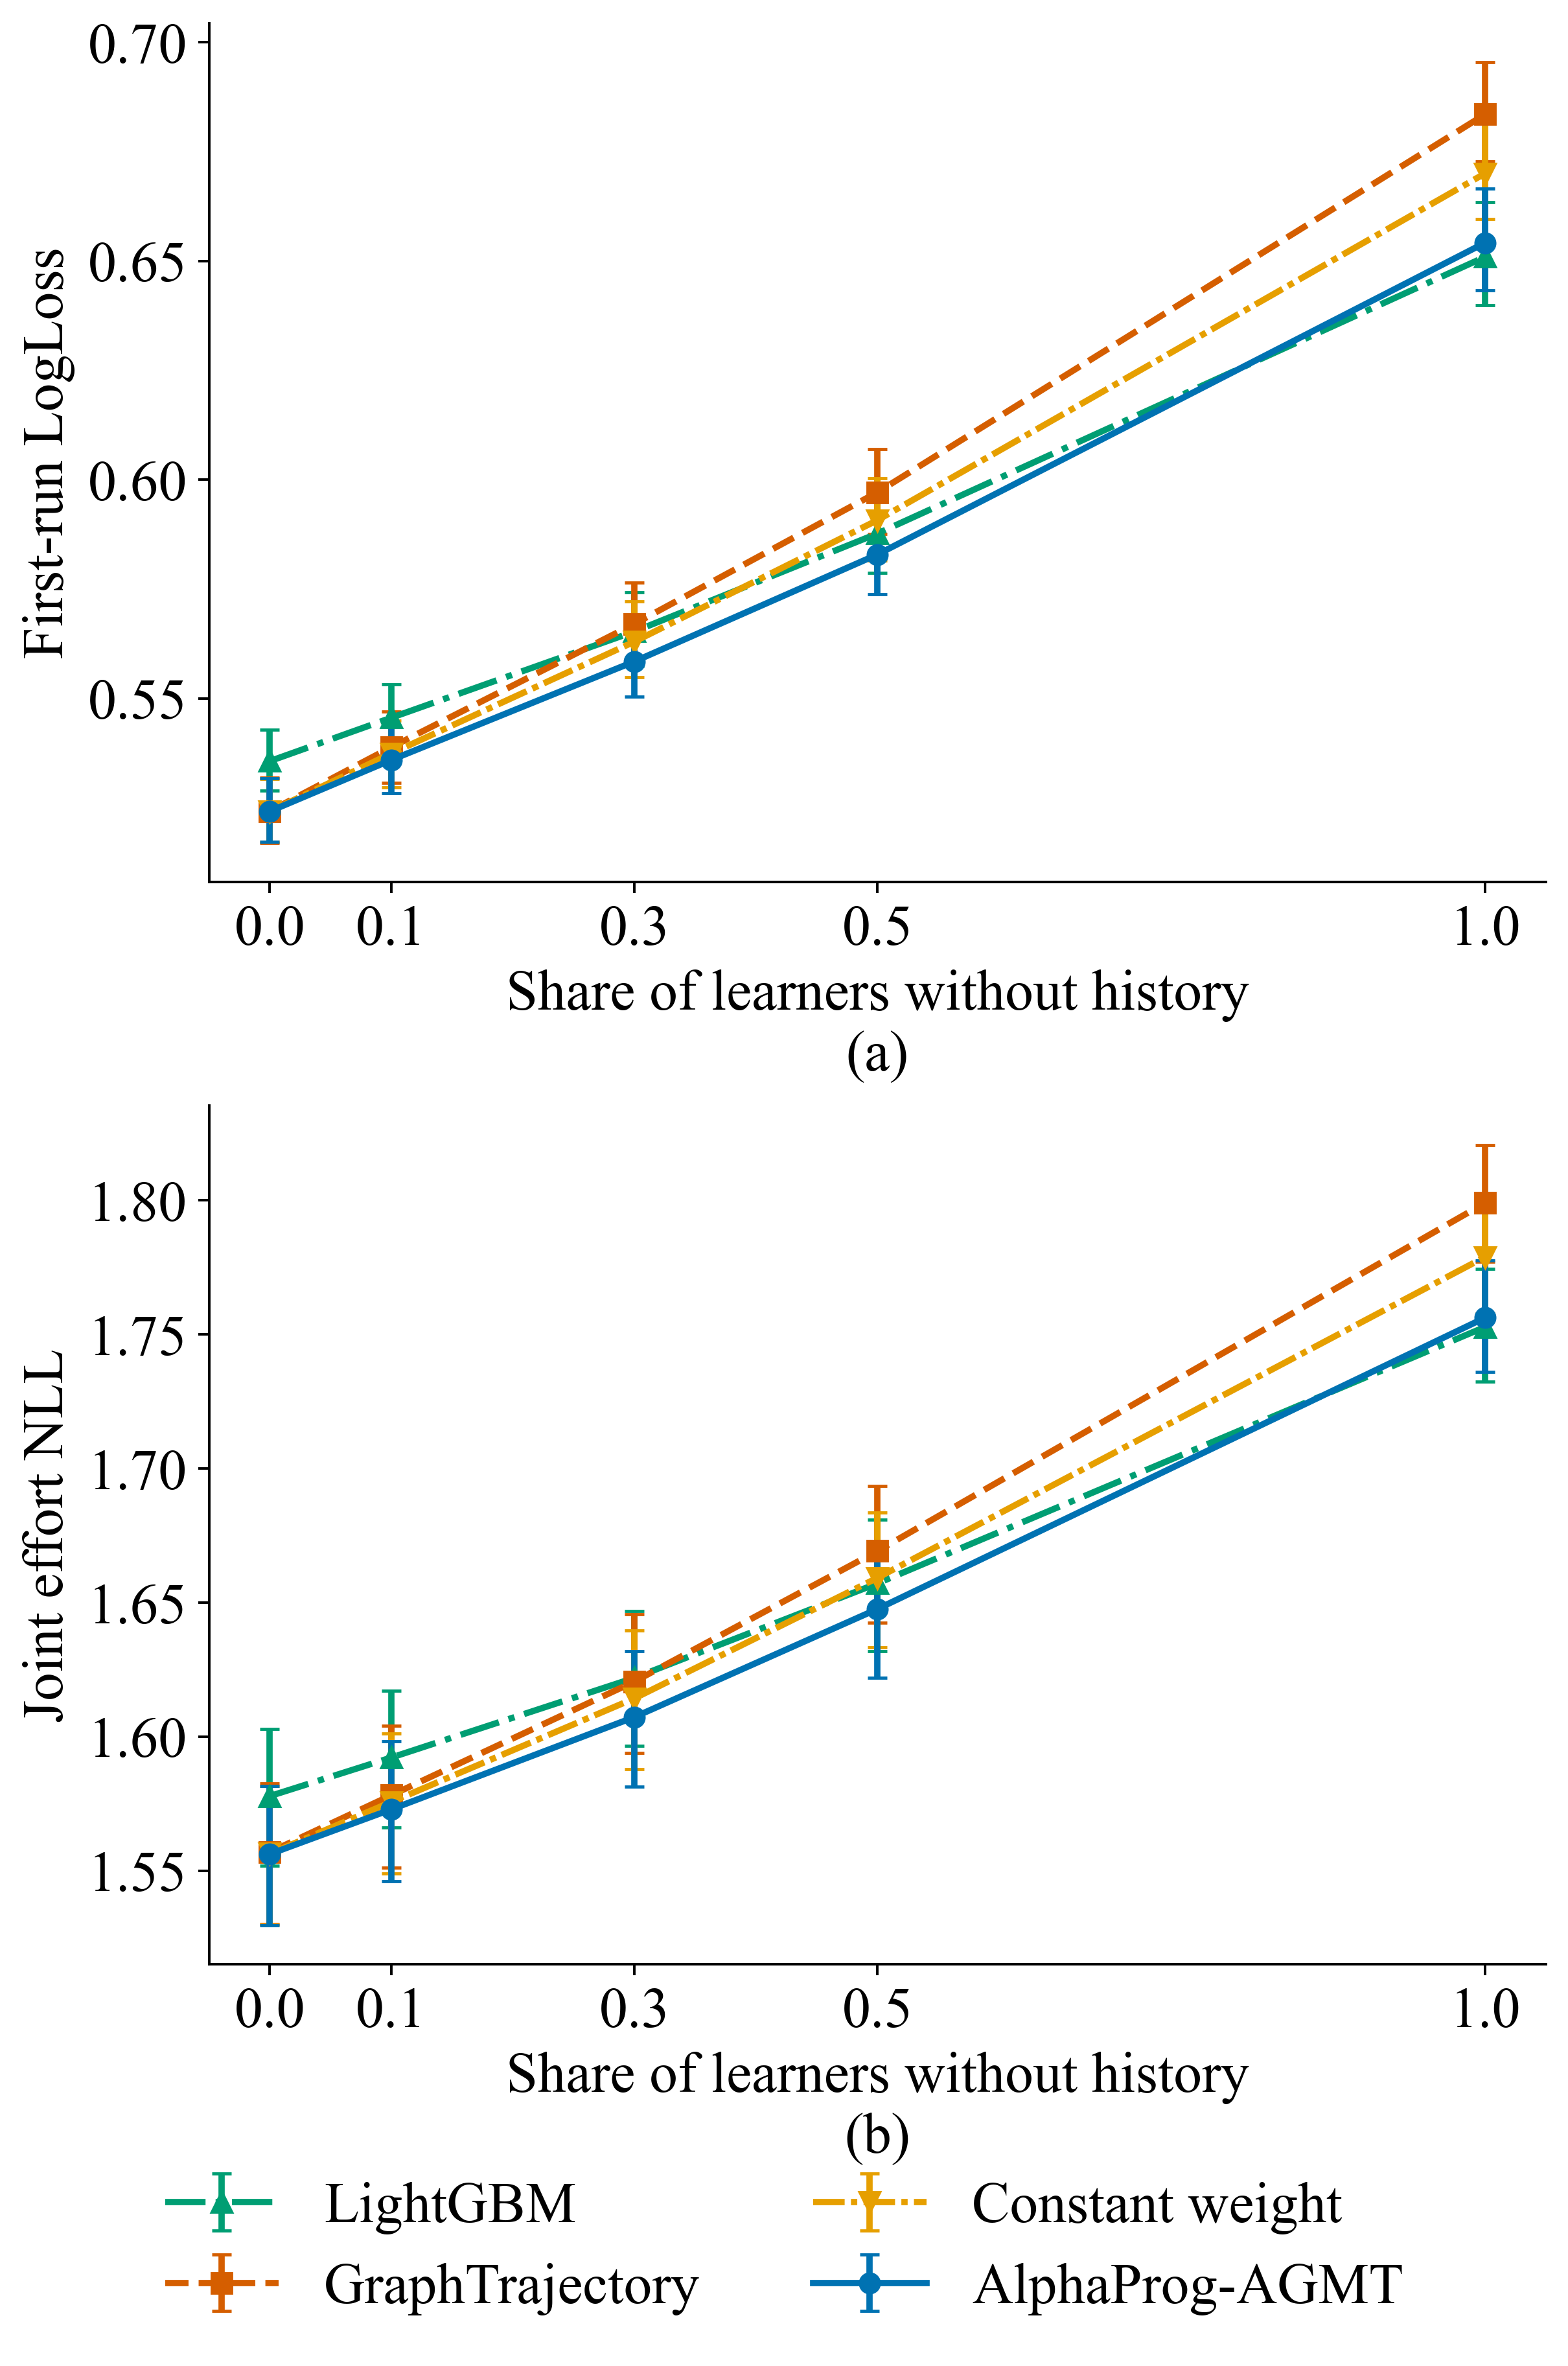

In [36]:
fig, axes = plt.subplots(2, 1, figsize=(6.8, 10.4), layout="constrained")
for ax, (metric, low, high, ylabel), letter in zip(
    axes,
    [
        ("LogLoss", "CI_low", "CI_high", "First-run LogLoss"),
        ("Effort_NLL", "Effort_CI_low", "Effort_CI_high", "Joint effort NLL"),
    ],
    ["a", "b"],
):
    for name in ["LightGBM", "GraphTrajectory", "Constant weight", "AlphaProg-AGMT"]:
        rows = masking[masking.Model.eq(name)]
        ax.errorbar(
            rows.Mask_fraction,
            rows[metric],
            yerr=[rows[metric] - rows[low], rows[high] - rows[metric]],
            color=PALETTE[name],
            linestyle=LINESTYLES[name],
            marker=MARKERS[name],
            linewidth=2,
            capsize=3,
            label=name,
        )
    ax.set_ylabel(ylabel)
    ax.set_xticks(mask_fractions)
    panel_label(ax, letter, "Share of learners without history")
    ax.spines[["top", "right"]].set_visible(False)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
save_figure(fig, "07_history_masking")
plt.show()

**Interpretation.** Under history removal the standalone expert degrades fastest: at a full cold start its LogLoss is 0.684 versus 0.651 for LightGBM. The adaptive gate shifts weight to the tabular model, so AlphaProg-AGMT is better than the expert at every removal share (0.0029, 0.0086, 0.0142 and 0.0294 in LogLoss at 10, 30, 50 and 100%) and better than the constant weight (0.0015–0.0159). At 10–50% removal the hybrid is also better than LightGBM (0.0097, 0.0069 and 0.0048); only at a full cold start is LightGBM slightly more accurate (0.0032 [0.0029, 0.0036]). In every regime the hybrid is close to the better component, whereas each single component loses in one of the regimes. This is the function of the reliability gate: on the complete test it neither helps nor harms, and it prevents the degradation of the expert when history is missing.

### Ablations on three seeds

Six architectural variants of the expert (NoGraphEncoder, NoOrder, NoAuxLoss, NoEdges, NoInteraction, NoTaskReadout) are retrained for seeds 42 and 2026 with the same frozen code (out-of-fold predictions for the gate and training on the full train set); the seed 17 predictions are taken from notebooks 05–06. For each variant and seed the gate is fitted by the same rules as in notebook 05. NoInteraction removes the embedding of prior tasks with their observed outcomes, NoTaskReadout leaves only the shared output layers, and NoAuxLoss uses the common hazard companion. The constant weight and the best single component are taken from the previous section. The comparison is performed for three-seed ensembles; the Holm correction is applied separately to the eight comparisons on LogLoss and the eight on Effort NLL.

In [37]:
ABLATIONS = list(frozen["ablation_variants"])
evaluation_frame = pd.concat([validation_data, test_data], ignore_index=True)
evaluation_history = join_history(graph_history["validation"], graph_history["test"])
n_validation = len(validation_data)


def train_variant(variant: str, seed: int) -> dict:
    """Cross-fit and full-train fit of one frozen expert variant."""
    configuration = ns05["VARIANT_CONFIGS"].get(variant, ns05["FULL_CONFIG"])
    oof = ns05["graph_cross_fit"](configuration, seed, variant)
    full = ns05["fit_graph_expert"](
        np.arange(len(train_data)),
        evaluation_frame,
        evaluation_history,
        configuration,
        seed,
        variant,
        "Full train",
    )
    return {
        "oof": oof,
        "validation": full[:n_validation],
        "test": full[n_validation:],
        "config": vars(configuration),
    }


progress = Progress("Three-seed ablations")
ablation_components = {}
for variant in ABLATIONS:
    for seed in SEEDS[1:]:
        progress.update(f"{variant}, seed {seed}")
        ablation_components[(variant, seed)] = cached(
            f"ablation_{variant}_{seed}", lambda: train_variant(variant, seed)
        )
progress.close()

In [38]:
from sklearn.metrics import brier_score_loss

ablation_forecasts = {name: {"validation": [], "test": []} for name in ["AlphaProg-AGMT", *ABLATIONS, "ConstantFusion", "BestSingle: GraphTrajectory"]}
for seed in SEEDS:
    inputs = gate_inputs[seed]
    ablation_forecasts["AlphaProg-AGMT"]["validation"].append(
        experiments["gates"][("AlphaProg-AGMT", seed)]["validation_probability"]
    )
    ablation_forecasts["AlphaProg-AGMT"]["test"].append(
        components["joint_by_seed"][("AlphaProg-AGMT", seed)]
    )
    for variant in ABLATIONS:
        if seed == SEEDS[0]:
            ablation_forecasts[variant]["validation"].append(
                experiments["gates"][(variant, seed)]["validation_probability"]
            )
            ablation_forecasts[variant]["test"].append(test_ablation_forecasts[variant])
            continue
        ns05["component_results"][(variant, seed)] = {
            "oof": ablation_components[(variant, seed)]["oof"],
            "validation": ablation_components[(variant, seed)]["validation"],
        }
        fitted = ns05["fit_fixed_gate"](variant, seed, FROZEN_GATE)
        graph_test = ablation_components[(variant, seed)]["test"].copy()
        if variant == "NoAuxLoss":
            graph_test[:, 1] = inputs["base_test"][:, 1]
        ablation_forecasts[variant]["validation"].append(fitted["validation_probability"])
        ablation_forecasts[variant]["test"].append(
            ns06["apply_fitted_gate"](test_data, inputs["base_test"], graph_test, fitted)[0]
        )
    ablation_forecasts["ConstantFusion"]["validation"].append(
        constant_gates[seed]["validation_probability"]
    )
    ablation_forecasts["ConstantFusion"]["test"].append(
        variant_forecasts["Constant weight"]["test"][SEEDS.index(seed)]
    )
    ablation_forecasts["BestSingle: GraphTrajectory"]["validation"].append(inputs["graph_valid"])
    ablation_forecasts["BestSingle: GraphTrajectory"]["test"].append(inputs["graph_test"])
assert np.allclose(
    ablation_forecasts["ConstantFusion"]["test"][0], test_ablation_forecasts["ConstantFusion"], atol=1e-6
)

ablation_rows, ablation_seed_rows, ablation_effect_rows = [], [], []
ablation_losses = {}
for name, forecasts in ablation_forecasts.items():
    valid_losses = joint_losses(validation_data, seed_average(forecasts["validation"]))
    ablation_losses[name] = joint_losses(test_data, seed_average(forecasts["test"]))
    ablation_rows.append(
        {
            "Variant": name,
            "Seeds": len(forecasts["test"]),
            "Validation_LogLoss": valid_losses["LogLoss"].mean(),
            "Test_LogLoss": ablation_losses[name]["LogLoss"].mean(),
            "Test_Brier": brier_score_loss(test_data.y, seed_average(forecasts["test"])[:, 0]),
            "Test_Effort_NLL": ablation_losses[name]["Effort NLL"].mean(),
        }
    )
    for seed, forecast in zip(SEEDS, forecasts["test"]):
        losses = joint_losses(test_data, forecast)
        ablation_seed_rows.append(
            {
                "Variant": name,
                "Seed": seed,
                "Test_LogLoss": losses["LogLoss"].mean(),
                "Test_Effort_NLL": losses["Effort NLL"].mean(),
            }
        )
for metric in ["LogLoss", "Effort NLL"]:
    rows = []
    for name in list(ablation_forecasts)[1:]:
        rows.append(
            {
                "Variant": name,
                "Metric": metric,
                **cluster_effect(
                    STUDENTS, ablation_losses[name][metric], ablation_losses["AlphaProg-AGMT"][metric]
                ),
            }
        )
    rows = pd.DataFrame(rows)
    rows["p_Holm"] = holm_adjust(rows.p_raw.to_numpy())
    ablation_effect_rows.append(rows)
ablation_effects = pd.concat(ablation_effect_rows, ignore_index=True)
seed_wide = (
    pd.DataFrame(ablation_seed_rows)
    .pivot(index="Variant", columns="Seed", values=["Test_LogLoss", "Test_Effort_NLL"])
    .loc[list(ablation_forecasts)]
)
seed_wide.columns = [f"{metric}_seed_{seed}" for metric, seed in seed_wide.columns]
table(
    pd.DataFrame(ablation_rows),
    "Ablations: three-seed ensembles on validation and the locked test ↓",
    "07_ablations_three_seeds",
)
table(
    seed_wide.reset_index(),
    "Ablations by individual seed: LogLoss and Effort NLL on the locked test ↓",
    "07_ablations_by_seed",
)
table(
    ablation_effects,
    f"Variant loss − AlphaProg-AGMT loss (> 0: the removed component is useful); 95% CI over learners; Holm over {len(ablation_forecasts) - 1} comparisons for each metric",
    "07_ablation_effects",
)

Ablations: three-seed ensembles on validation and the locked test ↓

,Variant,Seeds,Validation_LogLoss,Test_LogLoss,Test_Brier,Test_Effort_NLL
0,AlphaProg-AGMT,3,0.51837,0.52416,0.17636,1.55618
1,NoGraphEncoder,3,0.52013,0.52548,0.17676,1.55890
2,NoOrder,3,0.52399,0.52870,0.17808,1.56448
3,NoAuxLoss,3,0.51913,0.52477,0.17654,1.56693
4,NoEdges,3,0.52013,0.52552,0.17681,1.55871
5,NoInteraction,3,0.51962,0.52551,0.17695,1.55767
6,NoTaskReadout,3,0.52021,0.52547,0.17681,1.55951
7,ConstantFusion,3,0.51864,0.52415,0.17628,1.55631
8,BestSingle: GraphTrajectory,3,0.51885,0.52420,0.17635,1.55691


Ablations by individual seed: LogLoss and Effort NLL on the locked test ↓

,Variant,Test_LogLoss_seed_17,Test_LogLoss_seed_42,Test_LogLoss_seed_2026,Test_Effort_NLL_seed_17,Test_Effort_NLL_seed_42,Test_Effort_NLL_seed_2026
0,AlphaProg-AGMT,0.52528,0.52599,0.52505,1.55888,1.56088,1.55806
1,NoGraphEncoder,0.52735,0.52659,0.52602,1.56228,1.56192,1.56054
2,NoOrder,0.52956,0.53006,0.52883,1.56615,1.56846,1.56532
3,NoAuxLoss,0.52634,0.52607,0.52554,1.56870,1.56864,1.56826
4,NoEdges,0.52650,0.52700,0.52636,1.56111,1.56294,1.56054
5,NoInteraction,0.52714,0.52641,0.52647,1.56112,1.56101,1.55896
6,NoTaskReadout,0.52644,0.52703,0.52641,1.56283,1.56204,1.56133
7,ConstantFusion,0.52521,0.52590,0.52492,1.55909,1.56069,1.55779
8,BestSingle: GraphTrajectory,0.52602,0.52802,0.52618,1.56174,1.56583,1.56088


Variant loss − AlphaProg-AGMT loss (> 0: the removed component is useful); 95% CI over learners; Holm over 8 comparisons for each metric

,Variant,Metric,Effect,CI_low,CI_high,p_raw,p_Holm
0,NoGraphEncoder,LogLoss,0.00132,0.00049,0.00213,0.00400,0.01599
1,NoOrder,LogLoss,0.00454,0.00341,0.00569,0.00050,0.00400
2,NoAuxLoss,LogLoss,0.00060,0.00007,0.00119,0.03998,0.11994
3,NoEdges,LogLoss,0.00136,0.00077,0.00193,0.00050,0.00400
4,NoInteraction,LogLoss,0.00135,0.00071,0.00200,0.00100,0.00600
5,NoTaskReadout,LogLoss,0.00130,0.00060,0.00196,0.00100,0.00600
6,ConstantFusion,LogLoss,-0.00002,-0.00028,0.00025,0.89955,1.00000
7,BestSingle: GraphTrajectory,LogLoss,0.00004,-0.00070,0.00086,0.93853,1.00000
8,NoGraphEncoder,Effort NLL,0.00272,0.00132,0.00402,0.00100,0.00400
9,NoOrder,Effort NLL,0.00830,0.00654,0.01012,0.00050,0.00400


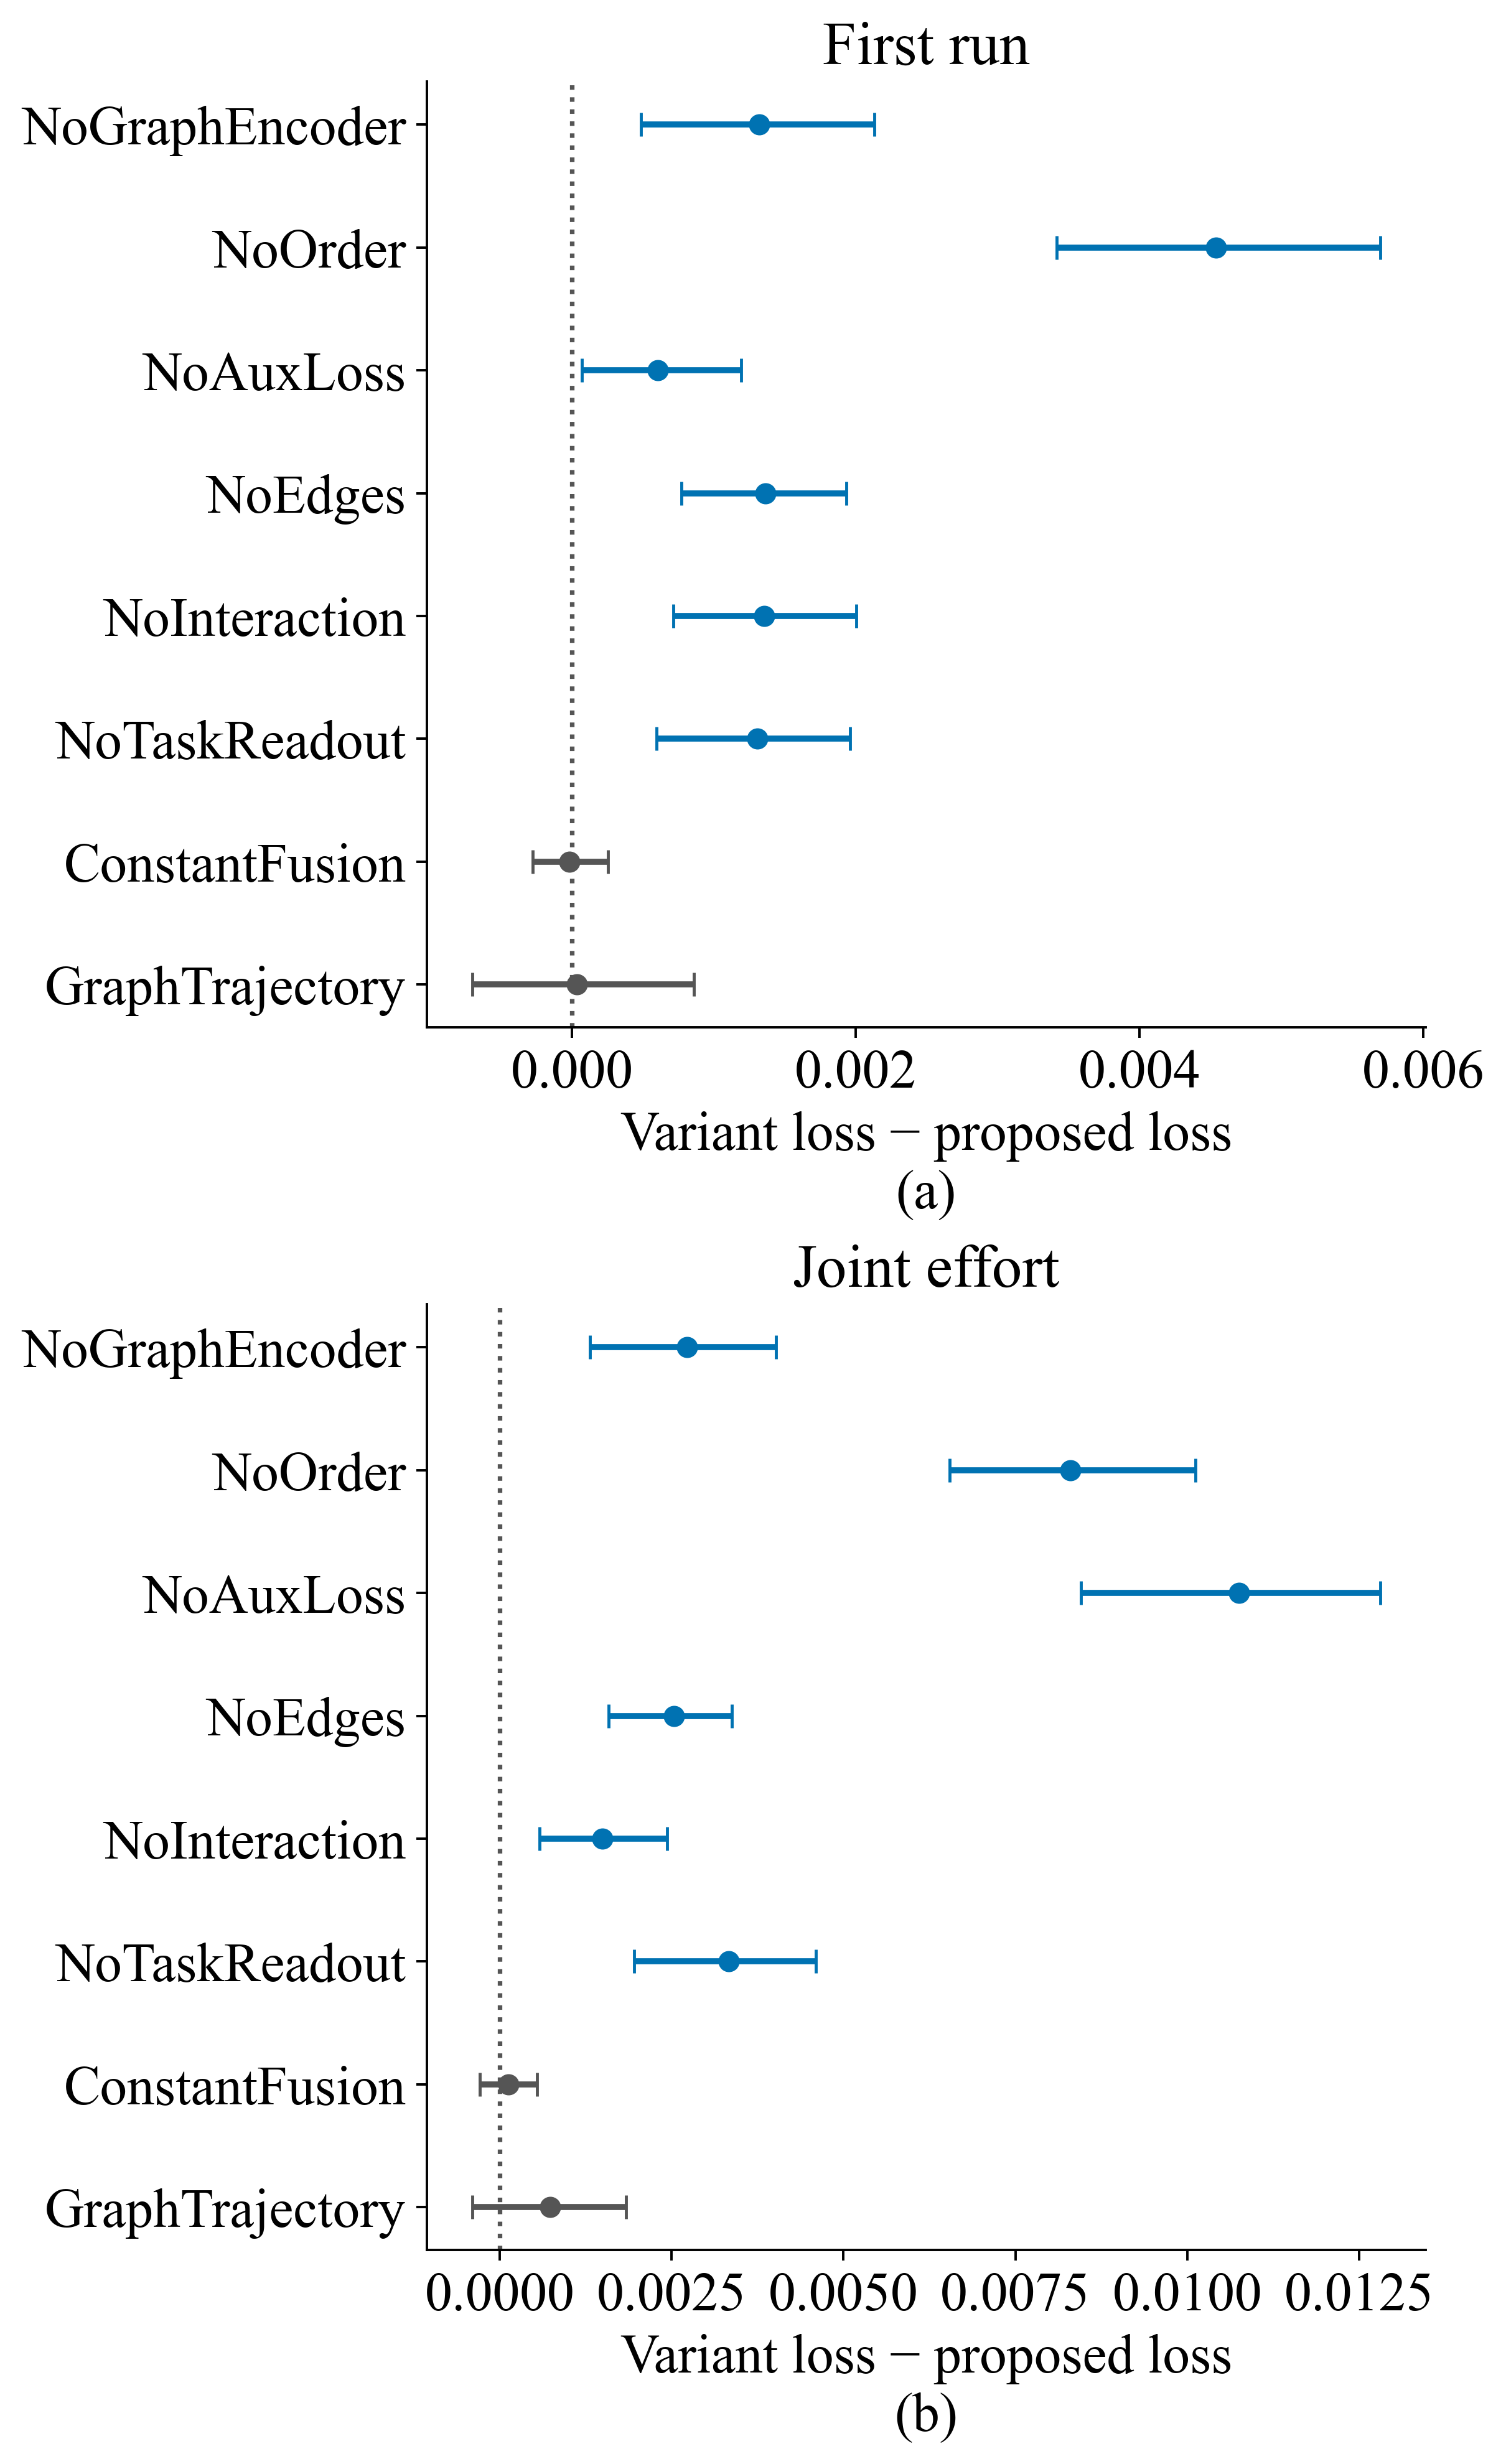

In [39]:
fig, axes = plt.subplots(2, 1, figsize=(6.8, 11.2), layout="constrained")
names = list(ablation_forecasts)[1:]
for ax, metric, title, letter in zip(
    axes, ["LogLoss", "Effort NLL"], ["First run", "Joint effort"], ["a", "b"]
):
    rows = ablation_effects[ablation_effects.Metric.eq(metric)].set_index("Variant").loc[names]
    positions = np.arange(len(names))
    colors = ["#0072B2" if low > 0 else ("#D55E00" if high < 0 else "#555555") for low, high in zip(rows.CI_low, rows.CI_high)]
    for position, (effect, low, high), color in zip(positions, rows[["Effect", "CI_low", "CI_high"]].to_numpy(), colors):
        ax.errorbar(effect, position, xerr=[[effect - low], [high - effect]], fmt="o", color=color, capsize=4, linewidth=2)
    ax.axvline(0, color="#555555", linestyle=":")
    ax.set_yticks(positions, [name.replace("BestSingle: ", "") for name in names])
    ax.invert_yaxis()
    ax.set_title(title)
    panel_label(ax, letter, "Variant loss − proposed loss")
    ax.spines[["top", "right"]].set_visible(False)
save_figure(fig, "07_ablation_effects")
plt.show()

**Interpretation.** In three-seed ensembles every removal from the expert worsens the forecast. The largest loss follows the removal of the attempt order (LogLoss 0.00454 [0.00341, 0.00569]); removing the graph edges, the interaction embedding, the graph encoder or the task read-out costs 0.00136 [0.00077, 0.00193], 0.00135 [0.00071, 0.00200], 0.00132 [0.00049, 0.00213] and 0.00130 [0.00060, 0.00196] (p_Holm between 0.004 and 0.016). Without the auxiliary loss the first-run change is small (0.00060 [0.00007, 0.00119], p_Holm = 0.12), but Effort NLL rises by 0.01075 [0.00845, 0.01280], the largest effect on the secondary target. All six removals raise Effort NLL (0.00149–0.01075; p_Holm ≤ 0.015). A constant weight instead of the adaptive gate does not differ on the complete test (−0.00002 [−0.00028, 0.00025]), and the standalone expert does not differ from the hybrid (LogLoss 0.00004 [−0.00070, 0.00086]; Effort NLL 0.00073 [−0.00039, 0.00184]). The advantage of the model therefore rests on the expert: the ordered history, the program-graph encoder with its edges, the interaction embedding, the task read-out and the joint training on effort. Each of these effects is several times smaller than the 0.005 threshold used for the comparison with other models, so the ablations establish direction and significance, not a large individual contribution.

### Auxiliary-loss weight and history window

The expert is trained on the full train set with four auxiliary-loss weights (0.03, 0.1, 0.3 and 1.0) and with history windows of 8, 16 and 32 prior attempts; the remaining settings are frozen. The expert's own predictions $(p, h)$ are evaluated without the gate in order to observe the effect of the setting on both outputs directly. The weight 1.0 and the window 32 correspond to the frozen model and are taken from notebooks 05–06.

In [40]:
def window_history(history: dict, window: int) -> dict:
    """Keep only the most recent `window` prior attempts in left-aligned arrays."""
    result = {key: np.zeros_like(value) if key != "process" else np.full_like(value, np.nan) for key, value in history.items()}
    for row, length in enumerate(history["length"]):
        kept = min(int(length), window)
        start = int(length) - kept
        for key in history:
            if key != "length":
                result[key][row, :kept] = history[key][row, start:length]
        result["length"][row] = kept
    return result


def train_expert(configuration, seed: int, window: int = 32) -> dict:
    """Full-train fit of the expert with one changed setting."""
    train_history = graph_history["train"] if window == 32 else window_history(graph_history["train"], window)
    evaluation = evaluation_history if window == 32 else window_history(evaluation_history, window)
    with rebound(ns05, history_train=train_history):
        full = ns05["fit_graph_expert"](
            np.arange(len(train_data)), evaluation_frame, evaluation, configuration, seed, "Sensitivity", "Full train"
        )
    return {"validation": full[:n_validation], "test": full[n_validation:]}


AUXILIARY_GRID = post_hoc["experiments"]["auxiliary_weight_sensitivity"]["values"]
sensitivity_settings = [
    ("Auxiliary weight", weight, 32) for weight in AUXILIARY_GRID if weight != AUXILIARY_WEIGHT
]
sensitivity_settings += [("History window", AUXILIARY_WEIGHT, window) for window in [8, 16]]
progress = Progress("Expert sensitivity")
sensitivity_forecasts = {}
for setting, weight, window in sensitivity_settings:
    for seed in SEEDS:
        progress.update(f"{setting}: weight {weight}, window {window}, seed {seed}")
        configuration = ns05["replace"](ns05["FULL_CONFIG"], auxiliary_weight=weight)
        sensitivity_forecasts[(weight, window, seed)] = cached(
            f"expert_weight{weight}_window{window}_{seed}",
            lambda: train_expert(configuration, seed, window),
        )
progress.close()
for seed in SEEDS:
    sensitivity_forecasts[(AUXILIARY_WEIGHT, 32, seed)] = {
        "validation": experiments["components"][("FullGraph", seed)]["validation"],
        "test": components["graph_by_seed"][seed],
    }
sensitivity_rows = []
for weight, window in [(weight, 32) for weight in AUXILIARY_GRID] + [
    (AUXILIARY_WEIGHT, 8),
    (AUXILIARY_WEIGHT, 16),
]:
    valid = joint_losses(validation_data, seed_average([sensitivity_forecasts[(weight, window, s)]["validation"] for s in SEEDS]))
    test = joint_losses(test_data, seed_average([sensitivity_forecasts[(weight, window, s)]["test"] for s in SEEDS]))
    sensitivity_rows.append(
        {
            "Auxiliary_weight": weight,
            "History_window": window,
            "Frozen_setting": (weight, window) == (AUXILIARY_WEIGHT, 32),
            "Validation_LogLoss": valid["LogLoss"].mean(),
            "Validation_Effort_NLL": valid["Effort NLL"].mean(),
            "Test_LogLoss": test["LogLoss"].mean(),
            "Test_Tail_NLL": test["Tail NLL"].mean(),
            "Test_Effort_NLL": test["Effort NLL"].mean(),
        }
    )
sensitivity = pd.DataFrame(sensitivity_rows)
table(
    sensitivity,
    "GraphTrajectory expert under different auxiliary-loss weights and history windows: three-seed ensembles ↓",
    "07_expert_sensitivity",
)

GraphTrajectory expert under different auxiliary-loss weights and history windows: three-seed ensembles ↓

,Auxiliary_weight,History_window,Frozen_setting,Validation_LogLoss,Validation_Effort_NLL,Test_LogLoss,Test_Tail_NLL,Test_Effort_NLL
0,0.03,32,False,0.52029,1.57254,0.52503,1.03661,1.56164
1,0.10,32,False,0.52003,1.57124,0.52517,1.03546,1.56063
2,0.30,32,False,0.51946,1.56927,0.52469,1.03511,1.55980
3,1.00,32,True,0.51885,1.56786,0.52420,1.03271,1.55691
4,1.00,8,False,0.51907,1.56866,0.52469,1.03258,1.55726
5,1.00,16,False,0.51888,1.56802,0.52428,1.03275,1.55703


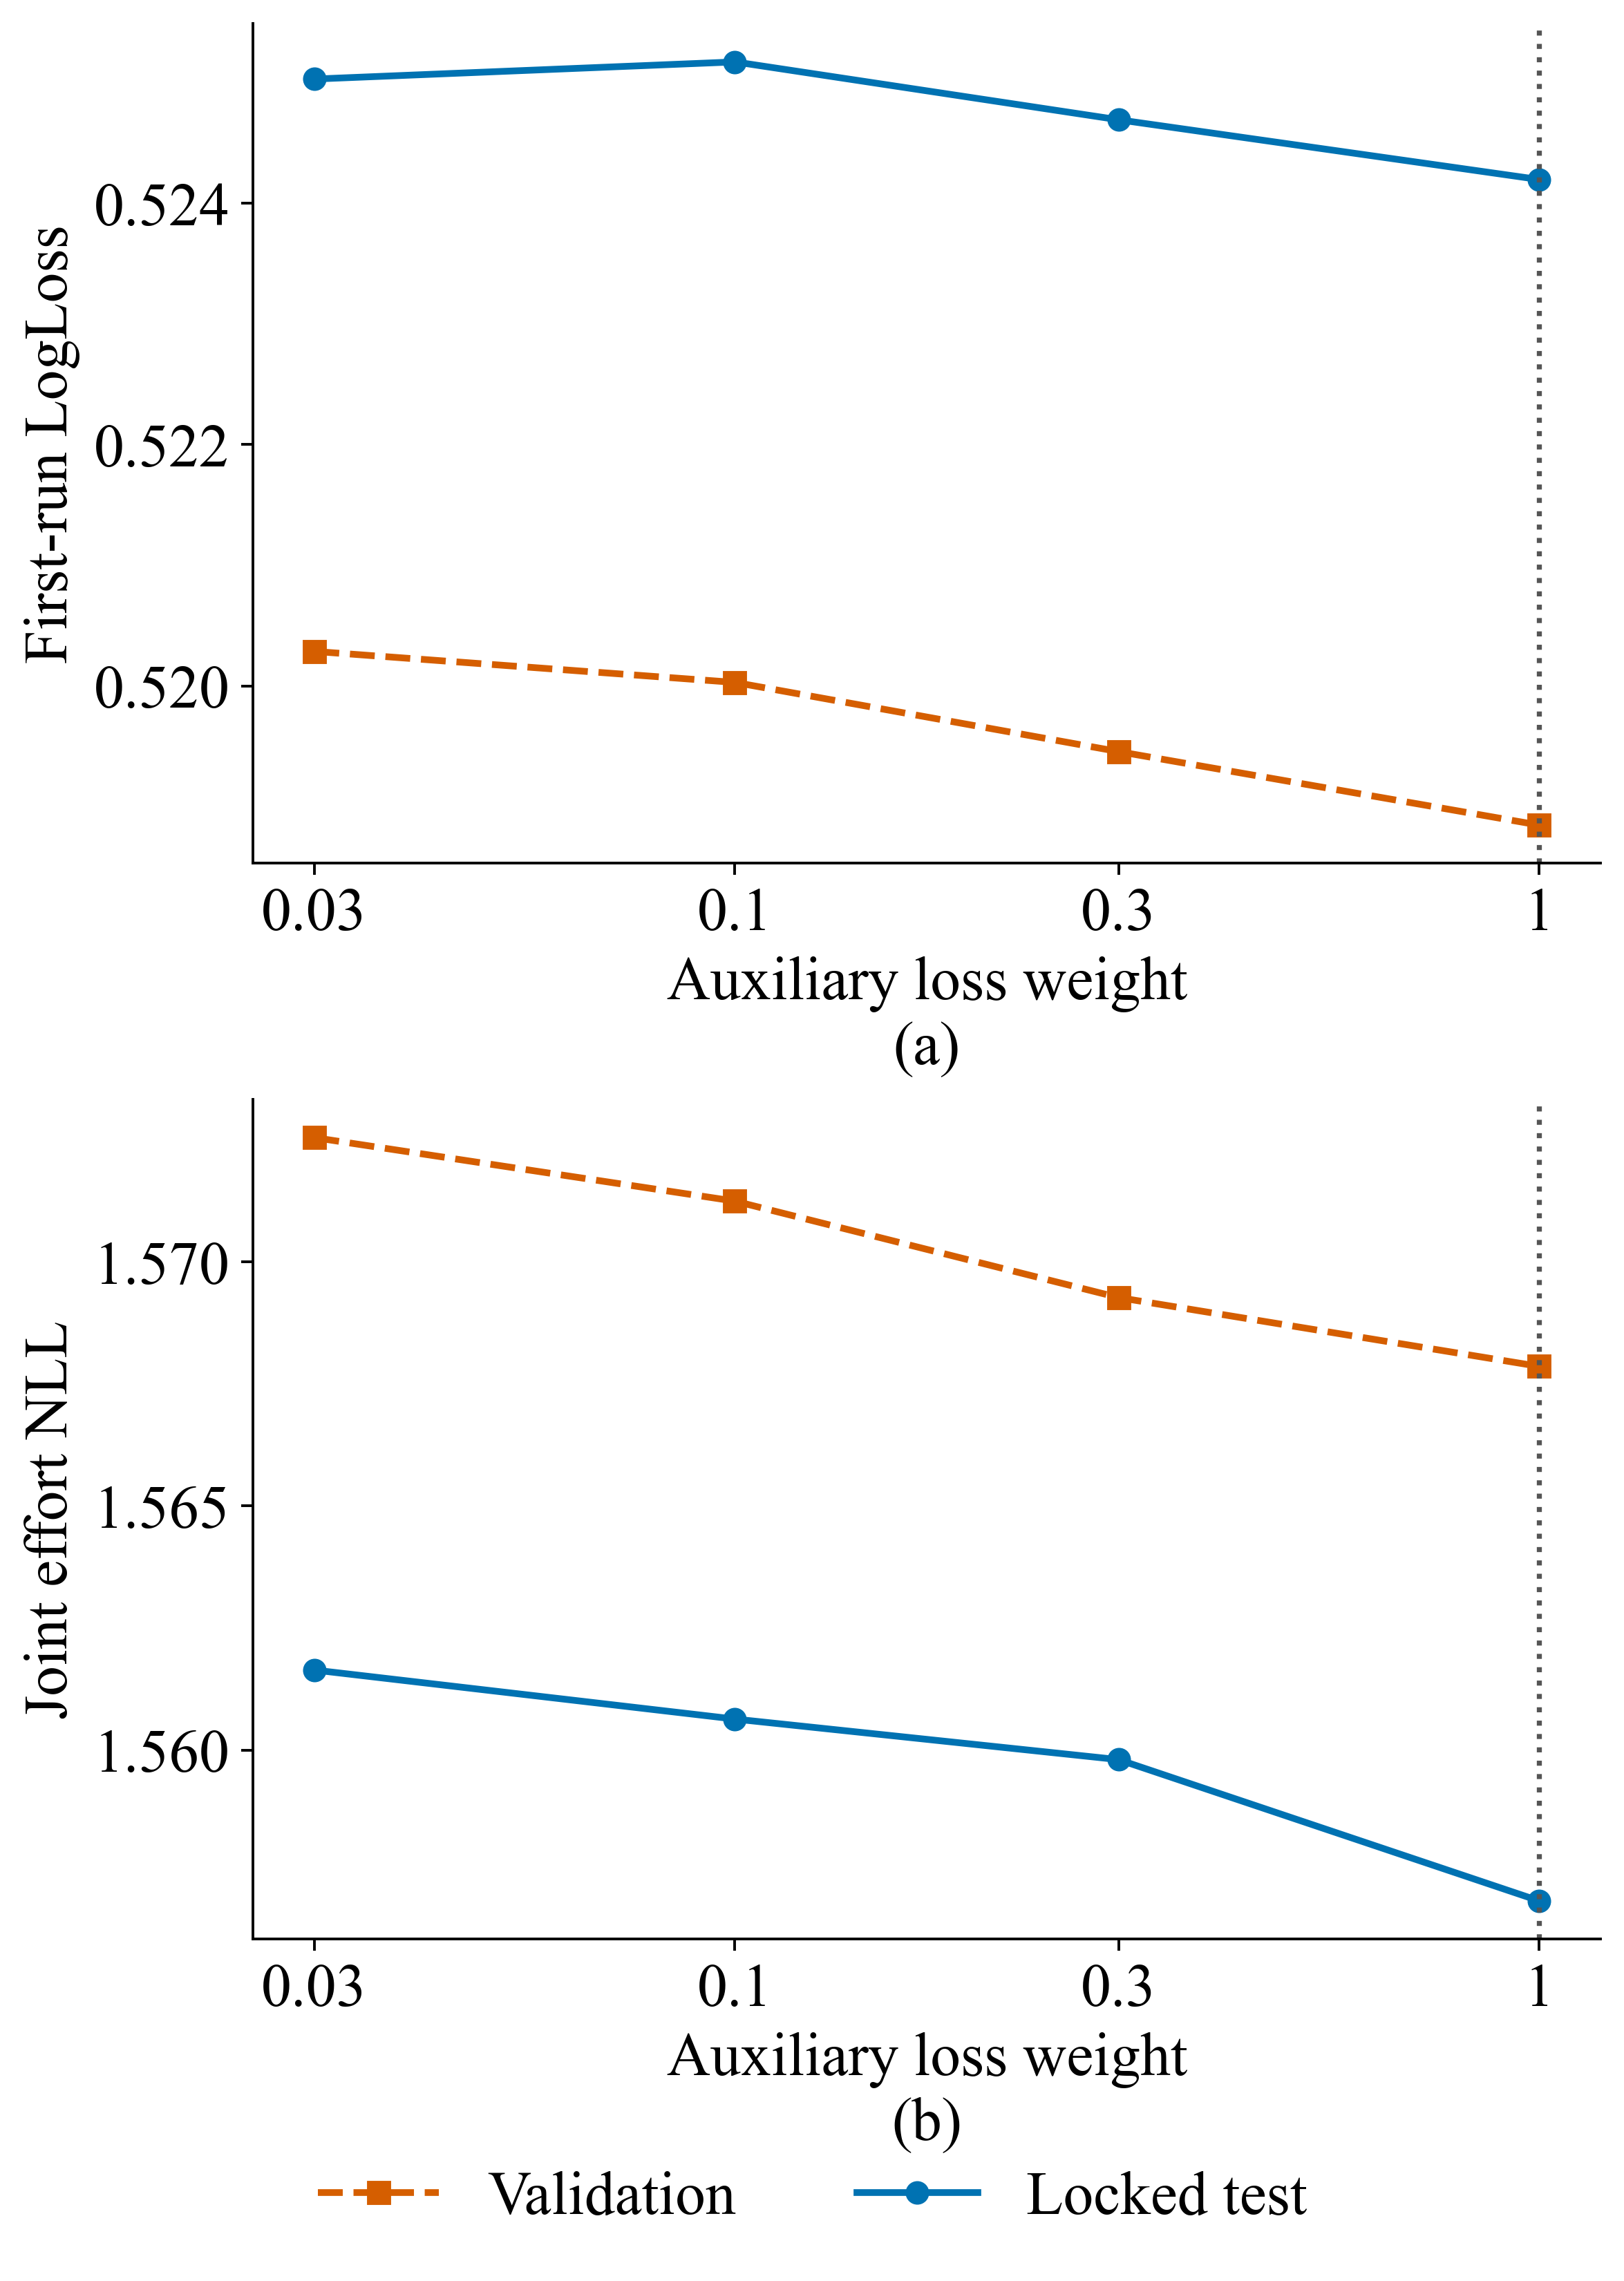

In [41]:
weights = sensitivity[sensitivity.History_window.eq(32)].sort_values("Auxiliary_weight")
fig, axes = plt.subplots(2, 1, figsize=(6.6, 9.4), layout="constrained")
for ax, (valid_col, test_col, ylabel), letter in zip(
    axes,
    [("Validation_LogLoss", "Test_LogLoss", "First-run LogLoss"), ("Validation_Effort_NLL", "Test_Effort_NLL", "Joint effort NLL")],
    ["a", "b"],
):
    ax.plot(weights.Auxiliary_weight, weights[valid_col], marker="s", linestyle="--", color="#D55E00", linewidth=2, label="Validation")
    ax.plot(weights.Auxiliary_weight, weights[test_col], marker="o", linestyle="-", color="#0072B2", linewidth=2, label="Locked test")
    ax.axvline(AUXILIARY_WEIGHT, color="#555555", linestyle=":")
    ax.set_xscale("log")
    ax.set_xticks([0.03, 0.1, 0.3, 1.0], ["0.03", "0.1", "0.3", "1"])
    ax.minorticks_off()
    ax.set_ylabel(ylabel)
    panel_label(ax, letter, "Auxiliary loss weight")
    ax.spines[["top", "right"]].set_visible(False)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
save_figure(fig, "07_auxiliary_weight")
plt.show()

**Interpretation.** On validation both outputs of the expert improve monotonically with the auxiliary weight (LogLoss 0.52029 → 0.51885; Effort NLL 1.57254 → 1.56786), in agreement with the selection of λ = 1 in notebook 05. On the test, Effort NLL follows the same order (1.56164, 1.56063, 1.55980 and 1.55691 at weights 0.03, 0.1, 0.3 and 1), and the first-run LogLoss is lowest at λ = 1 (0.52503, 0.52517, 0.52469 and 0.52420), although the three smaller weights differ by less than 0.0005. Training on effort therefore does not harm the first-run forecast and improves the secondary one. The history window has a small effect: 8, 16 and 32 attempts give LogLoss 0.52469, 0.52428 and 0.52420 and Effort NLL 1.55726, 1.55703 and 1.55691, so the truncation of history for 4.6% of queries does not limit quality. Weights above 1 were not examined.

### Next school year and unseen tasks

The primary protocol evaluates new learners on known tasks within a shared calendar period. Two additional schemes use the same features and frozen hyperparameters but shift the generalisation boundary:

* **Next school year.** Training: queries of train learners started before 1 September 2019; evaluation: queries of locked-test learners started on or after 1 September 2019. The model sees neither these learners nor this period.
* **Unseen tasks.** The 85 tasks are divided into three groups stratified by section. For each group, the models are trained on queries of train learners on the remaining tasks and evaluated on queries of test learners on the tasks of that group; the predictions of the three groups are pooled. The identifier of an unseen task is replaced with a reserved “unknown” index, and the task description is retained. Programs of unseen tasks may occur in the learner's own history.

The gate is refitted on the out-of-fold predictions of the new training set with the frozen L2 and prior. In the unseen-task scheme every evaluation task is new, so the coefficient vector for new tasks is applied; it is fitted on forecasts for which both the learner fold and the task fold were withheld inside the training partition of the scheme. AKT and UKT are not included; knowledge tracing on ordered interactions is represented in these schemes by DKT.

In [42]:
baseline_settings = json.loads((ROOT / "Protocol/baseline_configurations.json").read_text())
selected_rates = joblib.load(ROOT / "Results/04_selection.joblib")["selected"]
TABULAR = ["LogisticRegression", "RandomForest", "XGBoost", "LightGBM"]
NEURAL = ["TabM", "DKT"]
SPLIT_MODELS = ["GlobalMean", "ItemMean", *TABULAR, *NEURAL, "GraphTrajectory", "AlphaProg-AGMT"]


def tabular_predict(name, seed, fit_frame, eval_frame):
    """Frozen notebook-03 preprocessing and estimator with the selected setting."""
    preprocessing = ns03["make_preprocessor"]()
    fit_matrix = ns03["transformed_frame"](preprocessing.fit_transform(fit_frame[ns03["feature_names"]]))
    eval_matrix = ns03["transformed_frame"](preprocessing.transform(eval_frame[ns03["feature_names"]]))
    estimator = ns03["make_estimator"](name, baseline_settings[name], seed)
    estimator.fit(fit_matrix, fit_frame.y.to_numpy())
    return np.clip(estimator.predict_proba(eval_matrix)[:, 1], 1e-6, 1 - 1e-6)


def tabular_oof(name, seed, fit_frame):
    result = np.full(len(fit_frame), np.nan)
    for fold in sorted(fit_frame.fold.unique()):
        held = fit_frame.fold.eq(fold).to_numpy()
        result[held] = tabular_predict(name, seed, fit_frame[~held], fit_frame[held])
    return result


def frequency_baselines(fit_frame, eval_frame):
    prior = float(fit_frame.y.mean())
    grouped = fit_frame.groupby("problem").y.agg(["sum", "count"])
    rates = (grouped["sum"] + 20.0 * prior) / (grouped["count"] + 20.0)
    return {
        "GlobalMean": np.full(len(eval_frame), prior),
        "ItemMean": eval_frame.problem.map(rates).fillna(prior).to_numpy(),
    }


def split_experiment(seed, fit_frame, fit_history, fit_sequence, eval_frame, eval_history, eval_sequence, task_map=None):
    """Train every split comparator and the frozen hybrid recipe on one partition."""
    fit_frame = fit_frame.reset_index(drop=True)
    eval_frame = eval_frame.reset_index(drop=True)
    forecasts = {}
    for name in TABULAR:
        forecasts[name] = tabular_predict(name, seed, fit_frame, eval_frame)
    lightgbm_oof = tabular_oof("LightGBM", seed, fit_frame)
    for name in NEURAL:
        with rebound(ns04, train_data=fit_frame, sequence_train=fit_sequence):
            forecasts[name] = ns04["fit_one"](
                name, np.arange(len(fit_frame)), eval_frame, eval_sequence, selected_rates[name], seed, "Split experiment"
            )
    overrides = {"train_data": fit_frame, "history_train": fit_history}
    if task_map is not None:
        overrides["problem_to_index"] = task_map
    with rebound(ns05, **overrides):
        graph_oof = ns05["graph_cross_fit"](ns05["FULL_CONFIG"], seed, "SplitExperiment")
        graph_eval = ns05["fit_graph_expert"](
            np.arange(len(fit_frame)), eval_frame, eval_history, ns05["FULL_CONFIG"], seed, "SplitExperiment", "Full train"
        )
        hazard_oof = ns05["hazard_cross_fit"](seed)
        hazard_eval, _ = ns05["fit_hazard_baseline"](fit_frame, eval_frame, seed)
    base_oof = np.c_[lightgbm_oof, hazard_oof]
    base_eval = np.c_[forecasts["LightGBM"], hazard_eval]
    context = ns05["reliability_context"](fit_frame, base_oof, graph_oof)
    fitting, _, preprocessing = ns05["gate_design"](context, context, True)
    coefficients = ns05["fit_joint_gate"](
        fitting,
        fit_frame.y.to_numpy(),
        fit_frame.effort_observed.to_numpy(),
        fit_frame.effort_runs.to_numpy(),
        base_oof,
        graph_oof,
        FROZEN_GATE["regularization"],
        AUXILIARY_WEIGHT,
        FROZEN_GATE["prior_weight"],
    )
    gate = {
        "coefficients": coefficients,
        "preprocessing": preprocessing,
        "adaptive": True,
        "regularization": FROZEN_GATE["regularization"],
        "prior_weight": FROZEN_GATE["prior_weight"],
    }
    novel = None
    if task_map is not None and FROZEN_NOVELTY != "Single gate":
        # The evaluation tasks are new: the gate coefficients for new tasks are fitted on
        # task-held-out forecasts computed inside the fitting partition of this scheme.
        with rebound(ns05, **overrides):
            held_out = ns05["novel_task_forecasts"](ns05["FULL_CONFIG"], seed, "SplitExperiment")
            gate["novel_coefficients"] = ns05["fit_novel_regime"](
                gate, fit_frame, held_out["base"], held_out["graph"], FROZEN_NOVELTY, AUXILIARY_WEIGHT
            )
        novel = np.ones(len(eval_frame), dtype=bool)
    joint = ns06["apply_fitted_gate"](eval_frame, base_eval, graph_eval, gate, novel)[0]
    return {
        "ids": eval_frame.id.to_numpy(),
        "forecasts": forecasts,
        "joint": {"LightGBM": base_eval, "GraphTrajectory": graph_eval, "AlphaProg-AGMT": joint},
    }


def co_activity(fit_frame, eval_frame, seconds=300):
    """Share of evaluation queries with a training query on the same task within ±5 min."""
    fit_times = fit_frame.assign(t=pd.to_datetime(fit_frame.start).astype("int64") // 10**9)
    eval_times = eval_frame.assign(t=pd.to_datetime(eval_frame.start).astype("int64") // 10**9)
    hits = 0
    for problem, group in eval_times.groupby("problem"):
        reference = np.sort(fit_times.loc[fit_times.problem.eq(problem), "t"].to_numpy())
        if len(reference) == 0:
            continue
        position = np.searchsorted(reference, group.t.to_numpy())
        before = np.abs(group.t.to_numpy() - reference[np.clip(position - 1, 0, len(reference) - 1)])
        after = np.abs(reference[np.clip(position, 0, len(reference) - 1)] - group.t.to_numpy())
        hits += int((np.minimum(before, after) <= seconds).sum())
    return hits / len(eval_frame)


def split_results(name, eval_frame, outputs):
    """Average seeds, compute metrics and paired effects for one evaluation scheme."""
    order = eval_frame.id.to_numpy()
    aligned = {}
    for model in SPLIT_MODELS:
        if model in ["GraphTrajectory", "AlphaProg-AGMT"]:
            continue
        values = []
        for seed, output in outputs.items():
            index = pd.Series(np.arange(len(output["ids"])), index=output["ids"]).loc[order].to_numpy()
            if model in ["GlobalMean", "ItemMean"]:
                values.append(output["frequency"][model][index])
            else:
                values.append(output["forecasts"][model][index])
        aligned[model] = np.mean(values, axis=0)
    joint = {}
    for model in ["LightGBM", "GraphTrajectory", "AlphaProg-AGMT"]:
        values = []
        for seed, output in outputs.items():
            index = pd.Series(np.arange(len(output["ids"])), index=output["ids"]).loc[order].to_numpy()
            values.append(output["joint"][model][index])
        joint[model] = seed_average(values)
    aligned["GraphTrajectory"] = joint["GraphTrajectory"][:, 0]
    aligned["AlphaProg-AGMT"] = joint["AlphaProg-AGMT"][:, 0]
    truth = eval_frame.y.to_numpy()
    students = eval_frame.student.to_numpy()
    rows, effects = [], []
    for model in SPLIT_MODELS:
        loss = binary_loss(truth, aligned[model])
        mean, low, high = ns06["learner_mean_interval"](loss, students, 1000)
        row = {
            "Scheme": name,
            "Model": model,
            "n": len(eval_frame),
            "Learners": eval_frame.student.nunique(),
            "LogLoss": mean,
            "CI_low": low,
            "CI_high": high,
            "AUROC": roc_auc_score(truth, aligned[model]),
            "Brier": float(np.mean((truth - aligned[model]) ** 2)),
        }
        rows.append(row)
        if model != "AlphaProg-AGMT":
            effects.append(
                {
                    "Scheme": name,
                    "Comparator": model,
                    "Metric": "LogLoss",
                    **cluster_effect(students, loss, binary_loss(truth, aligned["AlphaProg-AGMT"])),
                }
            )
    losses = {model: joint_losses(eval_frame, values) for model, values in joint.items()}
    for model in ["LightGBM", "GraphTrajectory"]:
        effects.append(
            {
                "Scheme": name,
                "Comparator": model,
                "Metric": "Effort NLL",
                **cluster_effect(students, losses[model]["Effort NLL"], losses["AlphaProg-AGMT"]["Effort NLL"]),
            }
        )
    effects = pd.DataFrame(effects)
    effects["p_Holm"] = holm_adjust(effects.p_raw.to_numpy())
    effort = pd.DataFrame(
        [
            {"Scheme": name, "Model": model, "Effort_NLL": losses[model]["Effort NLL"].mean(), "Tail_NLL": losses[model]["Tail NLL"].mean()}
            for model in losses
        ]
    )
    return pd.DataFrame(rows), effects, effort

In [43]:
CUTOFF = pd.Timestamp(post_hoc["experiments"]["next_school_year_split"]["cutoff_utc"], tz="UTC")
train_start = pd.to_datetime(train_data.start)
test_start = pd.to_datetime(test_data.start)
year_fit_rows = np.flatnonzero((train_start < CUTOFF).to_numpy())
year_eval_rows = np.flatnonzero((test_start >= CUTOFF).to_numpy())
year_fit = train_data.iloc[year_fit_rows].reset_index(drop=True)
year_eval = test_data.iloc[year_eval_rows].reset_index(drop=True)
year_fit_history = take_history(graph_history["train"], year_fit_rows)
year_eval_history = take_history(graph_history["test"], year_eval_rows)
year_fit_sequence = take_history(kt_sequences["train"], year_fit_rows)
year_eval_sequence = take_history(kt_sequences["test"], year_eval_rows)
scheme_rows = [
    {
        "Scheme": "Original learner split",
        "Training_queries": len(train_data),
        "Training_learners": train_data.student.nunique(),
        "Evaluation_queries": len(test_data),
        "Evaluation_learners": test_data.student.nunique(),
        "Co_activity_share": co_activity(train_data, test_data),
    },
    {
        "Scheme": "Next school year",
        "Training_queries": len(year_fit),
        "Training_learners": year_fit.student.nunique(),
        "Evaluation_queries": len(year_eval),
        "Evaluation_learners": year_eval.student.nunique(),
        "Co_activity_share": co_activity(year_fit, year_eval),
    },
]
progress = Progress("Next school year")
year_outputs = {}
for seed in SEEDS:
    progress.update(f"seed {seed}")
    output = cached(
        f"next_year_{seed}",
        lambda: split_experiment(
            seed, year_fit, year_fit_history, year_fit_sequence, year_eval, year_eval_history, year_eval_sequence
        ),
    )
    output["frequency"] = frequency_baselines(year_fit, year_eval)
    year_outputs[seed] = output
progress.close()
year_quality, year_effects, year_effort = split_results("Next school year", year_eval, year_outputs)

In [44]:
problem_metadata_07 = ns05["problem_metadata"]
frequency = train_data.problem.value_counts()
task_frame = pd.DataFrame(
    {
        "problem": problem_metadata_07.index.astype(int),
        "level": problem_metadata_07.q_level.to_numpy(),
    }
)
task_frame["frequency"] = task_frame.problem.map(frequency).fillna(0).to_numpy()
task_frame = task_frame.sort_values(["level", "frequency", "problem"], ascending=[True, False, True])
task_frame["fold"] = task_frame.groupby("level").cumcount().add(task_frame.level) % 3
task_fold = dict(zip(task_frame.problem, task_frame.fold))
task_outputs = {seed: {"ids": [], "forecasts": {}, "joint": {}} for seed in SEEDS}
fold_rows = []
progress = Progress("Unseen tasks")
for fold in range(3):
    held_out = {problem for problem, value in task_fold.items() if value == fold}
    fit_rows = np.flatnonzero(~train_data.problem.isin(held_out).to_numpy())
    eval_rows = np.flatnonzero(test_data.problem.isin(held_out).to_numpy())
    fit_frame = train_data.iloc[fit_rows].reset_index(drop=True)
    eval_frame = test_data.iloc[eval_rows].reset_index(drop=True)
    unknown = {problem: (0 if problem in held_out else index) for problem, index in ns05["problem_to_index"].items()}
    held_indices = [ns04["problem_to_index"][problem] for problem in held_out]
    sequences = {}
    for key, source, rows in [("fit", kt_sequences["train"], fit_rows), ("eval", kt_sequences["test"], eval_rows)]:
        arrays = take_history(source, rows)
        arrays["task"] = np.where(np.isin(arrays["task"], held_indices), 0, arrays["task"])
        sequences[key] = arrays
    fold_rows.append(
        {
            "Task_fold": fold,
            "Held_out_tasks": len(held_out),
            "Training_queries": len(fit_frame),
            "Evaluation_queries": len(eval_frame),
            "Evaluation_learners": eval_frame.student.nunique(),
        }
    )
    for seed in SEEDS:
        progress.update(f"task fold {fold}, seed {seed}")
        output = cached(
            f"unseen_tasks_fold{fold}_{seed}",
            lambda: split_experiment(
                seed,
                fit_frame,
                take_history(graph_history["train"], fit_rows),
                sequences["fit"],
                eval_frame,
                take_history(graph_history["test"], eval_rows),
                sequences["eval"],
                task_map=unknown,
            ),
        )
        frequency_output = frequency_baselines(fit_frame, eval_frame)
        task_outputs[seed]["ids"].append(output["ids"])
        for model, values in {**output["forecasts"], **frequency_output}.items():
            task_outputs[seed]["forecasts"].setdefault(model, []).append(values)
        for model, values in output["joint"].items():
            task_outputs[seed]["joint"].setdefault(model, []).append(values)
progress.close()
for seed in SEEDS:
    task_outputs[seed]["ids"] = np.concatenate(task_outputs[seed]["ids"])
    task_outputs[seed]["forecasts"] = {k: np.concatenate(v) for k, v in task_outputs[seed]["forecasts"].items()}
    task_outputs[seed]["frequency"] = {k: task_outputs[seed]["forecasts"][k] for k in ["GlobalMean", "ItemMean"]}
    task_outputs[seed]["joint"] = {k: np.concatenate(v) for k, v in task_outputs[seed]["joint"].items()}
assert set(task_outputs[SEEDS[0]]["ids"]) == set(test_data.id)
task_quality, task_effects, task_effort = split_results("Unseen tasks", test_data, task_outputs)
scheme_rows.append(
    {
        "Scheme": "Unseen tasks (3 task folds)",
        "Training_queries": int(np.mean([row["Training_queries"] for row in fold_rows])),
        "Training_learners": train_data.student.nunique(),
        "Evaluation_queries": len(test_data),
        "Evaluation_learners": test_data.student.nunique(),
        "Co_activity_share": np.nan,
    }
)

In [45]:
original_quality = pd.read_csv(ROOT / "Tables/07_primary_quality.csv")
original_ranking = pd.read_csv(ROOT / "Tables/07_ranking_quality.csv").set_index("Model")
original_quality = original_quality[original_quality.Model.isin(SPLIT_MODELS)].assign(
    Scheme="Original learner split",
    Learners=test_data.student.nunique(),
    AUROC=lambda frame: frame.Model.map(original_ranking.AUROC),
    Brier=lambda frame: frame.Model.map(lambda model: float(np.mean((test_data.y.to_numpy() - probabilities[model].to_numpy()) ** 2))),
)[["Scheme", "Model", "n", "Learners", "LogLoss", "CI_low", "CI_high", "AUROC", "Brier"]]
scheme_table = pd.DataFrame(scheme_rows)
scheme_table["Co_activity_share"] = scheme_table.Co_activity_share.map(lambda value: "not applicable" if pd.isna(value) else round(value, 5))
table(
    scheme_table,
    "Evaluation schemes: training and evaluation sizes; share of evaluation queries for which a train learner started the same task within ±5 min",
    "07_generalisation_schemes",
)
generalisation = pd.concat([original_quality, year_quality, task_quality], ignore_index=True)
table(
    generalisation,
    "Generalisation to new learners, the next school year and unseen tasks: LogLoss ↓ (95% CI over learners), AUROC ↑, Brier ↓; three-seed ensembles",
    "07_generalisation_quality",
)
generalisation_effects = pd.concat([year_effects, task_effects], ignore_index=True)
table(
    generalisation_effects,
    "Comparator loss − AlphaProg-AGMT loss (> 0 favours AlphaProg-AGMT); 95% CI over learners; Holm within each scheme",
    "07_generalisation_effects",
)
table(
    pd.concat([year_effort, task_effort], ignore_index=True),
    "Joint effort prediction in the new schemes: Effort NLL and tail NLL ↓",
    "07_generalisation_effort",
)

Evaluation schemes: training and evaluation sizes; share of evaluation queries for which a train learner started the same task within ±5 min

,Scheme,Training_queries,Training_learners,Evaluation_queries,Evaluation_learners,Co_activity_share
0,Original learner split,108877,8075,22899,1762,0.9876
1,Next school year,83400,5918,5684,495,0.00035
2,Unseen tasks (3 task folds),72584,8075,22899,1762,not applicable


Generalisation to new learners, the next school year and unseen tasks: LogLoss ↓ (95% CI over learners), AUROC ↑, Brier ↓; three-seed ensembles

,Scheme,Model,n,Learners,LogLoss,CI_low,CI_high,AUROC,Brier
0,Original learner split,AlphaProg-AGMT,22899,1762,0.52416,0.51720,0.53165,0.80893,0.17636
1,Original learner split,GraphTrajectory,22899,1762,0.52420,0.51693,0.53179,0.80904,0.17635
2,Original learner split,LightGBM,22899,1762,0.53564,0.52894,0.54278,0.79955,0.18051
3,Original learner split,XGBoost,22899,1762,0.53679,0.53023,0.54374,0.79897,0.18084
4,Original learner split,TabM,22899,1762,0.53717,0.53045,0.54422,0.79859,0.18115
5,Original learner split,DKT,22899,1762,0.54148,0.53420,0.54951,0.79460,0.18271
6,Original learner split,RandomForest,22899,1762,0.54564,0.53960,0.55225,0.79370,0.18395
7,Original learner split,LogisticRegression,22899,1762,0.55674,0.54989,0.56407,0.78040,0.18832
8,Original learner split,ItemMean,22899,1762,0.59025,0.58307,0.59803,0.73948,0.20277
9,Original learner split,GlobalMean,22899,1762,0.68410,0.68145,0.68698,0.50000,0.24549


Comparator loss − AlphaProg-AGMT loss (> 0 favours AlphaProg-AGMT); 95% CI over learners; Holm within each scheme

,Scheme,Comparator,Metric,Effect,CI_low,CI_high,p_raw,p_Holm
0,Next school year,GlobalMean,LogLoss,0.14951,0.13628,0.16131,0.00050,0.00550
1,Next school year,ItemMean,LogLoss,0.05431,0.04512,0.06369,0.00050,0.00550
2,Next school year,LogisticRegression,LogLoss,0.03182,0.02539,0.03804,0.00050,0.00550
3,Next school year,RandomForest,LogLoss,0.01629,0.01178,0.02091,0.00050,0.00550
4,Next school year,XGBoost,LogLoss,0.00993,0.00681,0.01290,0.00050,0.00550
5,Next school year,LightGBM,LogLoss,0.00970,0.00696,0.01250,0.00050,0.00550
6,Next school year,TabM,LogLoss,0.01258,0.00940,0.01583,0.00050,0.00550
7,Next school year,DKT,LogLoss,0.01397,0.00936,0.01888,0.00050,0.00550
8,Next school year,GraphTrajectory,LogLoss,-0.00121,-0.00266,0.00029,0.13143,0.26287
9,Next school year,LightGBM,Effort NLL,0.01579,0.01135,0.02023,0.00050,0.00550


Joint effort prediction in the new schemes: Effort NLL and tail NLL ↓

,Scheme,Model,Effort_NLL,Tail_NLL
0,Next school year,LightGBM,1.51805,0.96569
1,Next school year,GraphTrajectory,1.50140,0.95994
2,Next school year,AlphaProg-AGMT,1.50226,0.95959
3,Unseen tasks,LightGBM,1.78694,1.15806
4,Unseen tasks,GraphTrajectory,1.72692,1.11157
5,Unseen tasks,AlphaProg-AGMT,1.73254,1.12391


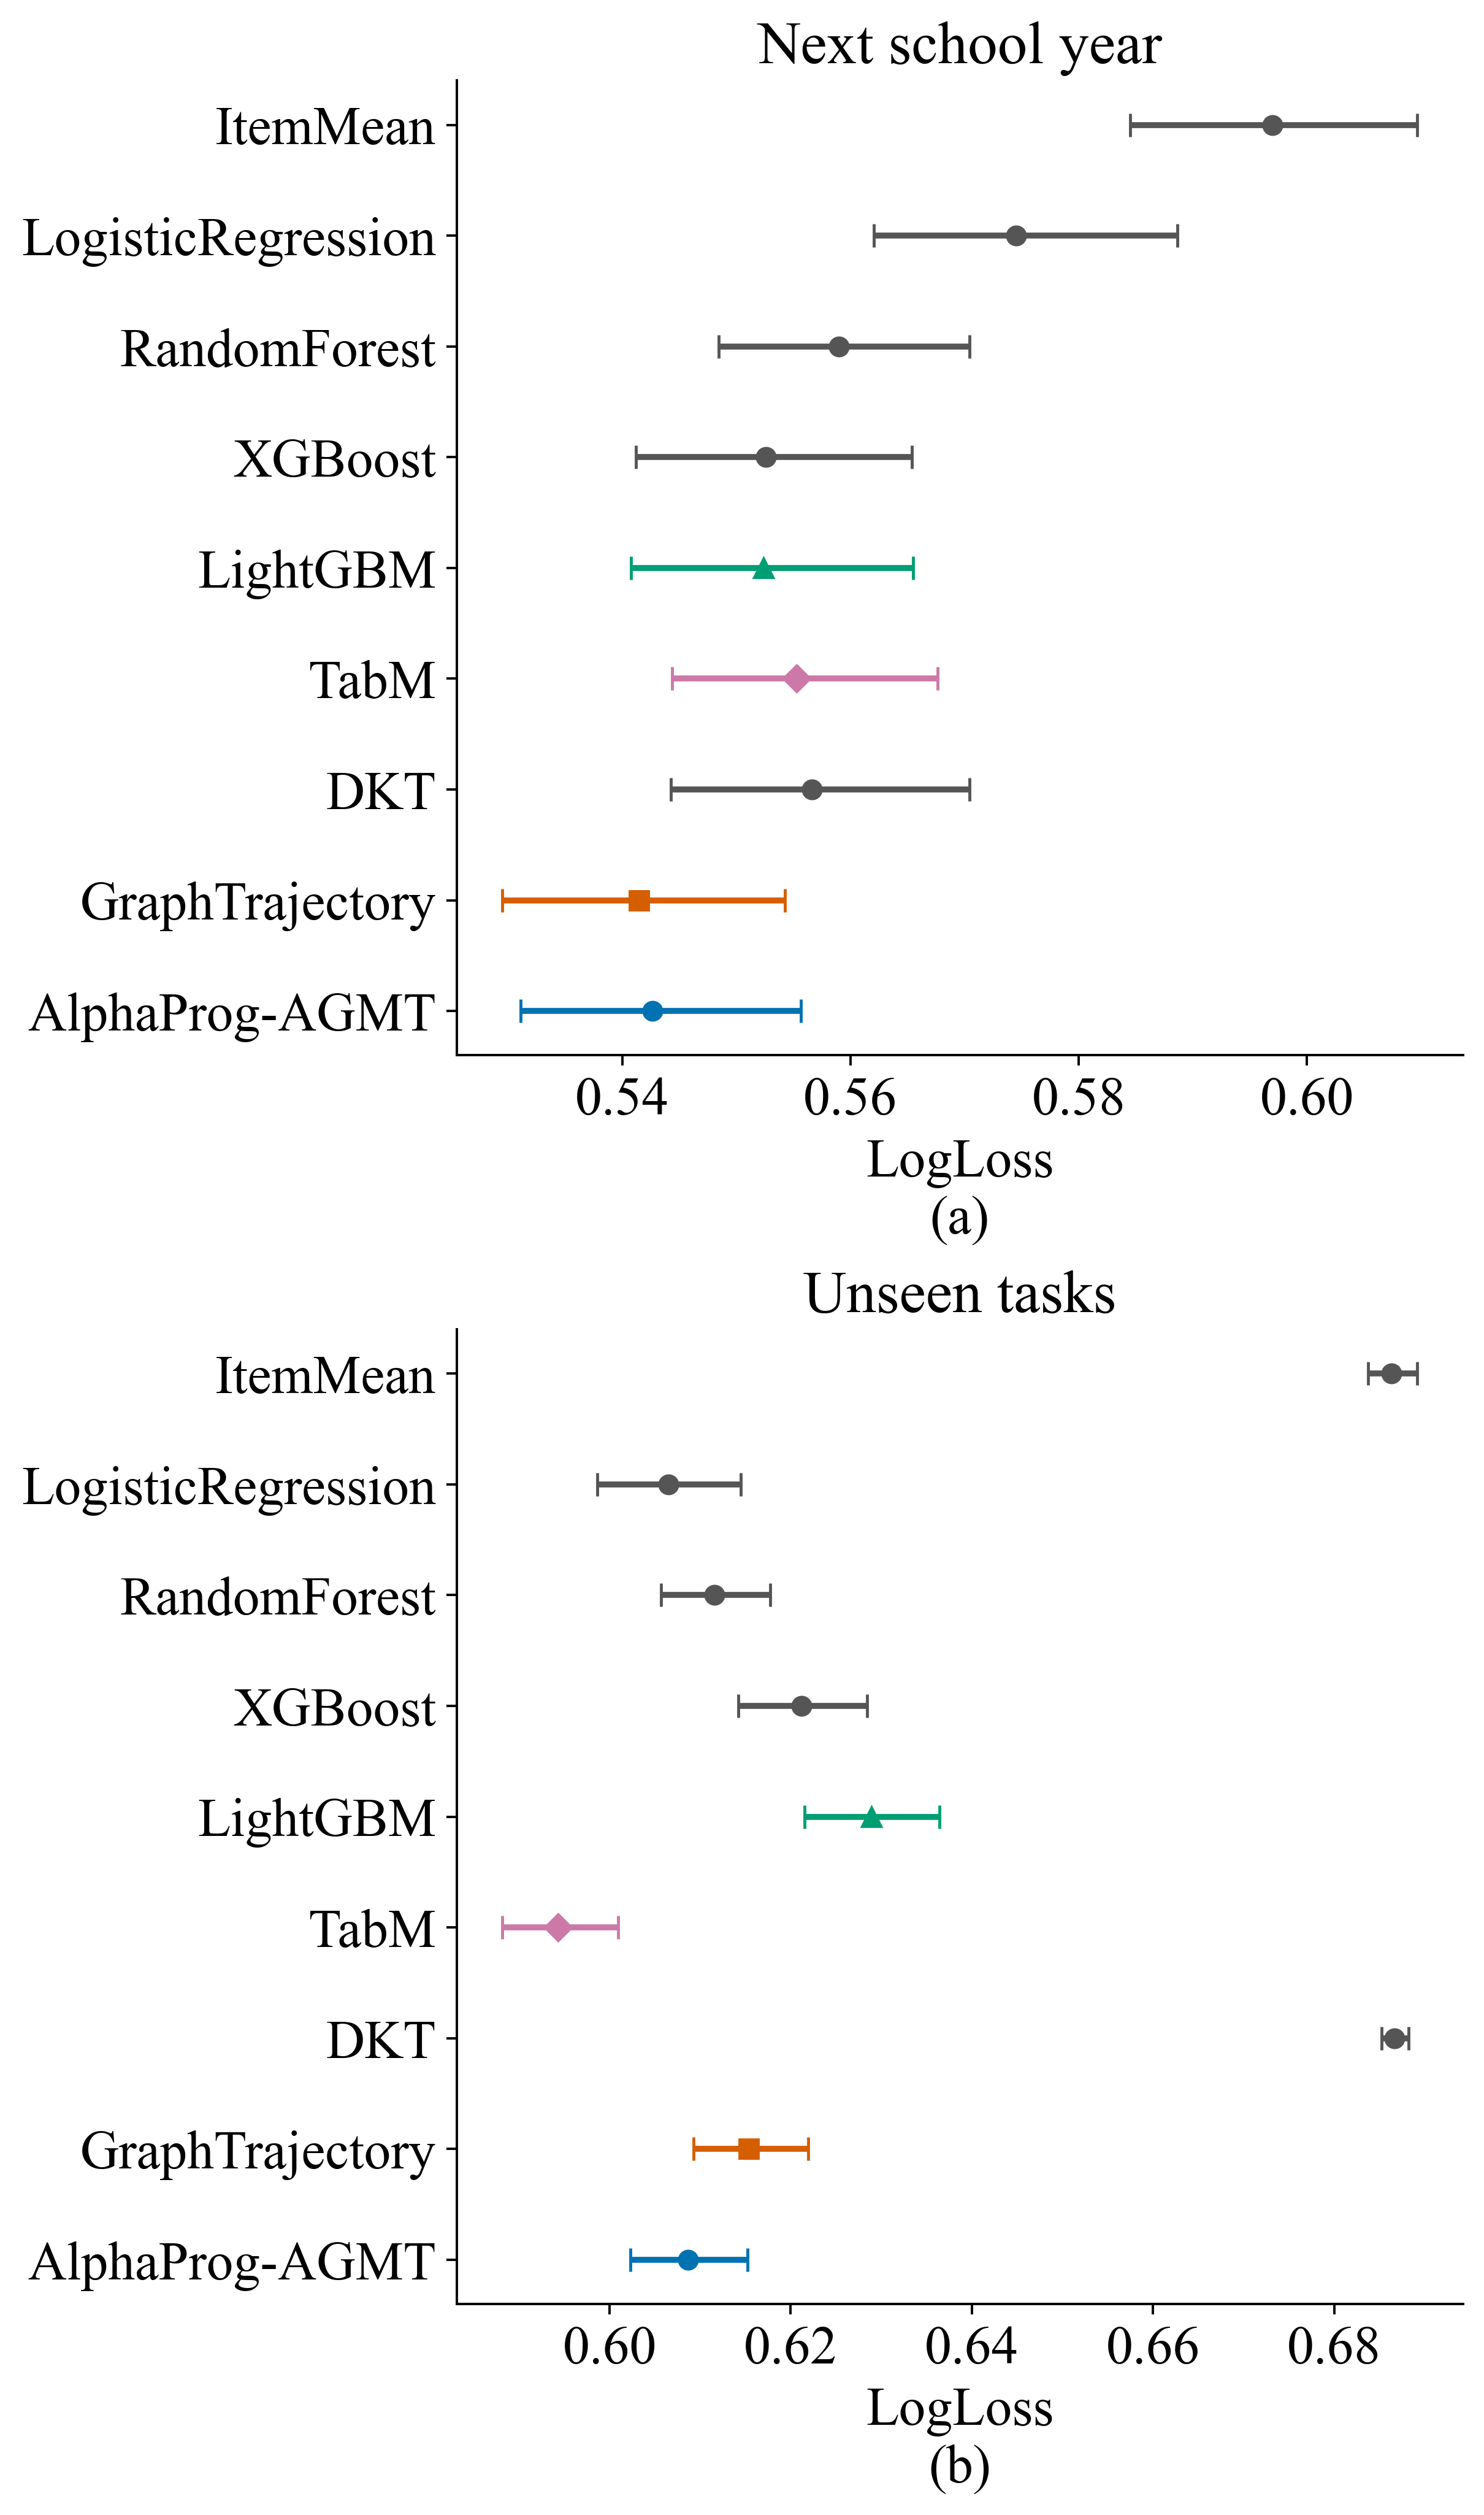

In [46]:
fig, axes = plt.subplots(2, 1, figsize=(6.8, 11.6), layout="constrained")
shown = ["ItemMean", "LogisticRegression", "RandomForest", "XGBoost", "LightGBM", "TabM", "DKT", "GraphTrajectory", "AlphaProg-AGMT"]
for ax, scheme, letter in zip(axes, ["Next school year", "Unseen tasks"], ["a", "b"]):
    rows = generalisation[generalisation.Scheme.eq(scheme)].set_index("Model").loc[shown]
    positions = np.arange(len(shown))
    colors = [PALETTE.get(model, "#555555") for model in shown]
    for position, (value, low, high), color, model in zip(positions, rows[["LogLoss", "CI_low", "CI_high"]].to_numpy(), colors, shown):
        ax.errorbar(value, position, xerr=[[value - low], [high - value]], fmt=MARKERS.get(model, "o"), color=color, capsize=4, linewidth=2)
    ax.set_yticks(positions, shown)
    ax.invert_yaxis()
    ax.set_title(scheme)
    panel_label(ax, letter, "LogLoss")
    ax.spines[["top", "right"]].set_visible(False)
save_figure(fig, "07_generalisation_quality")
plt.show()

**Interpretation.** *Next school year* (training on queries before 1 September 2019; evaluation on 5,684 queries of 495 locked-test learners after this date): AlphaProg-AGMT (0.54267) is better than LightGBM by 0.00970 [0.00696, 0.01250], than XGBoost by 0.00993, than TabM by 0.01258 and than DKT by 0.01397 (p_Holm = 0.0055); in Effort NLL it is better than LightGBM by 0.01579 [0.01135, 0.02023]. The hybrid does not differ from GraphTrajectory: LogLoss −0.00121 [−0.00266, 0.00029], Effort NLL −0.00086 [−0.00322, 0.00151]. The model order coincides with that of the original split, although simultaneous work of train and evaluation learners on the same task almost disappears (0.035% of queries versus 98.8%). The advantage is therefore not explained by shared school classes and shared time.

*Unseen tasks*: the task identifier is unavailable, and every model loses accuracy. DKT and ItemMean fall to the level of GlobalMean (0.686–0.687). The lowest LogLoss belongs to TabM (0.59432), followed by logistic regression (0.60653) and AlphaProg-AGMT (0.60863); GraphTrajectory reaches 0.61535, XGBoost 0.62119 and LightGBM 0.62888. AlphaProg-AGMT is better than its own expert by 0.00672 [0.00473, 0.00887], than XGBoost by 0.01256 [0.01008, 0.01502] and than LightGBM by 0.02025 [0.01762, 0.02282]; it does not differ from logistic regression (−0.00210 [−0.00666, 0.00318]) and is worse than TabM by 0.01431 [0.01201, 0.01658]. In Effort NLL it is better than LightGBM by 0.05440 [0.04987, 0.05890] and worse than the expert by 0.00562 [0.00155, 0.00945].

Two conclusions follow. The gate coefficients for new tasks do what they were adopted for on the first run: when the task is new, the fused first-run forecast is better than both of its components, as on validation in notebook 05; the fused effort forecast is not better than that of the expert. And the model loses the lead it has on known tasks. By construction, the task-specific modules of the expert carry no information for a task without training data: the read-out row of a new task is untrained, and the forecast falls back on the shared layers. This is the likely reason for the loss; the scheme does not isolate the contribution of each module, because the ablated variants were not retrained in it. The algorithm is therefore intended for tasks that already have training data. For a newly added task, a model that relies on task descriptors, such as TabM, is preferable until attempts on that task have been collected.

### Convergence of the neural comparators

Are eight epochs sufficient for DKT, AKT, UKT and TabM? Each model is trained on the full train set for 16 epochs (seed 17) with the learning rate selected in notebook 04 and with the frozen objective function and update rule. After each epoch, predictions for validation and the locked test are computed; the epoch is selected solely by validation LogLoss. The state of the random number generators is saved around the intermediate evaluation, so the training trajectory coincides with ordinary training of the same length. All models are trained on a single CUDA device; the earlier results of notebook 04 were obtained in separate runs on CUDA (DKT, UKT, TabM) and CPU (AKT), so the epoch-8 values need not coincide with them bit for bit.

In [47]:
import os
import platform
import subprocess
from collections import Counter

import torch.nn.functional as F
from torch import nn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

CONVERGENCE = post_hoc["experiments"]["neural_convergence"]
selected_rates = joblib.load(ROOT / "Results/04_selection.joblib")["selected"]
EVALUATION_FRAMES = {"validation": validation_data, "test": test_data}


def device_sync(device: torch.device) -> None:
    """Wait for queued accelerator work before reading a timer."""
    if device.type == "cuda":
        torch.cuda.synchronize()


@contextlib.contextmanager
def neural_device(device: torch.device, threads: int):
    """Run frozen notebook-04 helpers on one device with a fixed CPU thread count."""
    previous = (
        ns04["DEVICE"],
        ns04["akt_module"].device,
        ns04["ukt_module"].device,
        torch.get_num_threads(),
    )
    ns04["DEVICE"] = device
    ns04["akt_module"].device = device
    ns04["ukt_module"].device = device
    torch.set_num_threads(threads)
    try:
        yield
    finally:
        ns04["DEVICE"], ns04["akt_module"].device, ns04["ukt_module"].device = previous[:3]
        torch.set_num_threads(previous[3])


def neural_tensors(name: str, frames: dict) -> tuple[dict, dict, int]:
    """Training and evaluation tensors with TabM preprocessing fitted on train only."""
    numeric = {"train": None}
    if name == "TabM":
        preprocessing = make_pipeline(
            SimpleImputer(strategy="median", add_indicator=True), StandardScaler()
        )
        numeric["train"] = preprocessing.fit_transform(
            train_data[ns04["numeric_names"]]
        ).astype(np.float32)
        for key, frame in frames.items():
            numeric[key] = preprocessing.transform(
                frame[ns04["numeric_names"]]
            ).astype(np.float32)
    fit_inputs = ns04["tensor_data"](train_data, kt_sequences["train"], numeric["train"])
    evaluation = {
        key: ns04["tensor_data"](frame, kt_sequences[key], numeric.get(key))
        for key, frame in frames.items()
    }
    n_numeric = 0 if numeric["train"] is None else numeric["train"].shape[1]
    return fit_inputs, evaluation, n_numeric


def train_neural(
    name: str,
    learning_rate: float,
    seed: int,
    epochs: int,
    device: torch.device,
    frames: dict,
    threads: int = 2,
    evaluate_each_epoch: bool = False,
) -> dict:
    """Notebook-04 objective and AdamW update on all train rows; timed by stage."""
    with neural_device(device, threads):
        ns04["set_seed"](seed)
        device_sync(device)
        started = time.perf_counter()
        fit_inputs, evaluation, n_numeric = neural_tensors(name, frames)
        model = ns04["make_model"](name, n_numeric)
        optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)
        device_sync(device)
        preparation_s = time.perf_counter() - started
        n_rows, batch_size = len(train_data), ns04["BATCH_SIZE"]
        records, epoch_seconds, snapshots, inference_s = [], [], {}, float("nan")
        for epoch in range(1, epochs + 1):
            model.train()
            epoch_started = time.perf_counter()
            permutation = torch.randperm(n_rows, device=device)
            total = 0.0
            for start in range(0, n_rows, batch_size):
                indices = permutation[start : start + batch_size]
                batch = ns04["subset"](fit_inputs, indices)
                optimizer.zero_grad(set_to_none=True)
                _, loss = ns04["model_output"](model, name, batch, training=True)
                assert bool(torch.isfinite(loss).item())
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
                optimizer.step()
                total += loss.detach().item() * len(indices)
            device_sync(device)
            epoch_seconds.append(time.perf_counter() - epoch_started)
            if evaluate_each_epoch or epoch == epochs:
                cpu_state = torch.random.get_rng_state()
                cuda_state = torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None
                inference_started = time.perf_counter()
                predicted = {
                    key: ns04["predict"](model, name, data) for key, data in evaluation.items()
                }
                device_sync(device)
                inference_s = time.perf_counter() - inference_started
                torch.random.set_rng_state(cpu_state)
                if cuda_state is not None:
                    torch.cuda.set_rng_state_all(cuda_state)
                snapshots[epoch] = predicted
                records.append(
                    {
                        "Epoch": epoch,
                        "Training_objective": total / n_rows,
                        **{
                            f"{key.capitalize()}_LogLoss": float(
                                binary_loss(frame.y.to_numpy(), predicted[key]).mean()
                            )
                            for key, frame in frames.items()
                        },
                    }
                )
        parameters = sum(parameter.numel() for parameter in model.parameters())
        del model, optimizer, fit_inputs, evaluation
        gc.collect()
        if device.type == "cuda":
            torch.cuda.empty_cache()
    return {
        "records": records,
        "snapshots": snapshots,
        "preparation_s": preparation_s,
        "epoch_s": epoch_seconds,
        "inference_s": inference_s,
        "parameters": parameters,
        "device": str(device),
    }


progress = Progress("Neural convergence")
convergence = {}
for name in CONVERGENCE["models"]:
    progress.update(f"{name}, {CONVERGENCE['epochs']} epochs, seed {CONVERGENCE['seed']}")
    convergence[name] = cached(
        f"convergence_{name}_{CONVERGENCE['seed']}",
        lambda: train_neural(
            name,
            selected_rates[name],
            CONVERGENCE["seed"],
            CONVERGENCE["epochs"],
            ANALYSIS_DEVICE,
            EVALUATION_FRAMES,
            evaluate_each_epoch=True,
        ),
    )
progress.close()

In [48]:
FROZEN_EPOCHS = ns04["EPOCHS"]
proposed_seed_17 = binary_loss(
    test_data.y.to_numpy(),
    components["joint_by_seed"][("AlphaProg-AGMT", CONVERGENCE["seed"])][:, 0],
)
convergence_rows, convergence_effects = [], []
for name, result in convergence.items():
    records = pd.DataFrame(result["records"]).set_index("Epoch")
    chosen = int(records.Validation_LogLoss.idxmin())
    truth = test_data.y.to_numpy()
    loss_frozen = binary_loss(truth, result["snapshots"][FROZEN_EPOCHS]["test"])
    loss_chosen = binary_loss(truth, result["snapshots"][chosen]["test"])
    convergence_rows.append(
        {
            "Model": name,
            "Learning_rate": selected_rates[name],
            "Validation_LogLoss_epoch_8": records.loc[FROZEN_EPOCHS, "Validation_LogLoss"],
            "Selected_epoch": chosen,
            "Validation_LogLoss_selected": records.loc[chosen, "Validation_LogLoss"],
            "Test_LogLoss_epoch_8": loss_frozen.mean(),
            "Test_LogLoss_selected": loss_chosen.mean(),
        }
    )
    for comparison, baseline, candidate in [
        ("Epoch 8 − selected epoch", loss_frozen, loss_chosen),
        ("Selected epoch − AlphaProg-AGMT (seed 17)", loss_chosen, proposed_seed_17),
    ]:
        convergence_effects.append(
            {"Model": name, "Comparison": comparison, **cluster_effect(STUDENTS, baseline, candidate)}
        )
convergence_effects = pd.DataFrame(convergence_effects)
convergence_effects["p_Holm"] = holm_adjust(convergence_effects.p_raw.to_numpy())
table(
    pd.DataFrame(convergence_rows),
    "Convergence of the comparators: LogLoss ↓ at epoch 8 and at the epoch selected on validation out of 16; seed 17, CUDA",
    "07_neural_convergence",
)
table(
    convergence_effects,
    "Difference in test LogLoss (> 0: the second model is better); 95% CI over learners; Holm over 8 comparisons",
    "07_neural_convergence_effects",
)

Convergence of the comparators: LogLoss ↓ at epoch 8 and at the epoch selected on validation out of 16; seed 17, CUDA

,Model,Learning_rate,Validation_LogLoss_epoch_8,Selected_epoch,Validation_LogLoss_selected,Test_LogLoss_epoch_8,Test_LogLoss_selected
0,DKT,0.001,0.53919,5,0.53801,0.54558,0.54391
1,AKT,0.001,0.53992,15,0.53754,0.54472,0.54188
2,UKT,0.001,0.54011,12,0.53781,0.54660,0.54362
3,TabM,0.003,0.53264,16,0.52986,0.53887,0.53460


Difference in test LogLoss (> 0: the second model is better); 95% CI over learners; Holm over 8 comparisons

,Model,Comparison,Effect,CI_low,CI_high,p_raw,p_Holm
0,DKT,Epoch 8 − selected epoch,0.00166,0.00024,0.00322,0.02749,0.02749
1,DKT,Selected epoch − AlphaProg-AGMT (seed 17),0.01864,0.01592,0.02174,0.00050,0.00400
2,AKT,Epoch 8 − selected epoch,0.00284,0.00128,0.00444,0.00100,0.00400
3,AKT,Selected epoch − AlphaProg-AGMT (seed 17),0.01660,0.01395,0.01934,0.00050,0.00400
4,UKT,Epoch 8 − selected epoch,0.00298,0.00136,0.00457,0.00050,0.00400
5,UKT,Selected epoch − AlphaProg-AGMT (seed 17),0.01834,0.01574,0.02104,0.00050,0.00400
6,TabM,Epoch 8 − selected epoch,0.00427,0.00281,0.00559,0.00050,0.00400
7,TabM,Selected epoch − AlphaProg-AGMT (seed 17),0.00932,0.00743,0.01121,0.00050,0.00400


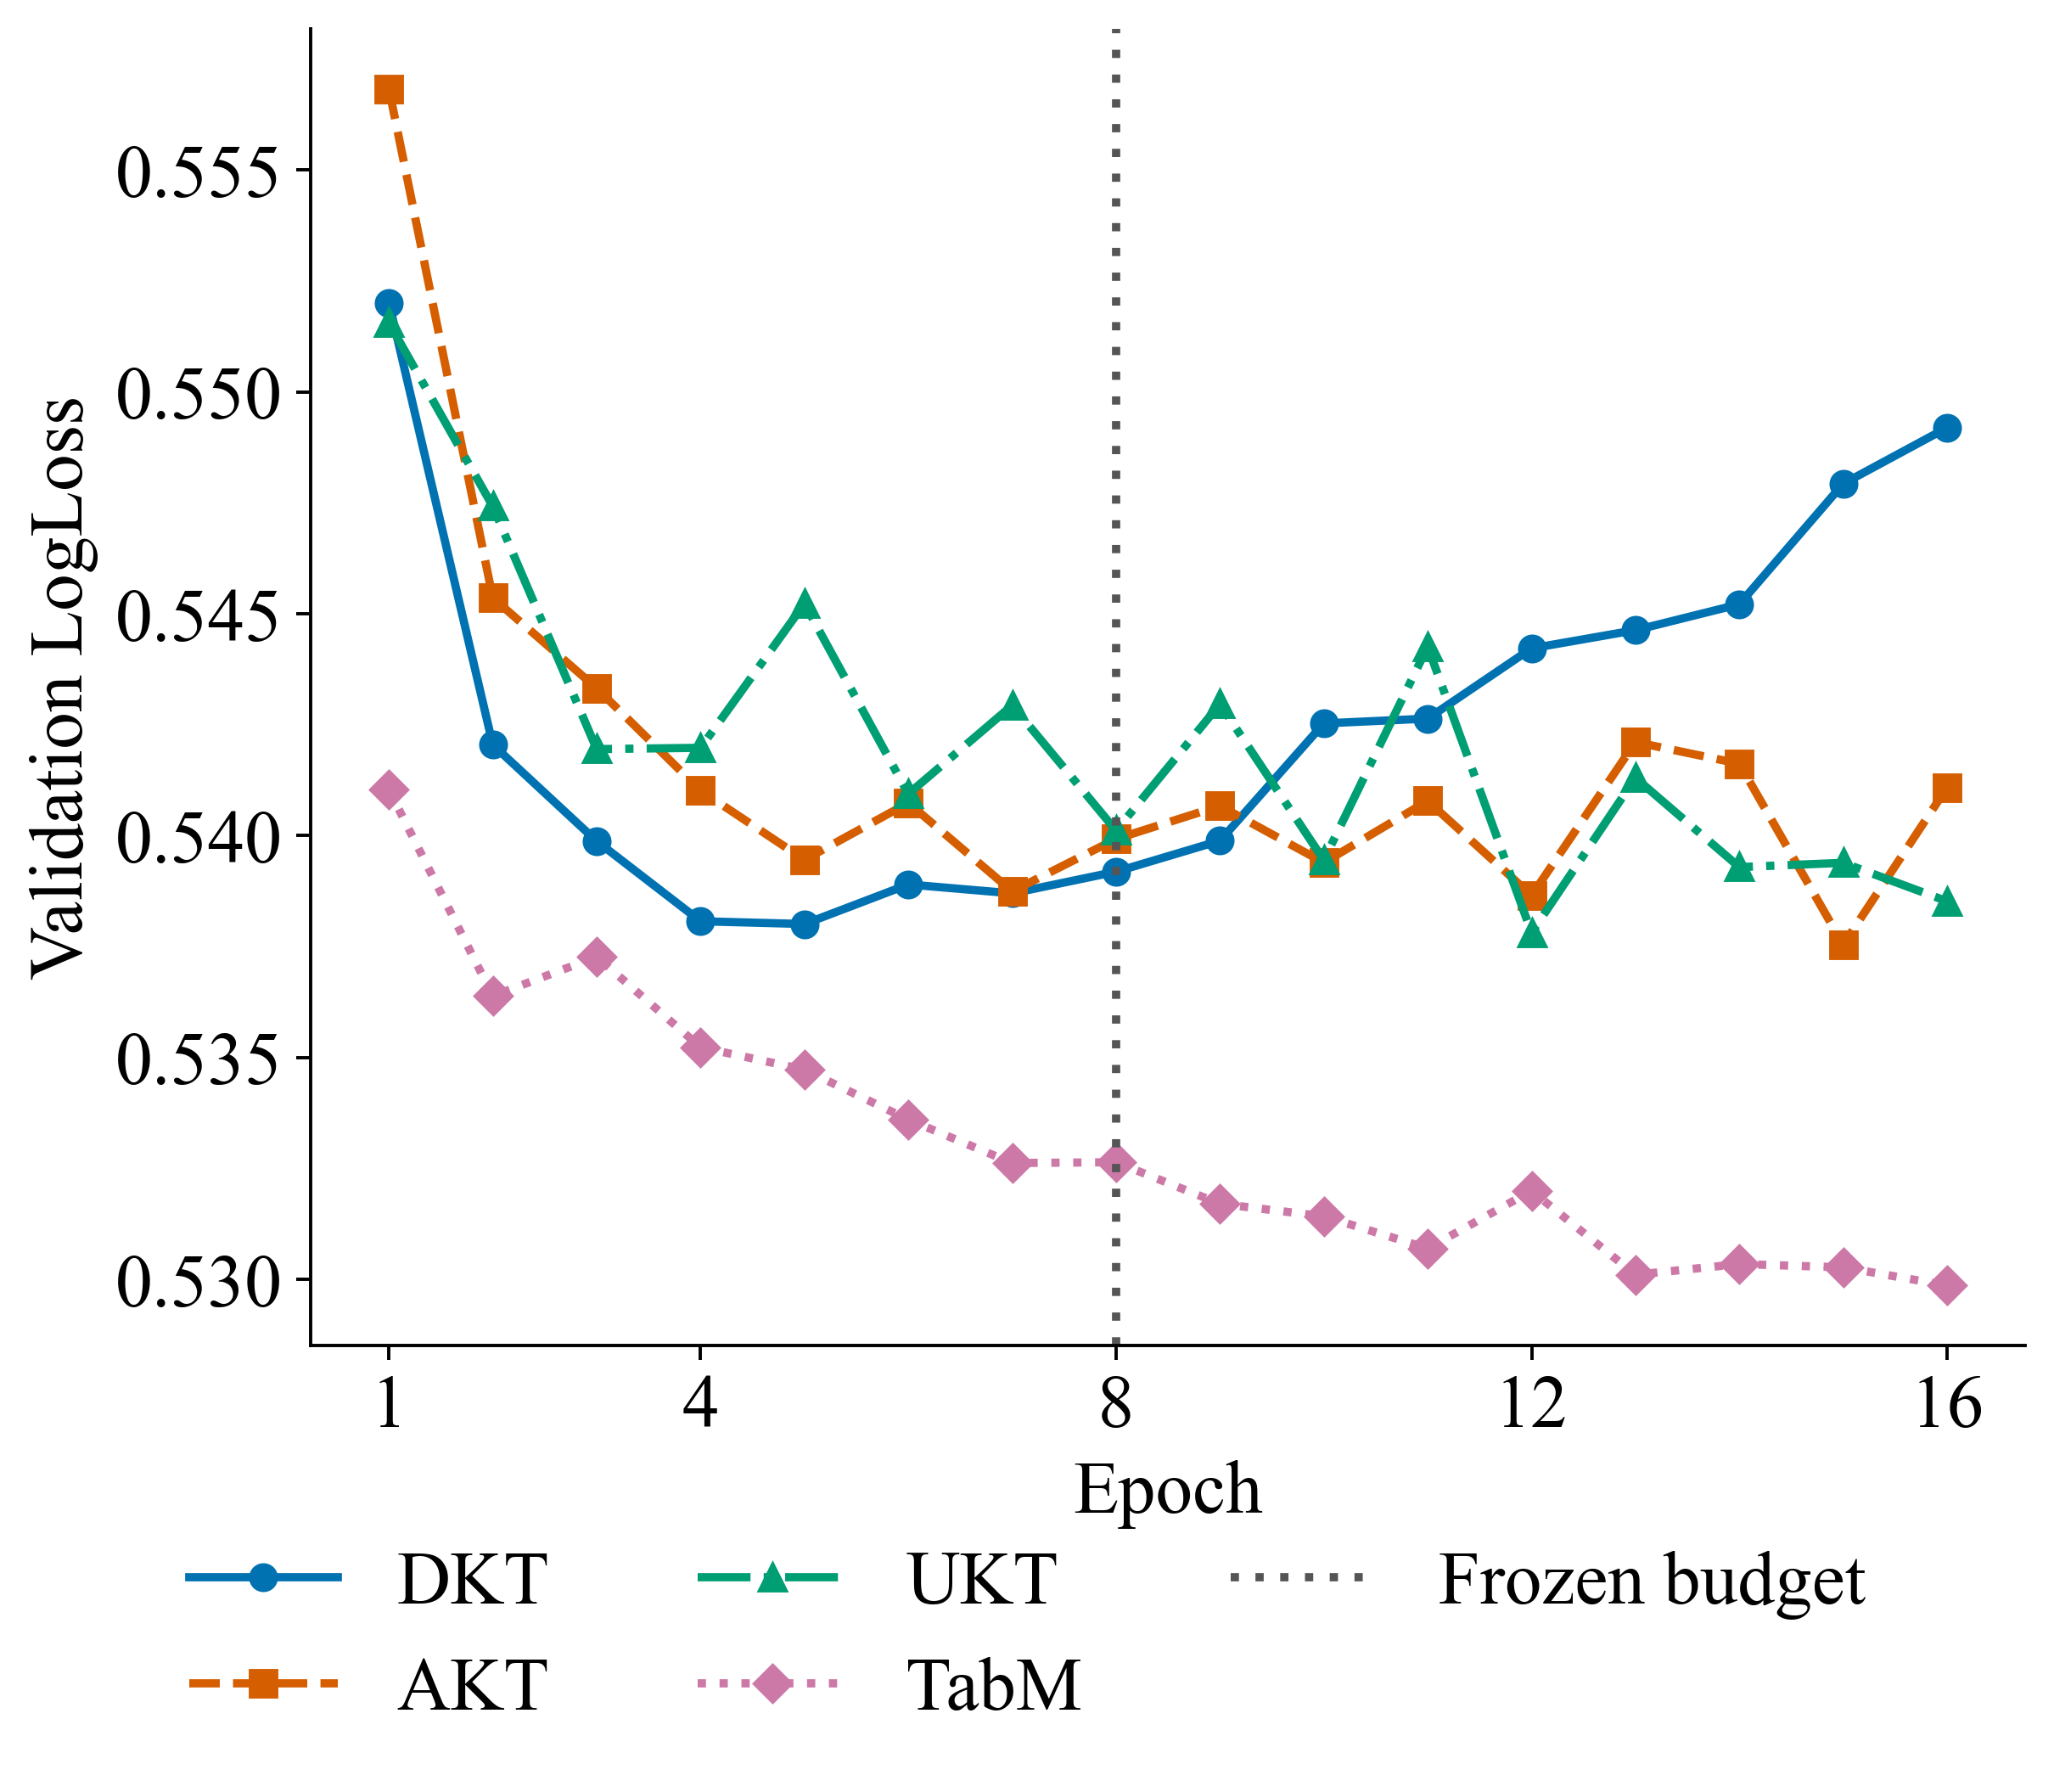

In [49]:
CONVERGENCE_STYLE = {
    "DKT": ("#0072B2", "o", "-"),
    "AKT": ("#D55E00", "s", "--"),
    "UKT": ("#009E73", "^", "-."),
    "TabM": ("#CC79A7", "D", ":"),
}
fig, ax = plt.subplots(figsize=(6.8, 6.0), layout="constrained")
for name, result in convergence.items():
    records = pd.DataFrame(result["records"])
    color, marker, linestyle = CONVERGENCE_STYLE[name]
    ax.plot(
        records.Epoch,
        records.Validation_LogLoss,
        color=color,
        marker=marker,
        linestyle=linestyle,
        linewidth=2,
        label=name,
    )
ax.axvline(FROZEN_EPOCHS, color="#555555", linestyle=(0, (1, 2)), linewidth=2, label="Frozen budget")
ax.set_xticks([1, 4, 8, 12, 16])
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation LogLoss")
ax.spines[["top", "right"]].set_visible(False)
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=3, frameon=False)
save_figure(fig, "07_neural_convergence")
plt.show()

**Interpretation.** Eight epochs were insufficient for full convergence of the comparators. With epoch selection on validation, the test LogLoss decreased for DKT by 0.00166 [0.00024, 0.00322] (epoch 5), for AKT by 0.00284 [0.00128, 0.00444] (epoch 15), for UKT by 0.00298 [0.00136, 0.00457] (epoch 12) and for TabM by 0.00427 [0.00281, 0.00559]. For TabM, epoch 16, the upper bound of the grid, was selected, so its quality might have improved further. Even after additional training, all models remain behind AlphaProg-AGMT with the same seed 17: TabM by 0.00932 [0.00743, 0.01121], AKT by 0.01660, UKT by 0.01834 and DKT by 0.01864 (p_Holm = 0.004). The fixed budget slightly understated the quality of the comparators but does not explain the advantage of the proposed model.

### Matched inputs: LightGBM with sequential features

Is the gain of the structural-temporal expert explained by its architecture or by a richer input? The expert receives 51 aggregates, the task, 30 process channels for each of the 32 most recent attempts, and the program graphs. LightGBM-Sequence receives the same 51 aggregates and the task and, in addition, 30 process channels for each of the 8 most recent attempts (lag 1 is the most recent attempt; 240 features). Missing lags remain missing values and receive indicators. The channels include structural code summaries and the task description of each past attempt. The LightGBM hyperparameters are frozen from notebook 03; all transformations are fitted on train. Training on the full train set, three seeds.

In [50]:
baseline_settings = json.loads((ROOT / "Protocol/baseline_configurations.json").read_text())
SEQUENCE_LAGS = 8
PROCESS_NAMES = list(ns05["PROCESS_COLUMNS"])
SEQUENCE_NAMES = [
    f"lag{lag}_{channel}" for lag in range(1, SEQUENCE_LAGS + 1) for channel in PROCESS_NAMES
]


def sequence_frame(frame: pd.DataFrame, history: dict) -> pd.DataFrame:
    """Aggregates and task plus raw process channels of the most recent prior attempts."""
    process, length = history["process"], history["length"]
    assert len(frame) == len(length) and process.shape[-1] == len(PROCESS_NAMES)
    block = np.full((len(frame), SEQUENCE_LAGS, process.shape[-1]), np.nan, dtype=np.float32)
    for lag in range(SEQUENCE_LAGS):
        rows = np.flatnonzero(length > lag)
        block[rows, lag] = process[rows, length[rows] - 1 - lag]
    lags = pd.DataFrame(block.reshape(len(frame), -1), columns=SEQUENCE_NAMES)
    return pd.concat([frame[ns03["feature_names"]].reset_index(drop=True), lags], axis=1)


def sequence_preprocessor() -> ColumnTransformer:
    """Notebook-03 transformation extended to the lagged process channels."""
    numeric = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler())
    categorical = OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32)
    return ColumnTransformer(
        [("numeric", numeric, list(ns03["numeric_names"]) + SEQUENCE_NAMES), ("task", categorical, ["problem"])],
        sparse_threshold=0,
    )


SEQUENCE_INPUTS = {
    "train": sequence_frame(train_data, graph_history["train"]),
    "validation": sequence_frame(validation_data, graph_history["validation"]),
    "test": sequence_frame(test_data, graph_history["test"]),
}


def lightgbm_sequence(seed: int, n_jobs: int | None = None) -> dict:
    """Frozen LightGBM settings on the matched sequential inputs."""
    started = time.perf_counter()
    preprocessing = sequence_preprocessor()
    fit_matrix = ns03["transformed_frame"](preprocessing.fit_transform(SEQUENCE_INPUTS["train"]))
    estimator = ns03["make_estimator"]("LightGBM", baseline_settings["LightGBM"], seed)
    if n_jobs is not None:
        estimator.set_params(n_jobs=n_jobs)
    estimator.fit(fit_matrix, train_data.y.to_numpy())
    fit_s = time.perf_counter() - started
    result = {"fit_s": fit_s, "n_inputs": fit_matrix.shape[1]}
    for key in ["validation", "test"]:
        inference_started = time.perf_counter()
        matrix = ns03["transformed_frame"](preprocessing.transform(SEQUENCE_INPUTS[key]))
        result[key] = np.clip(estimator.predict_proba(matrix)[:, 1], 1e-6, 1 - 1e-6)
        result[f"{key}_inference_s"] = time.perf_counter() - inference_started
    return result


progress = Progress("LightGBM-Sequence")
sequence_forecasts = {}
for seed in SEEDS:
    progress.update(f"seed {seed}")
    sequence_forecasts[seed] = cached(f"lightgbm_sequence_{seed}", lambda: lightgbm_sequence(seed))
progress.close()

### Code-DKT-type model

Code-DKT (Shi et al., 2022) augments DKT with a code representation: leaf-to-leaf paths (code2vec-style path contexts) are extracted from the syntax tree of a program, their embeddings are weighted by attention, and the resulting code vector is combined with the DKT input at each step. Here the model is implemented from the published description, not from the authors' code. The RoboMission program tree (parent–child links) serves as the syntax tree. For each past program, up to 16 leaf-to-leaf paths are taken; when there are more pairs, the sampling is deterministic given the program number. The leaf and path vocabularies are trained on the training-fold programs; rare values are replaced with an “unknown” index. The input for the current task contains neither the answer nor the code. The budget matches that of DKT: width 64, 8 epochs, batch 512, AdamW with weight decay 10⁻⁴. The learning rate from {0.001, 0.003} is selected by out-of-fold LogLoss on three learner folds with seed 17; the model is then trained on the full train set with three seeds.

In [51]:
CODE_KT = post_hoc["experiments"]["code_aware_kt"]
CODE_PATHS = CODE_KT["path_contexts_per_program"]
NODE_KINDS = ns05["graph_archive"]["node_types"]
HISTORY_LENGTH = ns04["HISTORY_LENGTH"]


def program_path_contexts(graph: dict, program: int) -> list[tuple[str, str, str]]:
    """Leaf-to-leaf paths through the lowest common ancestor of one program tree."""
    parents, labels, kinds = graph["parents"], graph["labels"], graph["types"]
    child_count = Counter(parent for parent in parents if parent >= 0)
    leaves = [node for node in range(1, len(labels)) if child_count[node] == 0]
    if not leaves:
        return []

    def ancestry(node: int) -> list[int]:
        chain = [node]
        while parents[chain[-1]] >= 0:
            chain.append(parents[chain[-1]])
        return chain

    chains = {leaf: ancestry(leaf) for leaf in leaves}
    pairs = [(a, b) for index, a in enumerate(leaves) for b in leaves[index + 1 :]]
    pairs = pairs or [(leaves[0], leaves[0])]
    if len(pairs) > CODE_PATHS:
        chosen = np.random.default_rng(SEED + program).choice(len(pairs), CODE_PATHS, replace=False)
        pairs = [pairs[index] for index in sorted(chosen)]
    contexts = []
    for start, end in pairs:
        up, down = chains[start], chains[end]
        common = next(node for node in up if node in set(down))
        upward = up[: up.index(common) + 1]
        downward = list(reversed(down[: down.index(common)]))
        path = "^".join(NODE_KINDS[kinds[node]] for node in upward)
        path += "|" + "v".join(NODE_KINDS[kinds[node]] for node in downward)
        contexts.append((labels[start], path, labels[end]))
    return contexts


PROGRAM_CONTEXTS = [
    program_path_contexts(graph, index) for index, graph in enumerate(ns05["graph_archive"]["graphs"])
]


def context_tables(fitting_programs: np.ndarray) -> tuple[dict, int, int]:
    """Terminal and path vocabularies fitted on programs of training learners only."""
    terminals, paths = Counter(), Counter()
    for program in np.unique(fitting_programs):
        for start, path, end in PROGRAM_CONTEXTS[program]:
            terminals.update([start, end])
            paths.update([path])
    terminal_index = {
        token: index + 2 for index, token in enumerate(sorted(t for t, c in terminals.items() if c >= 2))
    }
    path_index = {
        token: index + 2 for index, token in enumerate(sorted(p for p, c in paths.items() if c >= 2))
    }
    shape = (len(PROGRAM_CONTEXTS), CODE_PATHS)
    start, path, end = (np.zeros(shape, dtype=np.int64) for _ in range(3))
    for program, contexts in enumerate(PROGRAM_CONTEXTS):
        for slot, (left, route, right) in enumerate(contexts):
            start[program, slot] = terminal_index.get(left, 1)
            path[program, slot] = path_index.get(route, 1)
            end[program, slot] = terminal_index.get(right, 1)
    tables = {"context_start": start, "context_path": path, "context_end": end}
    return tables, len(terminal_index) + 2, len(path_index) + 2


def code_sequence(frame: pd.DataFrame, source: dict) -> dict[str, np.ndarray]:
    """Program of each prior attempt, aligned with the notebook-04 interaction sequence."""
    assert np.array_equal(frame.id.to_numpy(), np.asarray(source["ids"]))
    lookup = {name: index for index, name in enumerate(source["columns"])}
    program = np.zeros((len(frame), HISTORY_LENGTH + 1), dtype=np.int64)
    present = np.zeros((len(frame), HISTORY_LENGTH + 1), dtype=bool)
    for row, history in enumerate(source["sequences"]):
        observed = [step for step in history if step[lookup["first_observed"]] == 1][-HISTORY_LENGTH:]
        for position, step in enumerate(observed):
            program[row, position] = int(step[lookup["graph_id"]])
            present[row, position] = True
    return {"program": program, "program_present": present}


code_sequences = {
    "train": code_sequence(train_data, sequence_sources["train"]),
    "validation": code_sequence(validation_data, sequence_sources["validation"]),
    "test": code_sequence(test_data, sequence_sources["locked_test"]),
}
for split, arrays in code_sequences.items():
    assert np.array_equal(arrays["program_present"].sum(axis=1), kt_sequences[split]["position"])


class CodeDKT(nn.Module):
    """DKT whose step input also contains an attention-pooled bag of program path contexts."""

    def __init__(self, n_tasks: int, width: int, n_terminals: int, n_paths: int, tables: dict):
        super().__init__()
        self.n_tasks = n_tasks
        self.interaction = nn.Embedding(2 * (n_tasks + 1), width)
        self.terminal = nn.Embedding(n_terminals, width, padding_idx=0)
        self.route = nn.Embedding(n_paths, width, padding_idx=0)
        self.combine = nn.Linear(3 * width, width)
        self.attention = nn.Linear(width, 1, bias=False)
        self.recurrent = nn.LSTM(2 * width, width, batch_first=True)
        self.output = nn.Linear(width, n_tasks + 1)
        for name, values in tables.items():
            self.register_buffer(name, values, persistent=False)

    def code_vector(self, program: torch.Tensor, present: torch.Tensor) -> torch.Tensor:
        route = self.context_path[program]
        mask = (route > 0) & present.unsqueeze(-1)
        context = torch.tanh(
            self.combine(
                torch.cat(
                    [
                        self.terminal(self.context_start[program]),
                        self.route(route),
                        self.terminal(self.context_end[program]),
                    ],
                    dim=-1,
                )
            )
        )
        score = self.attention(context).squeeze(-1).masked_fill(~mask, -1e9)
        weight = torch.softmax(score, dim=-1) * mask
        return (weight.unsqueeze(-1) * context).sum(dim=-2)

    def forward(self, batch: dict[str, torch.Tensor]) -> torch.Tensor:
        interaction = self.interaction(batch["task"] + (self.n_tasks + 1) * batch["response"])
        code = self.code_vector(batch["program"], batch["program_present"])
        states, _ = self.recurrent(torch.cat([interaction, code], dim=-1))
        rows = torch.arange(len(states), device=states.device)
        previous = states[rows, (batch["position"] - 1).clamp(min=0)]
        previous = previous * (batch["position"] > 0).unsqueeze(1)
        query = batch["task"][rows, batch["position"]]
        return self.output(previous)[rows, query]


def code_tensors(frame: pd.DataFrame, interactions: dict, programs: dict, device: torch.device) -> dict:
    arrays = {key: interactions[key] for key in ["task", "response", "position"]} | programs
    tensors = {key: torch.as_tensor(value, device=device) for key, value in arrays.items()}
    tensors["y"] = torch.as_tensor(frame.y.to_numpy(dtype=np.float32), device=device)
    return tensors


def code_predict(model: nn.Module, inputs: dict, batch_size: int) -> np.ndarray:
    model.eval()
    output = []
    with torch.inference_mode():
        for start in range(0, len(inputs["y"]), batch_size):
            batch = {key: value[start : start + batch_size] for key, value in inputs.items()}
            output.append(model(batch).sigmoid().cpu().numpy())
    result = np.concatenate(output).astype(float)
    assert np.isfinite(result).all()
    return np.clip(result, 1e-6, 1 - 1e-6)


def fit_code_dkt(
    fitting: np.ndarray,
    evaluations: dict,
    learning_rate: float,
    seed: int,
    device: torch.device,
    epochs: int = 8,
    threads: int = 2,
) -> dict:
    """Train the Code-DKT-type comparator on training rows only, under the DKT budget."""
    batch_size = ns04["BATCH_SIZE"]
    previous_threads = torch.get_num_threads()
    torch.set_num_threads(threads)
    ns04["set_seed"](seed)
    device_sync(device)
    started = time.perf_counter()
    train_programs = code_sequences["train"]["program"][fitting]
    train_present = code_sequences["train"]["program_present"][fitting]
    tables, n_terminals, n_paths = context_tables(train_programs[train_present])
    tables = {key: torch.as_tensor(value, device=device) for key, value in tables.items()}
    fit_inputs = code_tensors(
        train_data.iloc[fitting],
        take_history(kt_sequences["train"], fitting),
        take_history(code_sequences["train"], fitting),
        device,
    )
    evaluation = {
        key: code_tensors(frame, interactions, programs, device)
        for key, (frame, interactions, programs) in evaluations.items()
    }
    model = CodeDKT(ns04["N_TASKS"], ns04["HIDDEN_SIZE"], n_terminals, n_paths, tables).to(device)
    model.eval()
    probe_source = next(iter(evaluation.values()))
    probe_rows = torch.argsort(probe_source["position"])[
        torch.linspace(0, len(probe_source["y"]) - 1, 8, device=device).long()
    ]
    probe = {key: value[probe_rows].clone() for key, value in probe_source.items()}
    altered = {key: value.clone() for key, value in probe.items()}
    hidden = torch.arange(HISTORY_LENGTH + 1, device=device).unsqueeze(0) >= probe["position"].unsqueeze(1)
    altered["response"][hidden] = 1 - altered["response"][hidden]
    altered["program"][hidden] = 1
    altered["program_present"][hidden] = True
    with torch.inference_mode():
        assert torch.allclose(model(probe), model(altered), atol=1e-6, rtol=1e-5), "Query leakage"
    optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=1e-4)
    device_sync(device)
    preparation_s = time.perf_counter() - started
    epoch_seconds = []
    for epoch in range(1, epochs + 1):
        model.train()
        epoch_started = time.perf_counter()
        permutation = torch.randperm(len(fitting), device=device)
        for start in range(0, len(fitting), batch_size):
            indices = permutation[start : start + batch_size]
            batch = {key: value[indices] for key, value in fit_inputs.items()}
            optimizer.zero_grad(set_to_none=True)
            loss = F.binary_cross_entropy_with_logits(model(batch), batch["y"])
            assert bool(torch.isfinite(loss).item())
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
        device_sync(device)
        epoch_seconds.append(time.perf_counter() - epoch_started)
    result = {"preparation_s": preparation_s, "epoch_s": epoch_seconds, "device": str(device)}
    for key, inputs in evaluation.items():
        inference_started = time.perf_counter()
        result[key] = code_predict(model, inputs, batch_size)
        device_sync(device)
        result[f"{key}_inference_s"] = time.perf_counter() - inference_started
    result["parameters"] = sum(parameter.numel() for parameter in model.parameters())
    del model, optimizer, fit_inputs, evaluation, tables
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    torch.set_num_threads(previous_threads)
    return result



def code_evaluation(split: str, rows: np.ndarray | None = None) -> tuple:
    frame = {"train": train_data, "validation": validation_data, "test": test_data}[split]
    interactions, programs = kt_sequences[split], code_sequences[split]
    if rows is not None:
        frame = frame.iloc[rows].reset_index(drop=True)
        interactions, programs = take_history(interactions, rows), take_history(programs, rows)
    return frame, interactions, programs


def code_dkt_oof(rate: float) -> np.ndarray:
    """Learner-held-out predictions for one learning rate with seed 17."""
    result = np.full(len(train_data), np.nan)
    for fold in sorted(train_data.fold.unique()):
        held = train_data.fold.eq(fold).to_numpy()
        output = fit_code_dkt(
            np.flatnonzero(~held),
            {"held": code_evaluation("train", np.flatnonzero(held))},
            rate,
            SEEDS[0],
            ANALYSIS_DEVICE,
        )
        result[held] = output["held"]
    assert np.isfinite(result).all()
    return result


progress = Progress("Code-DKT-type")
code_tuning_rows = []
for rate in CODE_KT["learning_rates"]:
    progress.update(f"OOF, learning rate {rate}")
    oof = cached(f"code_dkt_oof_{rate}_{SEEDS[0]}", lambda: code_dkt_oof(rate))
    code_tuning_rows.append(
        {
            "Model": "Code-DKT-type",
            "Split": "Train OOF",
            "n": len(train_data),
            "Learning_rate": rate,
            "LogLoss": float(binary_loss(train_data.y.to_numpy(), oof).mean()),
        }
    )
code_tuning = pd.DataFrame(code_tuning_rows)
CODE_RATE = float(code_tuning.loc[code_tuning.LogLoss.idxmin(), "Learning_rate"])
code_tuning["Selected"] = code_tuning.Learning_rate.eq(CODE_RATE)
code_forecasts = {}
for seed in SEEDS:
    progress.update(f"full train, learning rate {CODE_RATE}, seed {seed}")
    code_forecasts[seed] = cached(
        f"code_dkt_full_{CODE_RATE}_{seed}",
        lambda: fit_code_dkt(
            np.arange(len(train_data)),
            {"validation": code_evaluation("validation"), "test": code_evaluation("test")},
            CODE_RATE,
            seed,
            ANALYSIS_DEVICE,
        ),
    )
progress.close()
table(
    code_tuning,
    "Code-DKT-type: learning-rate selection by out-of-fold LogLoss ↓ (three learner folds, seed 17)",
    "07_code_dkt_tuning",
)

Code-DKT-type: learning-rate selection by out-of-fold LogLoss ↓ (three learner folds, seed 17)

,Model,Split,n,Learning_rate,LogLoss,Selected
0,Code-DKT-type,Train OOF,108877,0.001,0.54028,True
1,Code-DKT-type,Train OOF,108877,0.003,0.54818,False


### Comparison with matched and enriched inputs

The table compares, on the locked test, models with different amounts of information about the past: aggregates (LightGBM), aggregates and the process sequence (LightGBM-Sequence), the response sequence (DKT), the response sequence and the code of past programs (Code-DKT-type), as well as the expert and the hybrid. Predictions of stochastic models are averaged over three seeds. Paired comparisons: comparator loss minus the loss of AlphaProg-AGMT or GraphTrajectory; Holm over eight tests.

In [52]:
MATCHED_INPUTS = {
    "LightGBM": "51 aggregates + task",
    "LightGBM-Sequence": "51 aggregates + task + 30 channels × 8 prior attempts",
    "DKT": "task–response sequence (32)",
    "Code-DKT-type": "task–response sequence (32) + program path contexts",
    "GraphTrajectory": "51 aggregates + task + 30 channels × 32 prior attempts + program graphs",
    "AlphaProg-AGMT": "GraphTrajectory + LightGBM with tail hazard, reliability gate",
}
truth_validation, truth_test = validation_data.y.to_numpy(), test_data.y.to_numpy()
matched_test = {
    "LightGBM": probabilities["LightGBM"].to_numpy(),
    "LightGBM-Sequence": np.mean([sequence_forecasts[seed]["test"] for seed in SEEDS], axis=0),
    "DKT": probabilities["DKT"].to_numpy(),
    "Code-DKT-type": np.mean([code_forecasts[seed]["test"] for seed in SEEDS], axis=0),
    "GraphTrajectory": probabilities["GraphTrajectory"].to_numpy(),
    "AlphaProg-AGMT": probabilities["AlphaProg-AGMT"].to_numpy(),
}


def saved_validation(model: str) -> np.ndarray:
    """Seed-averaged validation probabilities stored by notebooks 03 and 04."""
    stored = ns05["BASE_PREDICTIONS"]
    stored = stored[stored.model.eq(model) & stored.split.eq("Validation")]
    return np.mean(
        [stored[stored.seed.eq(seed)].set_index("id").loc[validation_data.id].probability.to_numpy() for seed in SEEDS],
        axis=0,
    )


matched_validation = {
    "LightGBM": saved_validation("LightGBM"),
    "LightGBM-Sequence": np.mean([sequence_forecasts[seed]["validation"] for seed in SEEDS], axis=0),
    "DKT": saved_validation("DKT"),
    "Code-DKT-type": np.mean([code_forecasts[seed]["validation"] for seed in SEEDS], axis=0),
    "GraphTrajectory": seed_average(
        [experiments["components"][("FullGraph", seed)]["validation"] for seed in SEEDS]
    )[:, 0],
    "AlphaProg-AGMT": seed_average(
        [experiments["gates"][("AlphaProg-AGMT", seed)]["validation_probability"] for seed in SEEDS]
    )[:, 0],
}
matched_rows = []
for name, forecast in matched_test.items():
    loss = binary_loss(truth_test, forecast)
    mean, low, high = ns06["learner_mean_interval"](loss, STUDENTS, 1000)
    matched_rows.append(
        {
            "Model": name,
            "Inputs": MATCHED_INPUTS[name],
            "Validation_LogLoss": float(binary_loss(truth_validation, matched_validation[name]).mean()),
            "Test_LogLoss": mean,
            "CI_low": low,
            "CI_high": high,
            "AUROC": roc_auc_score(truth_test, forecast),
            "AP": average_precision_score(truth_test, forecast),
            "Brier": float(np.mean((truth_test - forecast) ** 2)),
        }
    )
matched_effects = []
for proposed in ["AlphaProg-AGMT", "GraphTrajectory"]:
    for comparator in ["LightGBM", "LightGBM-Sequence", "DKT", "Code-DKT-type"]:
        matched_effects.append(
            {
                "Model": proposed,
                "Comparator": comparator,
                **cluster_effect(
                    STUDENTS,
                    binary_loss(truth_test, matched_test[comparator]),
                    binary_loss(truth_test, matched_test[proposed]),
                ),
            }
        )
matched_effects = pd.DataFrame(matched_effects)
matched_effects["p_Holm"] = holm_adjust(matched_effects.p_raw.to_numpy())
table(
    pd.DataFrame(matched_rows),
    "Models with different inputs on the locked test: LogLoss ↓ (95% CI over learners), AUROC and AP ↑, Brier ↓; three-seed ensembles",
    "07_matched_inputs",
)
table(
    matched_effects,
    "Comparator loss − model loss (> 0 favours the model); 95% CI over learners; Holm over 8 tests",
    "07_matched_input_effects",
)

Models with different inputs on the locked test: LogLoss ↓ (95% CI over learners), AUROC and AP ↑, Brier ↓; three-seed ensembles

,Model,Inputs,Validation_LogLoss,Test_LogLoss,CI_low,CI_high,AUROC,AP,Brier
0,LightGBM,51 aggregates + task,0.53051,0.53564,0.52894,0.54278,0.79955,0.73497,0.18051
1,LightGBM-Sequence,51 aggregates + task + 30 channels × 8 prior attempts,0.52766,0.53249,0.52600,0.53956,0.80279,0.73708,0.17913
2,DKT,task–response sequence (32),0.53558,0.54148,0.53420,0.54951,0.79460,0.73064,0.18271
3,Code-DKT-type,task–response sequence (32) + program path contexts,0.53117,0.53711,0.53011,0.54514,0.79807,0.73442,0.18120
4,GraphTrajectory,51 aggregates + task + 30 channels × 32 prior attempts + program graphs,0.51885,0.52420,0.51693,0.53179,0.80904,0.74564,0.17635
5,AlphaProg-AGMT,"GraphTrajectory + LightGBM with tail hazard, reliability gate",0.51837,0.52416,0.51720,0.53165,0.80893,0.74572,0.17636


Comparator loss − model loss (> 0 favours the model); 95% CI over learners; Holm over 8 tests

,Model,Comparator,Effect,CI_low,CI_high,p_raw,p_Holm
0,AlphaProg-AGMT,LightGBM,0.01148,0.00966,0.01323,0.0005,0.004
1,AlphaProg-AGMT,LightGBM-Sequence,0.00832,0.00666,0.01007,0.0005,0.004
2,AlphaProg-AGMT,DKT,0.01731,0.01447,0.02033,0.0005,0.004
3,AlphaProg-AGMT,Code-DKT-type,0.01295,0.01046,0.01573,0.0005,0.004
4,GraphTrajectory,LightGBM,0.01145,0.00897,0.01390,0.0005,0.004
5,GraphTrajectory,LightGBM-Sequence,0.00829,0.00603,0.01063,0.0005,0.004
6,GraphTrajectory,DKT,0.01728,0.01447,0.02036,0.0005,0.004
7,GraphTrajectory,Code-DKT-type,0.01291,0.01040,0.01568,0.0005,0.004


**Interpretation.** Richer inputs improve both comparators. LightGBM-Sequence reduces the test LogLoss of LightGBM from 0.53564 to 0.53249. The Code-DKT-type model (learning rate 0.001, out-of-fold LogLoss 0.54028 versus 0.54818 at 0.003) reduces the LogLoss of DKT from 0.54148 to 0.53711. The gap narrows but persists: AlphaProg-AGMT is better than LightGBM-Sequence by 0.00832 [0.00666, 0.01007] and than the Code-DKT-type model by 0.01295 [0.01046, 0.01573]; GraphTrajectory is better by 0.00829 [0.00603, 0.01063] and 0.01291 [0.01040, 0.01568], respectively (p_Holm = 0.004). About a quarter of the advantage over LightGBM (0.00315 of 0.01148) is explained by the sequential process features; the rest is associated with the program representation, the identity of prior tasks, the task read-out and the processing of the ordered history. The Code-DKT-type model was implemented from the published description, not from the authors' source code.

### Computational costs on identical hardware

All models are measured on a single computer. On CPU, 4 threads are used for all methods: n_jobs for the tabular models and the number of PyTorch threads for the neural networks. The tabular models are trained in full. For the neural networks, input preparation and one epoch are measured; eight epochs are estimated by explicit extrapolation: preparation + 8 × epoch. Inference is measured on the entire locked test (22 899 queries). The neural networks are additionally measured on a single GPU with synchronisation before each timing measurement. The time of AlphaProg-AGMT is the sum of LightGBM, the hazard companion, the expert and gate fitting. Out-of-fold predictions for the gate and the hyperparameter search are not included for any model, as in notebook 06. Peak memory is not measured.

In [53]:
COST = post_hoc["experiments"]["standardized_cost"]
COST_THREADS = COST["threads"]
CPU = torch.device("cpu")
COST_SEED = SEEDS[0]


def command_output(arguments: list[str]) -> str:
    try:
        return subprocess.run(arguments, capture_output=True, text=True, timeout=60).stdout.strip()
    except (OSError, subprocess.SubprocessError):
        return "not available"


hardware = pd.DataFrame(
    [
        ["CPU", command_output(["powershell", "-NoProfile", "-Command", "(Get-CimInstance Win32_Processor).Name"]) or platform.processor()],
        ["Logical CPU cores", str(os.cpu_count())],
        ["CPU threads used", str(COST_THREADS)],
        ["GPU", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "not available"],
        ["NVIDIA driver", command_output(["nvidia-smi", "--query-gpu=driver_version", "--format=csv,noheader"])],
        ["CUDA (PyTorch build)", str(torch.version.cuda)],
        ["PyTorch", torch.__version__],
        ["Operating system", platform.platform()],
    ],
    columns=["Component", "Value"],
)
table(hardware, "Hardware and software versions on which the costs were measured", "07_cost_hardware")


def tabular_cost(name: str) -> dict:
    """Full fit and locked-test inference of one frozen tabular model on CPU."""
    started = time.perf_counter()
    preprocessing = ns03["make_preprocessor"]()
    fit_matrix = ns03["transformed_frame"](preprocessing.fit_transform(train_data[ns03["feature_names"]]))
    estimator = ns03["make_estimator"](name, baseline_settings[name], COST_SEED)
    # n_jobs has no effect on LogisticRegression since scikit-learn 1.8.
    if "n_jobs" in estimator.get_params() and name != "LogisticRegression":
        estimator.set_params(n_jobs=COST_THREADS)
    estimator.fit(fit_matrix, train_data.y.to_numpy())
    fit_s = time.perf_counter() - started
    started = time.perf_counter()
    estimator.predict_proba(ns03["transformed_frame"](preprocessing.transform(test_data[ns03["feature_names"]])))
    return {"Fit_s": fit_s, "Inference_s": time.perf_counter() - started, "Fit_measurement": "full fit"}


def hazard_cost() -> dict:
    """Tail-hazard companion of AlphaProg-AGMT with the thread count of the comparison."""
    lgbm_class = ns05["LGBMClassifier"]
    with rebound(ns05, LGBMClassifier=lambda **settings: lgbm_class(**{**settings, "n_jobs": COST_THREADS})):
        started = time.perf_counter()
        _, fitted = ns05["fit_hazard_baseline"](train_data, test_data, COST_SEED)
        total_s = time.perf_counter() - started
    started = time.perf_counter()
    features = fitted["preprocessing"].transform(test_data[fitted["feature_names"]]).astype(np.float32)
    fitted["estimator"].predict_proba(pd.DataFrame(features, columns=fitted["transformed_names"]))
    inference_s = time.perf_counter() - started
    return {"Fit_s": total_s - inference_s, "Inference_s": inference_s}


def graph_cost(device: torch.device, threads: int) -> dict:
    """Preparation, one epoch and locked-test inference of the trajectory expert."""
    previous_threads = torch.get_num_threads()
    torch.set_num_threads(threads)
    fitting = np.arange(len(train_data))
    with rebound(ns05, DEVICE=device, GRAPH_EPOCHS=1, GRAPH_MODEL_DIR=ANALYSIS_DIR / "graph_models", graph_efficiency=[]):
        device_sync(device)
        started = time.perf_counter()
        ns05["prepare_graph_inputs"](fitting, test_data, graph_history["test"])
        history_lengths = graph_history["train"]["length"]
        observed = np.arange(ns05["GRAPH_HISTORY"])[None, :] < history_lengths[:, None]
        vocabulary = ns05["graph_vocabulary"](graph_history["train"]["graph_id"][observed], ns05["graph_archive"])
        ns05["tensorize_graphs"](ns05["graph_archive"], vocabulary, ns05["FULL_CONFIG"].max_nodes, device)
        if ns05["FULL_CONFIG"].use_solution:
            ns05["tensorize_graphs"](ns05["SOLUTION_CATALOG"], vocabulary, ns05["FULL_CONFIG"].max_nodes, device)
        device_sync(device)
        preparation_s = time.perf_counter() - started
        ns05["fit_graph_expert"](
            fitting, test_data, graph_history["test"], ns05["FULL_CONFIG"], COST_SEED,
            f"Cost_{device.type}", "Full train", save=True,
        )
        measured = ns05["graph_efficiency"][-1]
    torch.set_num_threads(previous_threads)
    return {
        "preparation_s": preparation_s,
        "epoch_s": [max(measured["Train_s"] - preparation_s, 0.0)],
        "inference_s": measured["Inference_s"],
    }


def neural_summary(result: dict, epochs: int = 8) -> dict:
    epoch = float(np.mean(result["epoch_s"]))
    return {
        "Fit_s": result["preparation_s"] + epochs * epoch,
        "Epoch_s": epoch,
        "Inference_s": result["inference_s"],
        "Fit_measurement": "preparation + 8 × one measured epoch",
    }


def neural_cost(name: str, device: torch.device, threads: int) -> dict:
    if name == "GraphTrajectory":
        return graph_cost(device, threads)
    if name == "Code-DKT-type":
        result = fit_code_dkt(
            np.arange(len(train_data)), {"test": code_evaluation("test")}, CODE_RATE, COST_SEED, device,
            epochs=1, threads=threads,
        )
        return {"preparation_s": result["preparation_s"], "epoch_s": result["epoch_s"], "inference_s": result["test_inference_s"]}
    result = train_neural(name, selected_rates[name], COST_SEED, 1, device, {"test": test_data}, threads=threads)
    return {"preparation_s": result["preparation_s"], "epoch_s": result["epoch_s"], "inference_s": result["inference_s"]}


NEURAL_COST_MODELS = ["DKT", "AKT", "UKT", "TabM", "Code-DKT-type", "GraphTrajectory"]
progress = Progress("Standardized cost")
cpu_cost = {}
for name in ["LogisticRegression", "RandomForest", "XGBoost", "LightGBM"]:
    progress.update(f"CPU, {name}")
    cpu_cost[name] = cached(f"cost_cpu_{name}", lambda: tabular_cost(name))
progress.update("CPU, LightGBM-Sequence")
cpu_cost["LightGBM-Sequence"] = cached(
    "cost_cpu_LightGBM-Sequence",
    lambda: (lambda result: {"Fit_s": result["fit_s"], "Inference_s": result["test_inference_s"], "Fit_measurement": "full fit"})(
        lightgbm_sequence(COST_SEED, n_jobs=COST_THREADS)
    ),
)
progress.update("CPU, tail-hazard companion")
cpu_cost["Hazard"] = cached("cost_cpu_hazard", hazard_cost)
neural_cpu, neural_gpu = {}, {}
for name in NEURAL_COST_MODELS:
    progress.update(f"CPU, {name}, one epoch")
    neural_cpu[name] = cached(f"cost_cpu_{name}", lambda: neural_cost(name, CPU, COST_THREADS))
    if torch.cuda.is_available():
        progress.update(f"GPU, {name}, one epoch")
        neural_gpu[name] = cached(f"cost_gpu_{name}", lambda: neural_cost(name, ANALYSIS_DEVICE, 2))
progress.close()

Hardware and software versions on which the costs were measured

,Component,Value
0,CPU,Intel(R) Core(TM) i7-14650HX
1,Logical CPU cores,24
2,CPU threads used,4
3,GPU,NVIDIA GeForce RTX 5070 Laptop GPU
4,NVIDIA driver,610.62
5,CUDA (PyTorch build),12.8
6,PyTorch,2.11.0+cu128
7,Operating system,Windows-11-10.0.26200-SP0


In [54]:
gate_started = time.perf_counter()
cost_gate = ns05["fit_fixed_gate"]("FullGraph", COST_SEED, FROZEN_GATE)
gate_fit_s = time.perf_counter() - gate_started
gate_started = time.perf_counter()
ns06["apply_fitted_gate"](test_data, gate_inputs[COST_SEED]["base_test"], gate_inputs[COST_SEED]["graph_test"], cost_gate)
gate_inference_s = time.perf_counter() - gate_started

cost_rows = []
for name in ["LogisticRegression", "RandomForest", "XGBoost", "LightGBM", "LightGBM-Sequence"]:
    cost_rows.append({"Model": name, "Device": f"CPU, {COST_THREADS} threads", **cpu_cost[name]})
for name in NEURAL_COST_MODELS:
    cost_rows.append({"Model": name, "Device": f"CPU, {COST_THREADS} threads", **neural_summary(neural_cpu[name])})
graph_cpu = neural_summary(neural_cpu["GraphTrajectory"])
cost_rows.append(
    {
        "Model": "AlphaProg-AGMT",
        "Device": f"CPU, {COST_THREADS} threads",
        "Fit_s": cpu_cost["LightGBM"]["Fit_s"] + cpu_cost["Hazard"]["Fit_s"] + graph_cpu["Fit_s"] + gate_fit_s,
        "Epoch_s": graph_cpu["Epoch_s"],
        "Inference_s": cpu_cost["LightGBM"]["Inference_s"] + cpu_cost["Hazard"]["Inference_s"] + graph_cpu["Inference_s"] + gate_inference_s,
        "Fit_measurement": "LightGBM + hazard + expert (8 × epoch) + gate",
    }
)
cost_table = pd.DataFrame(cost_rows)
cost_table["Epoch_s"] = cost_table.Epoch_s.map(lambda value: "not applicable" if pd.isna(value) else value)
cost_table["Inference_ms_per_1000"] = cost_table.Inference_s / len(test_data) * 1e6
quality = dict(zip(analysis["primary"].Model, analysis["primary"].LogLoss))
quality.update({name: row["Test_LogLoss"] for name, row in pd.DataFrame(matched_rows).set_index("Model").iterrows() if name not in quality})
cost_table["Test_LogLoss"] = cost_table.Model.map(quality)
table(
    cost_table[["Model", "Device", "Fit_s", "Fit_measurement", "Epoch_s", "Inference_s", "Inference_ms_per_1000", "Test_LogLoss"]],
    "Cost on identical CPU: training on the full train set (s), locked-test inference (s, ms per 1000 queries) and test LogLoss",
    "07_cpu_cost",
)
if neural_gpu:
    gpu_rows = [
        {"Model": name, "Device": torch.cuda.get_device_name(0), **neural_summary(result)}
        for name, result in neural_gpu.items()
    ]
    gpu_table = pd.DataFrame(gpu_rows)
    gpu_table["CPU_to_GPU_fit_ratio"] = [
        neural_summary(neural_cpu[name])["Fit_s"] / row.Fit_s for name, row in gpu_table.set_index("Model").iterrows()
    ]
    table(
        gpu_table[["Model", "Device", "Fit_s", "Epoch_s", "Inference_s", "CPU_to_GPU_fit_ratio"]],
        "Neural models on a single GPU: training (preparation + 8 epochs, s) and locked-test inference (s)",
        "07_gpu_cost",
    )

Cost on identical CPU: training on the full train set (s), locked-test inference (s, ms per 1000 queries) and test LogLoss

,Model,Device,Fit_s,Fit_measurement,Epoch_s,Inference_s,Inference_ms_per_1000,Test_LogLoss
0,LogisticRegression,"CPU, 4 threads",8.02501,full fit,not applicable,0.04930,2.15288,0.55674
1,RandomForest,"CPU, 4 threads",3.41963,full fit,not applicable,0.09895,4.32118,0.54564
2,XGBoost,"CPU, 4 threads",2.25551,full fit,not applicable,0.05634,2.46047,0.53679
3,LightGBM,"CPU, 4 threads",1.75757,full fit,not applicable,0.09142,3.99238,0.53564
4,LightGBM-Sequence,"CPU, 4 threads",10.18865,full fit,not applicable,0.30405,13.27782,0.53249
5,DKT,"CPU, 4 threads",34.71076,preparation + 8 × one measured epoch,4.338727,0.30195,13.18617,0.54148
6,AKT,"CPU, 4 threads",552.39855,preparation + 8 × one measured epoch,69.049516,2.87748,125.65948,0.54248
7,UKT,"CPU, 4 threads",709.76987,preparation + 8 × one measured epoch,88.720914,1.92046,83.86650,0.54433
8,TabM,"CPU, 4 threads",13.31708,preparation + 8 × one measured epoch,1.613635,0.03552,1.55115,0.53717
9,Code-DKT-type,"CPU, 4 threads",282.33292,preparation + 8 × one measured epoch,35.279214,2.63240,114.95720,0.53711


Neural models on a single GPU: training (preparation + 8 epochs, s) and locked-test inference (s)

,Model,Device,Fit_s,Epoch_s,Inference_s,CPU_to_GPU_fit_ratio
0,DKT,NVIDIA GeForce RTX 5070 Laptop GPU,7.33179,0.90602,0.03790,4.73428
1,AKT,NVIDIA GeForce RTX 5070 Laptop GPU,32.11278,4.00285,0.37295,17.20183
2,UKT,NVIDIA GeForce RTX 5070 Laptop GPU,46.97722,5.86057,0.21111,15.10881
3,TabM,NVIDIA GeForce RTX 5070 Laptop GPU,4.31525,0.48698,0.02682,3.08605
4,Code-DKT-type,NVIDIA GeForce RTX 5070 Laptop GPU,26.30177,3.27396,0.22106,10.73437
5,GraphTrajectory,NVIDIA GeForce RTX 5070 Laptop GPU,42.81402,4.73720,0.18009,1.96340


**Interpretation.** On a single CPU (Intel Core i7-14650HX, 4 threads), LightGBM trains in 1.8 s and AlphaProg-AGMT in 87.8 s, of which 84.1 s are attributable to the expert. Inference on the whole test takes 0.09 s and 0.55 s, respectively (4.0 and 24.0 ms per 1,000 queries). The most expensive models are AKT and UKT (552 and 710 s on CPU); the Code-DKT-type model trains in 282 s. On an RTX 5070 Laptop GPU the expert trains in 42.8 s, AKT in 32.1 s and UKT in 47.0 s; the expert gains least from the GPU (factor 2.0). The prediction is issued once when a task is opened, so the latency of the hybrid is negligible and the additional cost is that of offline training. Neural-network times are extrapolations from a single measured epoch; out-of-fold predictions for the gate and the hyperparameter search are not included for any model.

### Example of constructing a single query

What does the model input look like for a specific query if one of the learner's prior attempts is still ongoing at the prediction time? The first train query by identifier is selected that has 3–6 prior attempts, at least one of which has events after the start of the new task. For each prior attempt, the final information from the raw log (the future, unavailable to the model) is shown alongside the prefix observed strictly before the prediction time $t_0$. The prefix is recomputed from the raw events and checked against the stored input sequence of notebook 02.

In [55]:
RAW_DIR = ROOT / "Data/Raw/robomission/robomission-2019-12-10"
raw_attempts = pd.read_csv(RAW_DIR / "attempts.csv", usecols=["id", "student", "problem", "start", "solved", "n_executions"])
raw_events = pd.read_csv(RAW_DIR / "events.csv", usecols=["attempt", "timestamp", "event_type", "correct", "event_order"])
raw_attempts["start"] = pd.to_datetime(raw_attempts.start, utc=True, format="ISO8601")
raw_events["timestamp"] = pd.to_datetime(raw_events.timestamp, utc=True, format="ISO8601")
raw_events = raw_events.sort_values(["attempt", "timestamp", "event_order"], kind="stable")
last_event = raw_events.groupby("attempt").timestamp.max()
raw_attempts["last_event"] = raw_attempts.id.map(last_event)

query_start = pd.to_datetime(train_data.start, utc=True, format="ISO8601")
attempts_by_student = {student: group for student, group in raw_attempts.groupby("student")}


def prior_attempts(row: pd.Series, start: pd.Timestamp) -> pd.DataFrame:
    """Attempts of the same learner that began strictly before the query start."""
    group = attempts_by_student[row.student]
    return group[group.start < start].sort_values("start")


example_index = None
for index in np.argsort(train_data.id.to_numpy(), kind="stable"):
    row = train_data.iloc[index]
    if not 3 <= row.history_n <= 6:
        continue
    prior = prior_attempts(row, query_start.iloc[index])
    if (prior.last_event > query_start.iloc[index]).any():
        example_index = index
        break
assert example_index is not None
example = train_data.iloc[example_index]
t0 = query_start.iloc[example_index]
prior = prior_attempts(example, t0)

observed_rows = []
for order, attempt in enumerate(prior.itertuples(index=False), start=1):
    events = raw_events[raw_events.attempt.eq(attempt.id)]
    before = events[events.timestamp < t0]
    runs_before = before[before.event_type.eq("execution")]
    observed_rows.append(
        {
            "Prior_attempt": order,
            "Task": int(attempt.problem),
            "Start_minus_t0_s": (attempt.start - t0).total_seconds(),
            "Last_event_minus_t0_s": (attempt.last_event - t0).total_seconds() if pd.notna(attempt.last_event) else "no events",
            "Continues_after_t0": bool(pd.notna(attempt.last_event) and attempt.last_event >= t0),
            "Final_runs (hidden)": int(attempt.n_executions),
            "Final_solved (hidden)": bool(attempt.solved),
            "Runs_before_t0": len(runs_before),
            "First_run_correct_before_t0": (
                bool(runs_before.correct.iloc[0]) if len(runs_before) else "no run yet"
            ),
            "Solved_before_t0": bool(runs_before.correct.astype(bool).any()) if len(runs_before) else False,
            "Edits_before_t0": int(before.event_type.eq("edit").sum()),
        }
    )
observed = pd.DataFrame(observed_rows)

source = sequence_sources["train"]
columns = {name: position for position, name in enumerate(source["columns"])}
stored = np.asarray(source["sequences"][example_index], dtype=float)
assert source["ids"][example_index] == example.id
stored_view = sorted(
    (int(step[columns["problem"]]), int(step[columns["solved"]]), round(float(np.expm1(step[columns["log_n_executions"]])))) for step in stored
)
rebuilt_view = sorted(
    (row.Task, int(row.Solved_before_t0), row.Runs_before_t0) for row in observed.itertuples()
)
assert stored_view == rebuilt_view
table(
    observed,
    f"Prior attempts of the learner for train query {int(example.id)} (task {int(example.problem)}): final log outcome (unavailable to the model) and prefix before the prediction time t0",
    "07_query_example_history",
)
example_features = pd.DataFrame(
    [
        ["history_n", "Prior attempts started before t0", example.history_n],
        ["history_available", "Any prior history", example.history_available],
        ["hist_solved", "Mean solved-before-t0 over prior attempts", example.hist_solved],
        ["hist_first_correct", "Mean first-run correctness over prior attempts", example.hist_first_correct],
        ["hist_log_n_executions", "Mean log(1 + runs before t0)", example.hist_log_n_executions],
        ["hist_code_nodes", "Mean program size before t0 (nodes)", example.hist_code_nodes],
        ["q_level", "Curriculum section of the new task", example.q_level],
        ["y (target)", "First run of the new task is correct", example.y],
        ["effort_runs (target)", "Runs until first success or censoring", example.effort_runs],
        ["effort_observed (target)", "Success observed within the visit", example.effort_observed],
    ],
    columns=["Variable", "Meaning", "Value"],
)
example_features["Value"] = example_features.Value.astype(float)
table(
    example_features,
    "Aggregated inputs of the same query and its target quantities; the target quantities are used only in the loss function",
    "07_query_example_features",
)

Prior attempts of the learner for train query 307 (task 12): final log outcome (unavailable to the model) and prefix before the prediction time t0

,Prior_attempt,Task,Start_minus_t0_s,Last_event_minus_t0_s,Continues_after_t0,Final_runs (hidden),Final_solved (hidden),Runs_before_t0,First_run_correct_before_t0,Solved_before_t0,Edits_before_t0
0,1,26,-261.86426,-130.82025,False,3,False,3,False,False,12
1,2,49,-102.53618,201.88827,True,1,True,0,no run yet,False,0
2,3,44,-73.68471,-50.56846,False,1,True,1,True,True,3


Aggregated inputs of the same query and its target quantities; the target quantities are used only in the loss function

,Variable,Meaning,Value
0,history_n,Prior attempts started before t0,3.00000
1,history_available,Any prior history,1.00000
2,hist_solved,Mean solved-before-t0 over prior attempts,0.33333
3,hist_first_correct,Mean first-run correctness over prior attempts,0.50000
4,hist_log_n_executions,Mean log(1 + runs before t0),0.69315
5,hist_code_nodes,Mean program size before t0 (nodes),2.33333
6,q_level,Curriculum section of the new task,2.00000
7,y (target),First run of the new task is correct,0.00000
8,effort_runs (target),Runs until first success or censoring,3.00000
9,effort_observed (target),Success observed within the visit,1.00000


**Interpretation.** Query 307 (task 12) has three prior attempts. The attempt on task 49 started 103 s before the prediction time and continued for another 202 s after it. In the final log it is solved at the first run, but before the prediction time it contained neither an edit nor a run; therefore, the model receives it as started, without runs and unsolved. The aggregates of the query (3 attempts, share solved 0.333, share of correct first runs 0.500 over attempts with an observed first run) were recomputed from the raw events and matched the stored input of notebook 02. The target quantities of the query (incorrect first run, success at the third run) are used only in the loss function.

## Summary: questions and the evidence obtained

The table links each question of this section to the analysis performed and the key number. All values are taken from the tables of this notebook. The analyses were performed after the test was opened, according to a protocol recorded before they were run; they do not constitute independent confirmation.

In [56]:
def tab(name: str) -> pd.DataFrame:
    return pd.read_csv(ROOT / "Tables" / f"{name}.csv")


def interval(row: pd.Series, digits: int = 5) -> str:
    return f"{row.Effect:.{digits}f} [{row.CI_low:.{digits}f}; {row.CI_high:.{digits}f}]"


def pick(frame: pd.DataFrame, **conditions) -> pd.Series:
    mask = np.ones(len(frame), dtype=bool)
    for column, value in conditions.items():
        mask &= frame[column].eq(value).to_numpy()
    assert mask.sum() == 1, conditions
    return frame[mask].iloc[0]


joint_fx = tab("07_joint_effects")
general_fx = tab("07_generalisation_effects")
ablation_fx = tab("07_ablation_effects")
fusion_fx = tab("07_fusion_variant_effects")
masking_fx = tab("07_history_masking_effects")
net_benefit = tab("07_support_net_benefit")
long_effort_table = tab("07_long_effort_identification").set_index("Model")
hazard_fx = tab("07_hazard_specification_effects").set_index("Comparator")
sensitivity_table = tab("07_expert_sensitivity").set_index(["Auxiliary_weight", "History_window"])
limits_table = tab("07_structural_limits")
censoring_table = tab("07_censoring_summary").set_index("Split")
convergence_table = tab("07_neural_convergence_effects")
matched_fx_table = tab("07_matched_input_effects")
cost_table_saved = tab("07_cpu_cost").set_index("Model")

summary_rows = [
    ["Value of fusion over the standalone expert", "Joint forecast decomposition",
     f"LogLoss {interval(pick(joint_fx, Comparator='GraphTrajectory', Metric='LogLoss'))}; Effort NLL {interval(pick(joint_fx, Comparator='GraphTrajectory', Metric='Effort NLL'))}"],
    ["Generalisation to a later period", "Train before 2019-09-01, evaluate after",
     f"vs LightGBM {interval(pick(general_fx, Scheme='Next school year', Comparator='LightGBM', Metric='LogLoss'))}; vs GraphTrajectory {interval(pick(general_fx, Scheme='Next school year', Comparator='GraphTrajectory', Metric='LogLoss'))}"],
    ["Generalisation to unseen tasks", "Three task folds stratified by section",
     f"vs GraphTrajectory {interval(pick(general_fx, Scheme='Unseen tasks', Comparator='GraphTrajectory', Metric='LogLoss'))}; vs LightGBM {interval(pick(general_fx, Scheme='Unseen tasks', Comparator='LightGBM', Metric='LogLoss'))}"],
    ["History construction and incomplete attempts", "Worked query example; censoring summary",
     f"Censored share {censoring_table.loc['Locked test', 'Censored_share']:.3f}; censoring AUROC {censoring_table.loc['Locked test', 'Censoring_AUROC']:.3f}"],
    ["Graph and history limits", "Limit coverage; windows 8, 16, 32",
     f"Programs above 64 nodes {int(limits_table.Above_limit.iloc[0])}; LogLoss {sensitivity_table.loc[(AUXILIARY_WEIGHT, 8), 'Test_LogLoss']:.5f} / {sensitivity_table.loc[(AUXILIARY_WEIGHT, 16), 'Test_LogLoss']:.5f} / {sensitivity_table.loc[(AUXILIARY_WEIGHT, 32), 'Test_LogLoss']:.5f}"],
    ["Auxiliary weight", "λ ∈ {0.03, 0.1, 0.3, 1}",
     f"Expert LogLoss {sensitivity_table.loc[(0.03, 32), 'Test_LogLoss']:.5f} → {sensitivity_table.loc[(1.0, 32), 'Test_LogLoss']:.5f}; Effort NLL {sensitivity_table.loc[(0.03, 32), 'Test_Effort_NLL']:.5f} → {sensitivity_table.loc[(1.0, 32), 'Test_Effort_NLL']:.5f}"],
    ["Shared versus separate gates", "Separate and constant gates",
     f"Separate gates, Effort NLL {interval(pick(fusion_fx, Variant='Separate gates', Metric='Effort NLL'))}"],
    ["Convergence of neural comparators", "16 epochs, validation epoch selection",
     f"TabM gap to AlphaProg-AGMT {interval(pick(convergence_table, Model='TabM', Comparison='Selected epoch − AlphaProg-AGMT (seed 17)'))}"],
    ["Censoring and hazard assumptions", "Run-dependent hazard; stratified IPCW",
     f"vs GraphTrajectory {hazard_fx.loc['GraphTrajectory', 'Effect']:.5f} [{hazard_fx.loc['GraphTrajectory', 'CI_low']:.5f}; {hazard_fx.loc['GraphTrajectory', 'CI_high']:.5f}]"],
    ["Practical significance", "Net benefit; long-effort detection",
     f"ΔNB vs LightGBM at 0.5 {interval(pick(net_benefit, Comparator='LightGBM', Threshold=0.5).rename({'ΔNet_benefit': 'Effect'}))}; ΔAUROC {long_effort_table.loc['LightGBM', 'ΔAUROC_proposed_minus_model']:.4f}"],
    ["Cost on equal hardware", "One CPU, 4 threads; one GPU",
     f"Fit {cost_table_saved.loc['AlphaProg-AGMT', 'Fit_s']:.1f} s vs {cost_table_saved.loc['LightGBM', 'Fit_s']:.1f} s; inference {cost_table_saved.loc['AlphaProg-AGMT', 'Inference_ms_per_1000']:.1f} ms per 1000"],
    ["Gate contribution without history", "History removal 0–100%",
     f"30%: vs GraphTrajectory {interval(pick(masking_fx, Mask_fraction=0.3, Comparator='GraphTrajectory', Metric='LogLoss'))}; vs constant weight {interval(pick(masking_fx, Mask_fraction=0.3, Comparator='Constant weight', Metric='LogLoss'))}"],
    ["Comparison with code-aware KT", "Code-DKT-type model",
     f"vs Code-DKT-type {interval(pick(matched_fx_table, Model='AlphaProg-AGMT', Comparator='Code-DKT-type'))}"],
    ["Equal inputs", "LightGBM-Sequence",
     f"vs LightGBM-Sequence {interval(pick(matched_fx_table, Model='AlphaProg-AGMT', Comparator='LightGBM-Sequence'))}"],
    ["Ablations on three seeds", f"{ablation_fx.Variant.nunique()} variants, Holm",
     "; ".join(
         f"{variant} {interval(pick(ablation_fx, Variant=variant, Metric='LogLoss'))}"
         for variant in ["NoOrder", "NoInteraction", "NoTaskReadout"]
         if variant in set(ablation_fx.Variant)
     )],
]
summary_table = pd.DataFrame(
    summary_rows, columns=["Question", "Analysis", "Key result [95% CI]"]
)
table(
    summary_table,
    "Questions, analyses performed and key results (differences: comparator loss − AlphaProg-AGMT loss, unless stated otherwise)",
    "07_analysis_summary",
)

Questions, analyses performed and key results (differences: comparator loss − AlphaProg-AGMT loss, unless stated otherwise)

,Question,Analysis,Key result [95% CI]
0,Value of fusion over the standalone expert,Joint forecast decomposition,LogLoss 0.00004 [-0.00070; 0.00086]; Effort NLL 0.00073 [-0.00039; 0.00184]
1,Generalisation to a later period,"Train before 2019-09-01, evaluate after",vs LightGBM 0.00970 [0.00696; 0.01250]; vs GraphTrajectory -0.00121 [-0.00266; 0.00029]
2,Generalisation to unseen tasks,Three task folds stratified by section,vs GraphTrajectory 0.00672 [0.00473; 0.00887]; vs LightGBM 0.02025 [0.01762; 0.02282]
3,History construction and incomplete attempts,Worked query example; censoring summary,Censored share 0.168; censoring AUROC 0.797
4,Graph and history limits,"Limit coverage; windows 8, 16, 32",Programs above 64 nodes 3; LogLoss 0.52469 / 0.52428 / 0.52420
5,Auxiliary weight,"λ ∈ {0.03, 0.1, 0.3, 1}",Expert LogLoss 0.52503 → 0.52420; Effort NLL 1.56164 → 1.55691
6,Shared versus separate gates,Separate and constant gates,"Separate gates, Effort NLL 0.00007 [-0.00012; 0.00028]"
7,Convergence of neural comparators,"16 epochs, validation epoch selection",TabM gap to AlphaProg-AGMT 0.00932 [0.00743; 0.01121]
8,Censoring and hazard assumptions,Run-dependent hazard; stratified IPCW,vs GraphTrajectory 0.00119 [0.00009; 0.00225]
9,Practical significance,Net benefit; long-effort detection,ΔNB vs LightGBM at 0.5 0.00467 [0.00168; 0.00776]; ΔAUROC 0.0092
